# 08 · Board2Notes preprocessing pipeline (complete, in one notebook)

From our own whiteboard photos to a folder of labelled line crops for training the text reader. **Everything is in this notebook**: the preprocessing steps from the hurdle slides, the line detection, the pairing with the human labels, the test that chose the order of the steps, and the dataset writer. It imports no project `.py` file, so it can be copied, shared and run on its own.

**How to use it**
1. Choose the kernel **Python 3.12 (whiteboard-ocr)** (`.venv-paddle`, or any Python 3.12 with the packages of section 0).
2. Edit the **configuration** in section 1 if needed (defaults = what we tested and chose).
3. **Run All.** Section 3 tests the code on synthetic images first; the build (section 8) is resumable.

**What it produces** (`CFG.out_dir`, default `whiteboard-ocr/data/board2notes_rec_v2/`)

| File | Contents |
|---|---|
| `crops/all/` | every line crop, as the app feeds it to the reader |
| `labels.txt` | accepted crops: `<crop path>\t<label>` (PaddleOCR `SimpleDataSet` format) |
| `labels_ctc38.txt` | the same without labels too long for a recognition head with `ctc_slots` time steps (40 in the default 48x320 PP-OCR training configs) |
| `review.txt` | crops whose pairing is doubtful, for a person to check |
| `manifest.csv` | one row per crop: photo, board, condition, label, status, reading, CER, box size, suggested split |
| `run_log.json` | the configuration and package versions of the run |

No train / validation / test split is made here: the team merges this folder with the other datasets first and splits the merged set (by board, section 10).

| Section | |
|---|---|
| 0 | packages |
| 1 | **configuration** |
| 2 | how the modules are held in this notebook |
| 2.1-2.9 | the code: lighting, rotation, blemish removal, perspective, text lines, labels, pipeline, dataset, order check |
| 3 | self-test on synthetic images (no PaddleOCR) |
| 4 | apply the configuration, inventory of the inputs |
| 5 | the order of the steps: what was measured, and the chain used |
| 6 | (optional) run the order check |
| 7 | one photo per condition through every step |
| 8 | build: photos -> crops -> readings -> pairing (cached, resumable) |
| 9 | pairing rules, review sheet |
| 10 | label files, manifest, checks |
| 11 | baseline of the reader used, hand-over |

## 0. Check and install the packages

Installs only what is missing in **this kernel's** Python, at the versions pinned in `whiteboard-ocr/requirements.txt` when that file is found. If it installs something: Kernel > Restart, then Run All.

In [1]:
import importlib, importlib.util, re, subprocess, sys
from pathlib import Path

assert sys.version_info[:2] == (3, 12), (
    f"this kernel runs Python {sys.version.split()[0]}; PaddlePaddle needs Python 3.12: "
    "choose the 'Python 3.12 (whiteboard-ocr)' kernel (.venv-paddle)")

NEEDED = {
    "numpy": "numpy",
    "cv2": "opencv-contrib-python",      # all image processing
    "PIL": "pillow",                     # EXIF focal length for the perspective correction
    "openpyxl": "openpyxl",              # the .xlsx label sheet
    "scipy": "scipy",                    # one-to-one pairing of crops and labels (Hungarian)
    "matplotlib": "matplotlib",          # figures
    "paddle": "paddlepaddle",            # PaddleOCR's engine
    "paddlex": "paddlex",
    "paddleocr": "paddleocr",            # text detection + recognition
}
EXTRA_PINS = {"scipy": "1.18.1"}

req = next((p / "requirements.txt" for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists()), None)
pins = dict(EXTRA_PINS)
if req:
    for line in req.read_text().splitlines():
        m = re.match(r"\s*([A-Za-z0-9_.\-]+)\s*==\s*([^\s#]+)", line)
        if m:
            pins[m.group(1).lower()] = m.group(2)

def installed(module):
    try:
        return importlib.util.find_spec(module) is not None
    except (ImportError, ValueError):
        return module in sys.modules

missing = [pkg for mod, pkg in NEEDED.items() if not installed(mod)]
to_install = [f"{p}=={pins[p.lower()]}" if p.lower() in pins else p for p in missing]
print("kernel Python:", sys.executable)
if to_install:
    print("installing:", " ".join(to_install))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *to_install])
    importlib.invalidate_caches()
    print("\ninstalled. Now: Kernel > Restart, then Run All.")
else:
    print("all required packages are installed:", ", ".join(NEEDED.values()))

kernel Python: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Lab/.venv312/bin/python
all required packages are installed: numpy, opencv-contrib-python, pillow, openpyxl, scipy, matplotlib, paddlepaddle, paddlex, paddleocr


## 1. Configuration

Every setting of the pipeline, in one place. The defaults are the values we tested and chose; each comment says where the value comes from. Changing a **build setting** (marked *build*) means the photos must be detected and read again: each cached photo carries a fingerprint of the settings that made it, and the notebook rebuilds exactly the photos whose fingerprint no longer matches. The **pairing** and **output** settings are re-applied to the cached readings in seconds.

In [ ]:
from dataclasses import dataclass, field, asdict
from typing import Optional

@dataclass
class Config:
    # ---------------- paths (None = found automatically from this notebook's folder)
    assignment_dir: Optional[str] = None      # the folder that holds board2notes_dataset_combined/
    dataset_dir: Optional[str] = None         # default: <assignment>/board2notes_dataset_combined
    oct17_labels: Optional[str] = None        # default: <assignment>/17oct_rec_paddle/17oct_gt_lines.json
    out_dir: Optional[str] = None             # default: <assignment>/whiteboard-ocr/data/board2notes_rec_v2
    order_dir: Optional[str] = None           # order-check results; default: <assignment>/whiteboard-ocr/outputs

    # ---------------- which photos
    photos: Optional[list] = None             # e.g. ["cnn_01.png", "quiz_12.png"]; None = all 250
    photo_limit: Optional[int] = None         # e.g. 5 for a quick trial; a trial writes to <out_dir>_trial
    rebuild: bool = False                     # True = detect and read EVERY photo again, even if its cache matches

    # ---------------- the preprocessing chain (build)
    chain: str = "auto"                       # "auto" = the chain chosen by the order check (decision.json,
                                              # else "R0 detector u1.2"); a name from VARIANTS; or "custom"
    custom: dict = field(default_factory=lambda: dict(
        lighting_light=False,                 # Jy's fix_lighting(strength="light") on the whole photo
        perspective=False,                    # board edges + EXIF focal length -> homography
        min_board_angle=0.0,                  # apply perspective only if the board is turned >= this (deg)
        rotation=False,                       # independent text-row consensus (below)
        lighting_strong=False,                # Jy's fix_lighting(strength="strong") on the text region
        blemish=False,                        # BlemishRemovalTest (binarises; it hurt in our test)
        crop_region=False,                    # cut out the text region before reading
        unclip=1.2))                          # detector box growth (the hurdle/app preset was 2.0)

    # ---------------- detection and reading (build)
    det_model: str = "PP-OCRv5_mobile_det"    # ~6x faster than PP-OCRv6_medium_det, same lines (section 8 nb)
    det_thresh: float = 0.20                  # the hurdle baseline preset
    det_box_thresh: float = 0.40
    quick_limit: int = 1600                   # quick detection on the photo shrunk to this long side (px)
    det_min_h: float = 20                     # smaller writing (px, as the quick pass sees it) -> re-detect at full res
    group_directional: bool = False          # optional text-direction grouping; not promoted (see final audit)
    group_gap: float = 1.2                    # boxes on one row are one line if the gap < this x line height
    rec_model: str = "PP-OCRv6_medium_rec"    # the app's reader (B3 CER 0.125; compare_readers.py). For a fine-tuned
                                              # reader: its ARCHITECTURE name (e.g. "PP-OCRv5_server_rec") ...
    rec_model_dir: Optional[str] = None       # ... AND the folder of the exported (inference) model
    read_batch: int = 16
    rec_min_h: float = 48                     # lines shorter than this (px) are enlarged (reader input = 48 px)
    target_h: float = 64                      # ... to about this height
    max_scale: float = 4.0
    enlarge_method: str = "bicubic+sharpen"   # "bicubic+sharpen" | "bicubic" | "lanczos" | "none"; learned SR did not help

    # ---------------- step settings (build)
    max_roll: float = 15.0                    # rotation: larger residual angles are not believed (deg)
    min_roll_conf: float = 0.6                # legacy cache field; unused by the new consensus rule
    rot_min_rows: int = 3                    # independent rows; same-row fragments count once
    rot_min_agreement: float = 0.70          # row-agreement fraction, not a probability
    rot_angle_tol: float = 2.0               # rows must agree within this many degrees
    rot_pixel_box_tol: float = 2.5           # glyph-pixel slope vs detected box direction (deg)
    region_margin: float = 0.6                # text region = writing's bounding box grown by this fraction
    min_inside: float = 0.5                   # perspective: the edge pair must enclose this share of the writing
    min_text_kept: float = 0.9                # perspective: reject a warp that keeps less of the writing
    max_board_angle: float = 75.0             # perspective: reject a board turned further than this (deg)
    max_side: int = 4000                      # perspective: max side of the rectified image (px)
    default_f35: float = 24                   # iPhone 14 Pro main camera, if EXIF has no focal length

    # ---------------- per-photo decisions (chains "A0 checks only u1.2" and "A1 checks+safety net u1.2")
    # Part 1, the checks (measured on each photo; a step runs only if its check says the photo needs it):
    persp_min_angle: float = 9.0              # perspective: board turned at least this much (deg) ...
    persp_min_text_scale: float = 0.9         # legacy fallback; active rule uses per-line ink preservation
    persp_min_target_area: float = 0.90       # retain >=90% detected box area in target panel
    persp_ink_floor: float = 16.0             # clear ink may shrink down to this proxy height (px)
    persp_keep_small: float = 0.95           # smaller/uncertain writing must retain its height
    persp_min_vertical: float = 0.12         # observed side segment / image long side
    light_issues: tuple = ("dim", "low_contrast")   # lighting: any of these from Jian Yan's analyze() ...
    light_min_illum: float = 0.45             # ... or uneven light at least this strong (his own 0.13 fired on 211
                                              # of 246 photos); 0.45 = the most unevenly lit ~30 % (no labels used)
    residue_min: float = 0.07                 # blemish: share of the board around the writing that looks like ink;
                                              # 0.07 = the ~25 % dirtiest photos (round 3 prints the spread)
    rot_min_angle: float = 2.0                # rotation: writing still tilted at least this much (deg)
    # Part 2, the safety net (A1 only): every line of both versions is read; the corrected photo is kept only if
    safety_min_text: float = 0.9              # ... it keeps at least this share of the characters read in the original
    safety_margin: float = 0.02               # ... and the reader is surer of it by at least this much
    # (blemish removal is off in A0/A1: Steps(auto_blemish=True) allows it; its check is logged either way)

    # ---------------- pairing crops with labels (re-applied to cached readings)
    accept_cer: float = 0.34                  # pairing trusted on the reading alone
    order_max_cer: float = 0.6                # ... or through a confident neighbour, up to this CER
    ratio_tol: float = 1.4                    # shape check (only for neighbour-supported pairs)
    ends_chars: int = 3                       # a crop missing / adding this many label characters at an end -> review
    min_ratio_lines: int = 3

    # ---------------- outputs
    ctc_slots: int = 40                       # time steps of YOUR training config's recognition head (40 for the
                                              # default 48x320 PP-OCR configs; more with a wider training image)
    ctc_margin: int = 2                       # -> labels_ctc38.txt (labels needing <= ctc_slots - ctc_margin steps)
    val_text_board: str = "lecture"           # only for the suggested_split column
    val_text_fraction: float = 0.2
    oct17_by_photo: bool = False
    show_figures: bool = True                 # demo pictures (section 7) and contact sheets
    review_sheet_size: int = 40

    # ---------------- the order check (section 6)
    run_order_check: bool = False             # True = run it here (1-2 hours, resumable)
    order_round: int = 4                      # 4 = independent tests; rounds 1–3 are historical
                                              # 3 = the per-photo decisions (A0, A1) against today's chain
    order_per_condition: int = 4              # photos per condition (0 = all)

CFG = Config(run_order_check=True)
# Config(rec_model_dir="whiteboard-ocr/models/PP-OCRv6_medium_rec_whiteboard_infer")
print(CFG)

## 2. How the code is held in this notebook

Each part of the pipeline is a **module**: one cell starting with `%%b2n_module <name>`. The cell magic below runs that cell in its own namespace and registers it as an importable module, so the parts can use each other (`import b2n_lines as tl`) exactly as files would, and two parts can have helper functions with the same name (both of Jian Yan's files have a `_downscale`, with different meanings) without overwriting each other.

| Module | Hurdle slide | What | From |
|---|---|---|---|
| `b2n_lighting` | 9 | lighting correction (flat field, white balance, gamma, conditional CLAHE); never binarises | Jian Yan, `fix_lighting.py`, branch `Jy` (TYW02/PaddleOCR-fine-tune, commit 35b9dc2), **unchanged** |
| `b2n_rotation` | 9 | in-plane rotation: projection-profile sweep of the ink | Jian Yan, `fix_rotation.py`, same branch, **unchanged** |
| `b2n_blemish` | 6 | marker residue removal: illumination division, NL-means, Otsu, blob filter | `BlemishRemovalTest.py` (functions kept; blob limits as parameters) |
| `b2n_geometry` | 7 | perspective correction from board edges + EXIF focal length | `section8_auto_rectify_cells.ipynb` 8.1-8.3 |
| `b2n_lines` | 8 | detection (the app's `smart_ocr` steps), line grouping, cutting, enlarging, text-row count, reader | `section8_auto_rectify_cells.ipynb` 9 |
| `b2n_labels` | 3 | ground truth, pairing crops with labels, hurdle metrics | ours |
| `b2n_pipeline` | | the chain and its variants | ours |
| `b2n_dataset` | | crops, label files, manifest, checks | ours |
| `b2n_ordercheck` | | the test that chose which steps to keep | `scripts/preprocess_order_check.py` |

Re-running a module cell replaces that module (re-run the cells below it too).

In [3]:
import sys, types
from IPython.core.magic import register_cell_magic

@register_cell_magic
def b2n_module(line, cell):
    # run this cell as the module named on the first line, and make it importable
    name = line.strip()
    mod = types.ModuleType(name)
    mod.__file__ = f"<notebook 08: {name}>"
    mod.__source__ = cell                       # kept so results can record which code made them
    sys.modules[name] = mod                     # registered first: dataclasses and imports between modules need it
    exec(compile(cell, mod.__file__, "exec"), mod.__dict__)
    get_ipython().user_ns[name] = mod
    n_def = sum(callable(v) and getattr(v, "__module__", "") == name for v in vars(mod).values())
    print(f"module {name}: {n_def} functions / classes")

### 2.1 `b2n_lighting`: lighting correction (Jian Yan, unchanged)

`fix(img, strength="light" | "strong")`: flattens uneven lighting, balances the colour, lifts the ink contrast; CLAHE only when the ink is faint. It never binarises. 'light' is meant for the whole photo before the geometry, 'strong' for the board region after it.

In [4]:
%%b2n_module b2n_lighting
#!/usr/bin/env python3
"""
1. Install dependencies


pip install opencv-python numpy
2. Run it on an image


cd ~/Downloads

python fix_lighting.py in.jpg out.jpg
## python fix_lighting.py example1.png example1_fixed.png ##
This writes the lighting-corrected image to out.jpg.

3. Other useful modes
# Just see the metrics without editing the file:
python fix_lighting.py in.jpg --analyze

# Gentler correction (useful before cropping/perspective-warp steps):
python fix_lighting.py in.jpg out.jpg --strength light

# Visual before/field/after comparison strip:
python fix_lighting.py in.jpg out.jpg --debug debug.jpg
###
fix_lighting.py - Lighting normalisation for document / whiteboard photos.

One preprocessing problem, one module. Handles the four faces of "bad lighting":

    1. globally too dim        -> illumination field scaled to a target paper
                                  level (with denoise first, since lifting a
                                  dark frame lifts its sensor noise too)
    2. globally too bright     -> same field, plus a contrast stretch to undo
                                  the wash toward white
    3. uneven illumination     -> flat-fielding: divide the estimated
                                  illumination field out. This is the big win
                                  for documents - a shadow across the page, a
                                  lamp gradient, and the ceiling-light streaks
                                  on a glossy whiteboard are all the same
                                  thing: a smooth multiplicative field.
    4. specular glare          -> detected, suppressed where recoverable, and
                                  REPORTED where not. Blown-out pixels are
                                  physically unrecoverable from a single
                                  frame; we never inpaint text back in,
                                  because invented strokes are worse than a
                                  missing region once an LLM reads the output.

Public API (the shape the future dispatcher needs):

    analyze(img)                 -> dict of metrics + issues + severity, no edit
    fix(img, strength=...)       -> (fixed_img, report_dict)

`strength`:
    'light'   gentle, partial normalisation, meant to run BEFORE geometry
              (corner detection / perspective warp) so page-vs-background
              edges are not flattened away
    'strong'  full normalisation, meant to run AFTER the warp when the frame
              contains only the document
    'auto'    'strong', with the correction amount scaled by measured severity

Classical OpenCV only. No model downloads, no GPU, deterministic.
Input is never binarised; colour in -> colour out, grey in -> grey out.

CLI:
    python fix_lighting.py in.jpg out.jpg
    python fix_lighting.py in.jpg out.jpg --strength light
    python fix_lighting.py in.jpg --analyze
    python fix_lighting.py in.jpg out.jpg --debug debug.jpg
"""

from __future__ import annotations

import argparse
import json
import os
import sys
from typing import Any, Dict, Tuple

import cv2
import numpy as np

__all__ = ["analyze", "fix", "LightingReport", "debug_strip"]

# ----------------------------------------------------------------------------
# Tunables. Grouped here so the graded harness can sweep them.
# ----------------------------------------------------------------------------

ANALYSIS_MAX_DIM = 1024      # illumination is estimated on a downscaled copy
BG_KERNEL_FRAC = 0.055       # background kernel as a fraction of min(h, w)
BG_KERNEL_MIN = 15

TARGET_PAPER = 236.0         # where the background should land after flat-field
MAX_GAIN = 14.0              # cap on per-pixel lift (noise guard)
MIN_GAIN = 0.2

DIM_BG = 105.0               # paper level below this -> "dim"
BRIGHT_BG = 251.0            # paper level above this -> "bright" (clipping)
UNEVEN_RATIO = 0.13          # illumination spread / level above this -> "uneven"
GLARE_FRAC = 0.002           # >0.2% specular pixels -> "glare"
LOW_INK_CONTRAST = 45.0      # mean ink depth below this -> "low_contrast"

NOISE_SIGMA_DENOISE = 2.6    # estimated sigma above this -> denoise before lift
NLM_MAX_PIXELS = 4_000_000   # above this, use bilateral instead of NL-means

CLAHE_CLIP_STRONG = 1.7
CLAHE_CLIP_LIGHT = 1.1
CLAHE_TILES = 8              # upper bound; actual grid is sized to the image
CLAHE_SKIP_INK_DEPTH = 85.0  # strokes already this deep -> CLAHE adds only
                             # halos and tile texture, so skip it

SPEC_ABOVE_BG = 14           # how far above the local paper level counts as a
                             # highlight rather than just bright paper
SPEC_MIN_V = 232             # ...and it has to be bright in absolute terms
SPEC_MAX_S = 48              # ...and desaturated (a reflection, not ink)
FIELD_GLARE_PAGE_MAX = 248   # a page whose own paper sits above this is simply
                             # over-exposed; no region can be "elevated"
FIELD_GLARE_MARGIN = 6       # how far the field must rise above the paper level
CLIPPED_L = 250              # luminance considered clipped


class LightingReport(dict):
    """A plain dict; subclassed only so it prints readably."""

    def __str__(self) -> str:  # pragma: no cover - convenience only
        return json.dumps(self, indent=2, default=_jsonable)


def _jsonable(o: Any):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


# ----------------------------------------------------------------------------
# Small helpers
# ----------------------------------------------------------------------------

def _is_gray(img: np.ndarray) -> bool:
    return img.ndim == 2 or (img.ndim == 3 and img.shape[2] == 1)


def _luma(img: np.ndarray) -> np.ndarray:
    """Luminance as float32 0..255."""
    if _is_gray(img):
        return img.reshape(img.shape[0], img.shape[1]).astype(np.float32)
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def _downscale(img: np.ndarray, max_dim: int = ANALYSIS_MAX_DIM) -> np.ndarray:
    h, w = img.shape[:2]
    m = max(h, w)
    if m <= max_dim:
        return img
    s = max_dim / float(m)
    return cv2.resize(img, (max(1, int(round(w * s))), max(1, int(round(h * s)))),
                      interpolation=cv2.INTER_AREA)


def _odd(n: int) -> int:
    n = int(n)
    return n if n % 2 == 1 else n + 1


def _noise_sigma(gray: np.ndarray) -> float:
    """
    Immerkaer's fast noise estimate, median variant.

    The textbook version averages |conv|, which text edges inflate badly - a
    sharp receipt reads as a noisy one. Taking the median instead makes the
    estimate robust to the small fraction of pixels that are strokes.
    """
    h, w = gray.shape[:2]
    if h < 5 or w < 5:
        return 0.0
    m = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    conv = np.abs(cv2.filter2D(gray.astype(np.float32), -1, m))[2:-2, 2:-2]
    # For pure Gaussian noise, median|conv| = 4.047 * sigma.
    return float(np.median(conv) / 4.047)


def _polarity(gray_small: np.ndarray) -> str:
    """
    Guess 'dark_ink' (dark text on light paper) or 'light_ink' (chalkboard).

    Histogram-tail tests fail badly here: faint handwriting contributes a tiny
    dark tail while a single glare streak contributes a huge bright one, so a
    glossy whiteboard reads as white-on-black and the whole correction inverts.

    Instead compare thin-structure energy. Black-hat (closing - image) responds
    to thin DARK features, top-hat (image - opening) to thin BRIGHT ones. Large
    smooth glare blobs are wider than the kernel, so they are absorbed into the
    morphological background and do not pollute either residual.
    """
    h, w = gray_small.shape[:2]
    k = _odd(max(7, int(min(h, w) * 0.02)))
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    g = cv2.GaussianBlur(gray_small.astype(np.float32), (0, 0), 1.0)
    blackhat = cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, ker)
    tophat = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, ker)
    # Compare the strong responses only; low-level texture is present in both.
    dark = float(blackhat[blackhat > np.percentile(blackhat, 99)].sum())
    light = float(tophat[tophat > np.percentile(tophat, 99)].sum())
    return "light_ink" if light > dark * 1.6 else "dark_ink"


def _background_field(gray_small: np.ndarray, polarity: str) -> np.ndarray:
    """
    Estimate the smooth illumination field: the image with the ink removed.

    Morphological closing with a kernel wider than the thickest stroke erases
    dark text and leaves the paper; a blur then smooths the residue. For
    light-on-dark we open instead of close.
    """
    h, w = gray_small.shape[:2]
    k = _odd(max(BG_KERNEL_MIN, int(min(h, w) * BG_KERNEL_FRAC)))
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    op = cv2.MORPH_CLOSE if polarity == "dark_ink" else cv2.MORPH_OPEN
    # Pre-smooth first: closing dilates, so on grainy paper it latches onto the
    # brightest speck under the kernel and biases the whole field upward by
    # several levels - enough to report a clean page as over-exposed.
    src = cv2.GaussianBlur(gray_small.astype(np.float32), (0, 0), 1.2)
    bg = cv2.morphologyEx(src, op, ker)
    bg = cv2.GaussianBlur(bg, (_odd(k), _odd(k)), 0)
    return np.maximum(bg, 1.0)


def _specular_masks(img: np.ndarray,
                    gray: np.ndarray,
                    bg: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Returns (specular, clipped, unrecoverable) as bool arrays.

    A highlight is defined RELATIVE to the paper level, never absolutely:
    white paper is bright and desaturated too, so an absolute threshold flags
    every clean receipt as wall-to-wall glare.

    Two detectors, because they fail in opposite situations:

      local  - pixel brighter than its own local background. Catches small,
               sharp highlights.
      field  - the background FIELD itself sitting far above the page's paper
               level. Catches large, smooth blowouts, which the local test
               misses entirely: a big soft blob gets absorbed into the
               background estimate, so nothing ever looks brighter than it.

    unrecoverable = specular AND clipped: the surface mirrored the lamp into
    the sensor and whatever stroke was there is simply not in the file.
    """
    clipped = gray >= CLIPPED_L
    paper_ref = float(np.median(bg))

    local_hot = (gray >= bg + SPEC_ABOVE_BG) & (gray >= SPEC_MIN_V)

    # The field test only has meaning while the page as a whole is NOT near
    # clipping. If the whole sheet is pinned at 254 there is no "elevated"
    # region to find - that is global over-exposure, which `bright` covers.
    if paper_ref < FIELD_GLARE_PAGE_MAX:
        field_hot = (bg >= max(paper_ref + FIELD_GLARE_MARGIN,
                               FIELD_GLARE_PAGE_MAX)) & (gray >= SPEC_MIN_V)
    else:
        field_hot = np.zeros_like(local_hot)

    hot = local_hot | field_hot

    if _is_gray(img):
        spec = hot
    else:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        spec = hot & (hsv[:, :, 1] <= SPEC_MAX_S)
    return spec, clipped, (spec & clipped)


def _blown_over_text(gray: np.ndarray, bg: np.ndarray, lost: np.ndarray) -> float:
    """
    Percentage of the blown-out area that falls inside the region where writing
    was found. Glare on an empty corner is harmless; the same glare across the
    text is the difference between a usable photo and a retake.

    Text under a blowout has already been erased, so it cannot be detected
    directly - we use the bounding box of the ink that IS still visible as a
    stand-in for "where the writing lives".
    """
    if lost.sum() == 0:
        return 0.0
    depth = bg - gray
    thr = max(6.0, float(np.percentile(depth, 99.5)) * 0.30)
    ink = (depth > thr).astype(np.uint8)
    if ink.sum() < 20:
        return 0.0
    ys, xs = np.nonzero(ink)
    y0, y1 = int(np.percentile(ys, 1)), int(np.percentile(ys, 99))
    x0, x1 = int(np.percentile(xs, 1)), int(np.percentile(xs, 99))
    box = np.zeros_like(ink, dtype=bool)
    box[y0:y1 + 1, x0:x1 + 1] = True
    return float((lost & box).sum() / max(1, lost.sum()) * 100.0)


def _ink_stats(gray: np.ndarray, bg: np.ndarray) -> Tuple[float, float]:
    """
    Mean ink depth (how far strokes sit below the local background) and the
    fraction of pixels that look like ink. Measured against the illumination
    field, so a dim photo of good handwriting doesn't read as 'no text'.
    """
    depth = bg - gray
    thr = max(6.0, float(np.percentile(depth, 99.5)) * 0.30)
    ink = depth > thr
    frac = float(ink.mean())
    if frac < 1e-5:
        return 0.0, frac
    return float(depth[ink].mean()), frac


# ----------------------------------------------------------------------------
# analyze()
# ----------------------------------------------------------------------------

def analyze(img: np.ndarray, polarity: str = "dark_ink") -> LightingReport:
    """
    Measure the lighting of `img` without modifying it.

    polarity : 'dark_ink' (default) | 'light_ink' | 'auto'
        Nearly every real input - receipts, paper, signs, whiteboards - is dark
        marks on a light surface, so that is the default. 'auto' guesses, and
        is only worth using if chalkboards are genuinely in scope: guessing
        wrong inverts the entire correction.

    Returns a dict with raw metrics, a list of `issues`, a 0..1 `severity`,
    and a `recommend` block the dispatcher can act on.
    """
    if img is None or img.size == 0:
        raise ValueError("analyze() got an empty image")
    if polarity not in ("dark_ink", "light_ink", "auto"):
        raise ValueError(f"unknown polarity {polarity!r}")

    small = _downscale(img)
    gray_s = _luma(small)

    p1, p5, p50, p95, p99 = np.percentile(gray_s, [1, 5, 50, 95, 99])
    mean = float(gray_s.mean())

    pol = _polarity(gray_s) if polarity == "auto" else polarity
    bg = _background_field(gray_s, pol)

    bg_p5, bg_p50, bg_p95 = np.percentile(bg, [5, 50, 95])
    illum_spread = float(bg_p95 - bg_p5)
    illum_ratio = illum_spread / max(1.0, float(bg_p50))

    spec_s, clip_s, lost_s = _specular_masks(small, gray_s, bg)
    spec_frac = float(spec_s.mean())
    clip_frac = float(clip_s.mean())
    lost_frac = float(lost_s.mean())
    dark_frac = float((gray_s <= 5).mean())

    ink_depth, ink_frac = _ink_stats(gray_s, bg)
    sigma = _noise_sigma(gray_s)

    # Exposure is judged on the PAPER level, not the overall median. A clean
    # receipt legitimately has a median near 248; that is not over-exposure.
    issues = []
    if bg_p50 < DIM_BG:
        issues.append("dim")
    if bg_p50 > BRIGHT_BG:
        issues.append("bright")
    if illum_ratio > UNEVEN_RATIO:
        issues.append("uneven")
    if spec_frac > GLARE_FRAC:
        issues.append("glare")
    if ink_frac > 1e-4 and ink_depth < LOW_INK_CONTRAST:
        issues.append("low_contrast")
    if sigma > NOISE_SIGMA_DENOISE:
        issues.append("noisy")

    parts = [
        min(1.0, max(0.0, (DIM_BG - bg_p50) / DIM_BG)),
        min(1.0, max(0.0, (bg_p50 - BRIGHT_BG) / (255.0 - BRIGHT_BG))),
        min(1.0, illum_ratio / 0.45),
        min(1.0, spec_frac / 0.08),
        min(1.0, max(0.0, (LOW_INK_CONTRAST - ink_depth) / LOW_INK_CONTRAST)),
    ]
    parts = [float(p) for p in parts]
    severity = float(min(1.0, max(parts) * 0.75 + (sum(parts) - max(parts)) * 0.12))

    return LightingReport({
        "issues": issues,
        "severity": round(severity, 3),
        "polarity": pol,
        "metrics": {
            "mean": round(mean, 2),
            "p1": round(float(p1), 2),
            "p5": round(float(p5), 2),
            "p50": round(float(p50), 2),
            "p95": round(float(p95), 2),
            "p99": round(float(p99), 2),
            "paper_level": round(float(bg_p50), 2),
            "paper_low": round(float(bg_p5), 2),
            "paper_high": round(float(bg_p95), 2),
            "illum_spread": round(illum_spread, 2),
            "illum_ratio": round(illum_ratio, 4),
            "specular_frac": round(spec_frac, 5),
            "clipped_frac": round(clip_frac, 5),
            "unrecoverable_frac": round(lost_frac, 5),
            "black_frac": round(dark_frac, 5),
            "ink_depth": round(ink_depth, 2),
            "ink_frac": round(ink_frac, 5),
            "noise_sigma": round(sigma, 2),
        },
        "recommend": {
            "needs_fix": bool(issues),
            "strength": "strong" if severity > 0.25 else "light",
            "denoise": bool(sigma > NOISE_SIGMA_DENOISE),
            "unrecoverable_pct": round(lost_frac * 100.0, 2),
            "retake_advised": bool(lost_frac > 0.02),
        },
        "shape": {"h": int(img.shape[0]), "w": int(img.shape[1]),
                  "gray": bool(_is_gray(img))},
    })


# ----------------------------------------------------------------------------
# fix()
# ----------------------------------------------------------------------------

def _denoise(img: np.ndarray, sigma: float) -> np.ndarray:
    """
    Edge-preserving denoise sized to the measured noise. Runs BEFORE any lift,
    because brightening a dark frame brightens its grain by the same factor and
    OCR reads that grain as speckle.
    """
    h = float(np.clip(sigma * 1.6, 3, 18))
    if img.shape[0] * img.shape[1] <= NLM_MAX_PIXELS:
        if _is_gray(img):
            return cv2.fastNlMeansDenoising(
                img.reshape(img.shape[0], img.shape[1]), None, h, 7, 21)
        return cv2.fastNlMeansDenoisingColored(img, None, h, h, 7, 21)
    # Full-res phone frames: NL-means is too slow, bilateral is close enough.
    return cv2.bilateralFilter(img, 7, float(np.clip(sigma * 4, 15, 90)), 9)


def _white_balance(img: np.ndarray, ref_mask: np.ndarray) -> np.ndarray:
    """
    Neutralise a colour cast using the paper itself as the white reference.
    Documents hand us something most scenes don't: a large region we know is
    meant to be neutral.
    """
    if _is_gray(img) or ref_mask.sum() < 50:
        return img
    f = img.astype(np.float32)
    means = [float(f[:, :, c][ref_mask].mean()) for c in range(3)]
    g = float(np.mean(means))
    out = f.copy()
    for c in range(3):
        if means[c] > 1.0:
            out[:, :, c] = f[:, :, c] * float(np.clip(g / means[c], 0.7, 1.4))
    return np.clip(out, 0, 255).astype(np.uint8)


def _apply_gain(img: np.ndarray, gain: np.ndarray) -> np.ndarray:
    """
    Apply a per-pixel luminance gain, keeping colour ratios. Scaling RGB beats
    a LAB round-trip here: same luminance result, no desaturation.
    """
    if _is_gray(img):
        base = img.reshape(img.shape[0], img.shape[1]).astype(np.float32)
        return np.clip(base * gain, 0, 255).astype(np.uint8)
    return np.clip(img.astype(np.float32) * gain[:, :, None], 0, 255).astype(np.uint8)


def fix(img: np.ndarray,
        strength: str = "auto",
        white_balance: bool = True,
        denoise: str | bool = "auto",
        polarity: str = "dark_ink",
        report: Dict[str, Any] | None = None) -> Tuple[np.ndarray, LightingReport]:
    """
    Normalise the lighting of `img`.

    strength      : 'auto' | 'light' | 'strong'  (see module docstring)
    white_balance : neutralise colour cast using the paper as white reference
    denoise       : 'auto' | True | False
    polarity      : 'dark_ink' (default) | 'light_ink' | 'auto'

    Returns (image, report). Same dtype and channel count as the input, never
    binarised.
    """
    if img is None or img.size == 0:
        raise ValueError("fix() got an empty image")
    if strength not in ("auto", "light", "strong"):
        raise ValueError(f"unknown strength {strength!r}")

    rep = LightingReport(dict(report) if report else dict(analyze(img, polarity)))
    sev = float(rep["severity"])
    mode = "strong" if strength == "auto" else strength
    pol = rep["polarity"]
    actions = []
    work = img.copy()

    # --- 1. denoise before any lift -----------------------------------------
    want_dn = (denoise is True) or (denoise == "auto" and rep["recommend"]["denoise"])
    if want_dn:
        sigma = float(rep["metrics"]["noise_sigma"])
        work = _denoise(work, sigma)
        actions.append(f"denoise(sigma={sigma:.1f})")

    gray_full = _luma(work)
    small = _downscale(work)
    gray_s = _luma(small)

    # --- 2. illumination field: estimated small, applied full-res ------------
    bg_s = _background_field(gray_s, pol)
    spec_s, clip_s, lost_s = _specular_masks(small, gray_s, bg_s)

    # A blown highlight must not drag the field to 255 and crush the paper
    # around it, so cap the field at a high percentile of itself.
    cap = float(np.percentile(bg_s, 99.0))
    bg_s = np.minimum(bg_s, max(cap, 1.0))

    bg = cv2.resize(np.maximum(bg_s, 1.0), (work.shape[1], work.shape[0]),
                    interpolation=cv2.INTER_LINEAR)
    bg = np.maximum(bg, 1.0)

    spec_full = cv2.resize(spec_s.astype(np.uint8),
                           (work.shape[1], work.shape[0]),
                           interpolation=cv2.INTER_NEAREST).astype(bool)
    clip_full = gray_full >= CLIPPED_L
    lost_full = spec_full & clip_full
    lost_pct = float(lost_full.mean() * 100.0)

    # How much of the blown area sits where the writing is? Glare on an empty
    # corner of a whiteboard costs nothing; the same glare across the text is
    # the difference between a usable photo and a retake.
    risk_pct = _blown_over_text(gray_s, bg_s, (spec_s & clip_s))

    # Flat-field: divide the illumination out.
    if pol == "dark_ink":
        gain_flat = TARGET_PAPER / bg
    else:
        gain_flat = (255.0 - TARGET_PAPER) / np.maximum(255.0 - bg, 1.0)

    # 'light' mode corrects only partially, so the page-vs-background gradient
    # that corner detection relies on is not flattened into nothing.
    alpha = 1.0 if mode == "strong" else float(np.clip(0.35 + 0.35 * sev, 0.3, 0.7))
    gain = np.clip(1.0 + (gain_flat - 1.0) * alpha, MIN_GAIN, MAX_GAIN).astype(np.float32)

    work = _apply_gain(work, gain)
    actions.append(f"flat_field(alpha={alpha:.2f},target={TARGET_PAPER:.0f},"
                   f"max_gain={float(gain.max()):.1f})")

    # --- 3. white balance off the paper --------------------------------------
    if white_balance and not _is_gray(work):
        g2 = _luma(work)
        ref = (g2 > np.percentile(g2, 70)) & (~spec_full)  # highlights are not
        work = _white_balance(work, ref)                   # a colour reference
        actions.append("white_balance(paper_ref)")

    # --- 4. exposure trim ----------------------------------------------------
    # After a full flat-field this is nearly a no-op; it earns its keep in
    # 'light' mode, where only part of the field was divided out.
    g3 = _luma(work)
    bg3 = _background_field(_downscale(g3.astype(np.uint8)), pol)
    paper = float(np.median(bg3))
    if paper > 2.0 and abs(paper - TARGET_PAPER) > 6.0:
        g = float(np.clip(np.log(TARGET_PAPER / 255.0) /
                          np.log(np.clip(paper, 2.0, 254.0) / 255.0), 0.4, 2.5))
        lut = np.clip(((np.arange(256) / 255.0) ** g) * 255.0, 0, 255).astype(np.uint8)
        work = cv2.LUT(work, lut)
        actions.append(f"gamma({g:.2f})")

    # --- 5. contrast stretch, anchored to the paper level --------------------
    # Anchored, not stretched to full range. Mapping p99.6 -> 255 looks fine
    # once, but it is not idempotent: each pass shifts the paper higher, so a
    # frame that goes through lighting twice (which the combined pipeline will
    # do - light before geometry, strong after) marches toward a blown page.
    # Pinning ink -> 0 and paper -> TARGET_PAPER gives the same contrast and
    # lands on the same place no matter how many times it runs.
    g4 = _luma(work)
    valid = ~clip_full
    if valid.sum() < g4.size * 0.05:
        valid = np.ones_like(clip_full)
    sample = g4[valid]
    if sample.size > 100:
        lo = float(np.percentile(sample, 0.4))
        paper_now = float(np.median(_background_field(_luma(_downscale(work)), pol)))
        if paper_now - lo > 12.0 and (lo > 3.0 or abs(paper_now - TARGET_PAPER) > 4.0):
            scale = TARGET_PAPER / (paper_now - lo)
            lut = np.clip((np.arange(256, dtype=np.float32) - lo) * scale,
                          0, 255).astype(np.uint8)
            work = cv2.LUT(work, lut)
            actions.append(f"stretch(ink={lo:.0f}->0,paper={paper_now:.0f}->{TARGET_PAPER:.0f})")

    # --- 6. local contrast, only if the page still needs it ------------------
    # Flat-fielding already normalised local brightness, so CLAHE is a top-up,
    # not a staple. Run unconditionally and it rings a bright halo around every
    # stroke and stamps its tile grid across empty paper - both of which OCR
    # sees as structure that is not there.
    small_now = _luma(_downscale(work))
    bg_now = _background_field(small_now, pol)
    depth_now, _ = _ink_stats(small_now, bg_now)
    sigma_now = _noise_sigma(small_now)

    if depth_now < CLAHE_SKIP_INK_DEPTH:
        base = CLAHE_CLIP_STRONG if mode == "strong" else CLAHE_CLIP_LIGHT
        clip_limit = float(np.clip(base * (1.0 - sigma_now / 9.0), 0.6, base))
        # Tiles must be comfortably larger than a glyph, or CLAHE treats the
        # text itself as the local histogram and halos it.
        tile = int(np.clip(min(work.shape[:2]) // 160, 2, CLAHE_TILES))
        clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile, tile))
        if _is_gray(work):
            work = clahe.apply(work.reshape(work.shape[0], work.shape[1]))
        else:
            lab = cv2.cvtColor(work, cv2.COLOR_BGR2LAB)
            lab[:, :, 0] = clahe.apply(lab[:, :, 0])
            work = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
        actions.append(f"clahe(clip={clip_limit:.2f},tiles={tile})")
    else:
        actions.append(f"clahe(skipped,ink_depth={depth_now:.0f})")

    # --- 7. report -----------------------------------------------------------
    after = analyze(work, pol)
    return work, LightingReport({
        "mode": mode,
        "actions": actions,
        "before": rep,
        "after": after,
        "glare": {
            "unrecoverable_pct": round(lost_pct, 2),
            "blown_over_text_pct": round(risk_pct, 1),
            "note": ("blown-out region(s) present; text there cannot be recovered "
                     "from a single frame - retake advised"
                     if lost_pct > 2.0 else
                     "no significant unrecoverable region"),
            "retake_advised": bool(lost_pct > 2.0),
        },
        "improved": {
            "paper_level": [rep["metrics"]["paper_level"], after["metrics"]["paper_level"]],
            "ink_depth": [rep["metrics"]["ink_depth"], after["metrics"]["ink_depth"]],
            "illum_ratio": [rep["metrics"]["illum_ratio"], after["metrics"]["illum_ratio"]],
            "severity": [rep["severity"], after["severity"]],
        },
    })


# ----------------------------------------------------------------------------
# Debug strip
# ----------------------------------------------------------------------------

def debug_strip(before: np.ndarray, after: np.ndarray, rep: Dict[str, Any]) -> np.ndarray:
    """Before / illumination field / after, side by side."""
    def to_bgr(x):
        return x if not _is_gray(x) else cv2.cvtColor(
            x.reshape(x.shape[0], x.shape[1]), cv2.COLOR_GRAY2BGR)

    b, a = to_bgr(before), to_bgr(after)
    pol = rep.get("before", {}).get("polarity", "dark_ink")
    field = _background_field(_luma(_downscale(before)), pol)
    field = cv2.normalize(field, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    field = cv2.applyColorMap(cv2.resize(field, (before.shape[1], before.shape[0])),
                              cv2.COLORMAP_INFERNO)

    H = 520
    def rs(x):
        s = H / x.shape[0]
        return cv2.resize(x, (max(1, int(x.shape[1] * s)), H))

    panes = [rs(b), rs(field), rs(a)]
    strip = np.hstack(panes)
    x = 0
    for p, lab in zip(panes, ["before", "illumination field", "after"]):
        for col, th in (((0, 0, 0), 4), ((255, 255, 255), 1)):
            cv2.putText(strip, lab, (x + 10, 28), cv2.FONT_HERSHEY_SIMPLEX,
                        0.8, col, th, cv2.LINE_AA)
        x += p.shape[1]
    return strip


# ----------------------------------------------------------------------------
# CLI
# ----------------------------------------------------------------------------

def _read(path: str) -> np.ndarray:
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise SystemExit(f"could not read image: {path}")
    if img.ndim == 3 and img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)
    return img


def main(argv=None) -> int:
    ap = argparse.ArgumentParser(description="Fix lighting in a document photo.")
    ap.add_argument("input")
    ap.add_argument("output", nargs="?")
    ap.add_argument("--strength", default="auto", choices=["auto", "light", "strong"])
    ap.add_argument("--analyze", action="store_true", help="print metrics only")
    ap.add_argument("--no-wb", action="store_true", help="skip white balance")
    ap.add_argument("--denoise", default="auto", choices=["auto", "on", "off"])
    ap.add_argument("--polarity", default="dark_ink",
                    choices=["dark_ink", "light_ink", "auto"],
                    help="dark marks on light surface (default), the inverse "
                         "(chalkboard), or guess")
    ap.add_argument("--debug", metavar="PATH", help="write a before/field/after strip")
    a = ap.parse_args(argv)

    img = _read(a.input)

    if a.analyze:
        print(json.dumps(analyze(img, a.polarity), indent=2, default=_jsonable))
        return 0
    if not a.output:
        ap.error("output path required unless --analyze")

    dn = {"auto": "auto", "on": True, "off": False}[a.denoise]
    out, rep = fix(img, strength=a.strength, white_balance=not a.no_wb,
                   denoise=dn, polarity=a.polarity)

    d = os.path.dirname(os.path.abspath(a.output))
    os.makedirs(d, exist_ok=True)
    cv2.imwrite(a.output, out)
    if a.debug:
        cv2.imwrite(a.debug, debug_strip(img, out, rep))

    print(json.dumps(rep, indent=2, default=_jsonable))
    if rep["glare"]["retake_advised"]:
        print(f"\n!! {rep['glare']['unrecoverable_pct']}% of the frame is blown out. "
              f"Text there is gone; a retake is the only fix.", file=sys.stderr)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

module b2n_lighting: 20 functions / classes


### 2.2 `b2n_rotation`: in-plane rotation (Jian Yan, unchanged)

`fix_rotation(img)`: finds the ink, sweeps the angle from -90 to 90 degrees and keeps the one where the ink rows are sharpest (projection profile); returns the angle and a confidence. In the pipeline it runs only on the text region and only within `max_roll` degrees: on whole photos it locks onto the room (section 5).

In [5]:
%%b2n_module b2n_rotation
#!/usr/bin/env python3
"""
fix_rotation.py -- preprocessing module #2: in-plane rotation / skew correction.

One job only: take a photo whose text is tilted (a few degrees of skew, a
diagonal scrawl, or a full sideways 90 deg) and return the same photo with the
text sitting level -- parallel to the bottom of the frame.

Deliberately NOT in scope:
  * perspective / camera angle  -> that is the other module
  * 180 deg upside-down         -> geometry cannot tell; leave it to the OCR stage
  * blur, lighting, denoise     -> their own modules

Deliberately classical (OpenCV + NumPy only). No OCR engine, no neural net.
This stage should be cheap and dumb: find the dominant writing direction and
rotate. Recognising the letters is the OCR stage's job.

Public API
----------
    img_out, info = fix_rotation(img_bgr)

    info = {
        "angle":       float,   # degrees applied, +ve = counter-clockwise
        "confidence":  float,   # 0..1, how sure we are text is horizontal now
        "method":      str,     # which estimator won
        "applied":     bool,    # False if angle was below the dead-zone
        "ink_ratio":   float,   # fraction of pixels judged to be ink
        "candidates":  dict,    # every estimator's raw answer, for debugging
    }

CLI
---
    python fix_rotation.py photo.jpg -o fixed.jpg --debug panel.png
    python fix_rotation.py folder/ -o outdir/ --debug-dir dbg/
"""

from __future__ import annotations

import argparse
import math
import os
import sys

import cv2
import numpy as np

# ----------------------------------------------------------------------------
# tunables
# ----------------------------------------------------------------------------

WORK_MAX_DIM = 1100      # analysis resolution; output is always full-res
BG_KERNEL_FRAC = 0.035   # median kernel for local-background estimate
MIN_COMP_AREA_FRAC = 2.5e-5   # components smaller than this are specks
MIN_COMP_AREA_ABS = 12
STRENGTH_KEEP = 0.30     # keep components at >= this * robust reference strength
COARSE_STEP = 1.0        # deg
FINE_SPAN = 1.5          # deg either side of coarse winner
FINE_STEP = 0.05         # deg
DEAD_ZONE = 0.15         # below this many degrees, don't bother resampling
SNAP_TOL = 0.25          # snap to exact 0/90 within this many degrees


# ----------------------------------------------------------------------------
# stage 1 -- ink mask
# ----------------------------------------------------------------------------

def _downscale(img, max_dim=WORK_MAX_DIM):
    h, w = img.shape[:2]
    s = min(1.0, float(max_dim) / max(h, w))
    if s >= 1.0:
        return img, 1.0
    return cv2.resize(img, (int(round(w * s)), int(round(h * s))),
                      interpolation=cv2.INTER_AREA), s


def _odd(n):
    n = int(n)
    return n + 1 if n % 2 == 0 else n


def _valid_region(bgr):
    """Kept as a hook, but deliberately a no-op.

    An earlier warp (the perspective stage) leaves constant-colour wedges in
    the corners. Those need no special handling: a median filter over a
    constant region returns that same constant, so the response there is
    already zero. Only the wedge *boundary* answers, and it answers as one very
    long, very sparse component, which the elongation filter below removes.

    Detecting the wedges by their flatness was tried and was a mistake -- a
    JPEG-smoothed whiteboard is just as flat, so it erased the writing too.
    """
    return np.ones(bgr.shape[:2], np.uint8)


def ink_mask(bgr, debug=None):
    """Find written strokes on a real-world surface.

    Whiteboards are the hard case: strong illumination gradients, specular
    glare blobs, and half-erased ghost writing. So instead of thresholding
    brightness we compare each pixel against its own *local* background colour
    in Lab space. That kills gradients and glare (both are low-frequency) and
    it picks up coloured marker as readily as black, which a plain grayscale
    threshold does not.
    """
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    h, w = lab.shape[:2]

    k = _odd(max(9, BG_KERNEL_FRAC * max(h, w)))
    # median over a window wider than any stroke -> strokes vanish, surface stays
    bg = cv2.medianBlur(lab, min(k, 255))

    d = lab.astype(np.float32) - bg.astype(np.float32)
    # L: only darker-than-background counts as ink (glare is brighter)
    dl = np.clip(-d[:, :, 0], 0, None)
    da = np.abs(d[:, :, 1])
    db = np.abs(d[:, :, 2])
    resp = np.sqrt(dl * dl + da * da + db * db)

    # Divide by the local background lightness. Illumination is multiplicative,
    # so the same pen stroke gives a big absolute difference on the lit side of
    # a board and a small one in shadow. Without this, one global threshold
    # cannot serve both halves and the dim half of the writing is thrown away.
    bgL = np.maximum(bg[:, :, 0].astype(np.float32), 25.0)
    resp *= 128.0 / bgL

    # a light blur closes pen-stroke gaps without merging separate letters
    resp = cv2.GaussianBlur(resp, (3, 3), 0)

    valid = _valid_region(bgr)
    resp *= valid

    # Pixels with an exactly-zero response are not surface at all: they are the
    # constant fill an earlier warp left in the corners, where the median of a
    # constant returns that same constant. Real surface always answers a little,
    # because of sensor noise. Excluding those pixels from the threshold
    # statistics matters more than it sounds -- a big fill region puts a huge
    # spike at zero in the histogram, and the triangle rule then places the
    # threshold down among the noise and calls the whole board ink.
    live = resp > 1e-6
    vals = resp[live]
    if vals.size < 64:
        if debug is not None:
            debug["n_comp"] = 0
        return np.zeros((h, w), np.uint8)

    hi = float(np.percentile(vals, 99.7))
    if hi <= 1e-6:
        if debug is not None:
            debug["n_comp"] = 0
        return np.zeros((h, w), np.uint8)
    r8 = np.clip(resp * (255.0 / hi), 0, 255).astype(np.uint8)

    # Triangle beats Otsu here: ink is a tiny minority of pixels, so the
    # histogram is heavily skewed and Otsu drags the threshold far too low.
    thr, _ = cv2.threshold(r8[live].reshape(-1, 1), 0, 255,
                           cv2.THRESH_BINARY | cv2.THRESH_TRIANGLE)
    m = ((r8 > thr) & live & (valid > 0)).astype(np.uint8)

    # drop specks, dust, erased ghost text and smudges
    n, lab_im, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    min_area = max(MIN_COMP_AREA_ABS, int(MIN_COMP_AREA_FRAC * h * w))
    maxdim = max(h, w)
    sized = np.zeros(n, bool)
    strengths = np.zeros(n, np.float32)
    areas = np.zeros(n, np.float32)
    for i in range(1, n):
        x, y, bw, bh, area = stats[i]
        if area < min_area:
            continue
        # a board frame, a table edge or a ruled line: far too long and far too
        # sparse inside its own bounding box to be a letter
        if max(bw, bh) > 0.55 * maxdim and area / float(bw * bh) < 0.06:
            continue
        sel = lab_im == i
        strengths[i] = float(resp[sel].mean())
        areas[i] = float(area)
        sized[i] = True

    keep = sized.copy()
    if sized.any():
        # A half-erased ghost of the word, or a marker smudge, survives the
        # threshold but is much fainter than live ink. Compare against a robust
        # upper quantile rather than the single strongest component, which one
        # bright glint would otherwise set.
        idx = np.nonzero(sized)[0]
        order = idx[np.argsort(strengths[idx])]
        cw = np.cumsum(areas[order])
        ref = float(strengths[order[int(np.searchsorted(cw, 0.75 * cw[-1]))]])
        weak = sized & (strengths < STRENGTH_KEEP * ref)
        # safety valve: if that would discard most of the writing, the spread is
        # illumination rather than ghosting, so keep everything
        if areas[weak].sum() <= 0.5 * areas[sized].sum():
            keep = sized & ~weak

    out = keep[lab_im].astype(np.uint8)

    if debug is not None:
        debug["resp"] = r8
        debug["thr"] = thr
        debug["raw_mask"] = m
        debug["valid"] = valid
        debug["n_comp"] = int(keep.sum())

    return out


# ----------------------------------------------------------------------------
# stage 2 -- angle estimation
# ----------------------------------------------------------------------------

def _ink_points(mask, max_pts=60000):
    ys, xs = np.nonzero(mask)
    if len(xs) == 0:
        return None
    if len(xs) > max_pts:
        idx = np.random.default_rng(0).choice(len(xs), max_pts, replace=False)
        xs, ys = xs[idx], ys[idx]
    p = np.stack([xs, ys], 1).astype(np.float32)
    return p - p.mean(0, keepdims=True)


def _profile_score(pts, angle_deg, bin_px=1.0):
    """How tightly does the ink stack into horizontal bands at this angle?

    Rotating the image CCW by theta sends (x, y) -> y' = -x sin + y cos
    (OpenCV's convention, y pointing down). Project every ink pixel onto y',
    histogram it, and score the concentration. Level text piles all its ink
    into a few rows -- one x-height band per line -- so the score peaks exactly
    when the writing is straight. Sweeping the full 180 deg means a sideways
    photo is found by the same mechanism as a 3 deg skew; there is no separate
    "is it rotated 90" special case to get wrong.
    """
    t = math.radians(angle_deg)
    yp = -pts[:, 0] * math.sin(t) + pts[:, 1] * math.cos(t)

    # Spread each pixel across its two nearest bins by fractional weight.
    # Snapping to whole bins instead looks harmless but is not: at 0, +-45 and
    # other simple angles a grid of integer pixel coordinates projects onto a
    # coarser lattice, so the histogram spikes and the score jumps ~30% for
    # purely arithmetic reasons. That aliasing pulls every answer towards
    # -45/0/+45. Fractional accumulation plus a light smooth removes it.
    b = yp / bin_px
    b -= b.min()
    i0 = np.floor(b).astype(np.int64)
    f = b - i0
    n_bins = int(i0.max()) + 2
    prof = (np.bincount(i0, weights=1.0 - f, minlength=n_bins)
            + np.bincount(i0 + 1, weights=f, minlength=n_bins))
    if len(prof) >= 3:
        prof = np.convolve(prof, np.array([0.25, 0.5, 0.25]), mode="same")
    n = prof.sum()
    if n <= 0:
        return 0.0, 0.0
    conc = float((prof * prof).sum()) / (n * n)          # peakedness
    grad = float((np.diff(prof) ** 2).sum()) / (n * n)   # line separation
    return conc, grad


def _sweep(pts, lo, hi, step, weight_grad=0.5):
    angles = np.arange(lo, hi, step)
    sc = np.empty(len(angles))
    for i, a in enumerate(angles):
        c, g = _profile_score(pts, float(a))
        sc[i] = c + weight_grad * g
    return angles, sc


def _dir_to_correction(vx, vy):
    """Direction vector of the writing -> rotation that levels it.

    Rotating CCW by theta sends y -> -x sin + y cos, so the direction (vx, vy)
    becomes horizontal when theta = atan2(vy, vx). Deriving it this way rather
    than reading an angle straight off cv2.minAreaRect keeps the module
    independent of the OpenCV version, whose rect-angle range changed in 4.5.
    """
    return _wrap90(math.degrees(math.atan2(vy, vx)))


def _minarearect_angle(mask):
    ys, xs = np.nonzero(mask)
    if len(xs) < 5:
        return None
    pts = np.stack([xs, ys], 1).astype(np.float32)
    box = cv2.boxPoints(cv2.minAreaRect(pts))
    # take the longer side of the box as the writing direction: a line, or a
    # block of lines, is wider than it is tall
    e1, e2 = box[1] - box[0], box[2] - box[1]
    e = e1 if np.hypot(*e1) >= np.hypot(*e2) else e2
    return _dir_to_correction(float(e[0]), float(e[1]))


def _pca_angle(pts):
    if pts is None or len(pts) < 5:
        return None
    cov = np.cov(pts.T)
    vals, vecs = np.linalg.eigh(cov)
    vx, vy = vecs[:, int(np.argmax(vals))]
    return _dir_to_correction(float(vx), float(vy))


def _centroid_line_angle(mask, min_comp=3):
    """Fit a line through the letter centroids.

    For a single line of handwriting this is the most direct read of the
    baseline, and it is independent of stroke shape -- so it makes a good
    sanity check on the projection sweep rather than a replacement for it.
    """
    n, lab_im, stats, cents = cv2.connectedComponentsWithStats(mask, 8)
    if n - 1 < min_comp:
        return None
    pts = cents[1:].astype(np.float32)
    areas = stats[1:, cv2.CC_STAT_AREA].astype(np.float32)
    keep = areas > 0.15 * areas.max()
    pts = pts[keep]
    if len(pts) < min_comp:
        return None
    vx, vy, _, _ = cv2.fitLine(pts, cv2.DIST_L2, 0, 0.01, 0.01).ravel()
    return _dir_to_correction(float(vx), float(vy))


def _wrap90(a):
    """Fold an angle into (-90, 90]; orientation is mod 180."""
    a = (a + 90.0) % 180.0 - 90.0
    return 90.0 if a <= -90.0 else a


def _ang_diff(a, b):
    return abs(_wrap90(a - b))


def estimate_angle(mask, debug=None):
    """Return (correction_deg, confidence, method, candidates)."""
    pts = _ink_points(mask)
    if pts is None or len(pts) < 30:
        return 0.0, 0.0, "no-ink", {}

    # coarse sweep over every orientation, then refine the winner
    angles, sc = _sweep(pts, -90.0, 90.0, COARSE_STEP)
    best_i = int(np.argmax(sc))
    coarse = float(angles[best_i])

    fa, fs = _sweep(pts, coarse - FINE_SPAN, coarse + FINE_SPAN + 1e-9, FINE_STEP)
    fine = float(fa[int(np.argmax(fs))])
    fine = _wrap90(fine)

    # confidence: how much better is this than the perpendicular reading?
    perp_i = int(np.argmin(np.abs(((angles - (coarse + 90) + 90) % 180) - 90)))
    s_best, s_perp = float(sc[best_i]), float(sc[perp_i])
    c_perp = 0.0 if s_best <= 0 else max(0.0, 1.0 - s_perp / s_best)

    # ...and how sharp is the peak? a broad peak means a vague answer
    med = float(np.median(sc))
    c_peak = 0.0 if s_best <= med else min(1.0, (s_best - med) / max(s_best, 1e-9) * 2.0)

    cands = {
        "projection": fine,
        "minarearect": _minarearect_angle(mask),
        "pca": _pca_angle(pts),
        "centroid_line": _centroid_line_angle(mask),
    }

    # the sweep is the answer; the others only vote on trust
    agree = [v for k, v in cands.items()
             if k != "projection" and v is not None and _ang_diff(v, fine) < 8.0]
    c_agree = min(1.0, 0.4 + 0.2 * len(agree))

    conf = float(np.clip(0.5 * c_perp + 0.25 * c_peak + 0.25 * c_agree, 0.0, 1.0))

    if debug is not None:
        debug["sweep_angles"] = angles
        debug["sweep_scores"] = sc

    return fine, conf, "projection", cands


# ----------------------------------------------------------------------------
# stage 3 -- rotate
# ----------------------------------------------------------------------------

def _border_colour(bgr, mask_small, scale):
    """Median of the surface, so new corners match the board instead of
    appearing as black wedges that a later binarisation would chew on."""
    h, w = bgr.shape[:2]
    small = cv2.resize(bgr, (mask_small.shape[1], mask_small.shape[0]),
                       interpolation=cv2.INTER_AREA)
    bgpx = small[mask_small == 0]
    if len(bgpx) < 50:
        bgpx = small.reshape(-1, 3)
    return tuple(float(v) for v in np.median(bgpx, 0))


def rotate_keep_all(bgr, angle, border):
    h, w = bgr.shape[:2]
    c = (w / 2.0, h / 2.0)
    M = cv2.getRotationMatrix2D(c, angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw = int(round(h * sin + w * cos))
    nh = int(round(h * cos + w * sin))
    M[0, 2] += nw / 2.0 - c[0]
    M[1, 2] += nh / 2.0 - c[1]
    return cv2.warpAffine(bgr, M, (nw, nh), flags=cv2.INTER_CUBIC,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=border), M


# ----------------------------------------------------------------------------
# public entry point
# ----------------------------------------------------------------------------

def fix_rotation(bgr, expand=True, crop_to_text=False, margin=0.12,
                 return_debug=False):
    dbg = {}
    small, scale = _downscale(bgr)
    mask = ink_mask(small, dbg)
    ink_ratio = float(mask.mean())

    angle, conf, method, cands = estimate_angle(mask, dbg)

    # snap: a photo that is 0.03 deg off is level, and 89.9 deg is sideways.
    # Snapping avoids a pointless resample that only costs sharpness.
    for target in (-90.0, 0.0, 90.0):
        if abs(angle - target) < SNAP_TOL:
            angle = target
            break

    applied = abs(angle) >= DEAD_ZONE
    border = _border_colour(bgr, mask, scale)

    if applied:
        out, M = rotate_keep_all(bgr, angle, border) if expand else (
            cv2.warpAffine(bgr, cv2.getRotationMatrix2D(
                (bgr.shape[1] / 2.0, bgr.shape[0] / 2.0), angle, 1.0),
                (bgr.shape[1], bgr.shape[0]), flags=cv2.INTER_CUBIC,
                borderMode=cv2.BORDER_CONSTANT, borderValue=border),
            cv2.getRotationMatrix2D((bgr.shape[1] / 2.0, bgr.shape[0] / 2.0),
                                    angle, 1.0))
    else:
        out = bgr.copy()
        M = None

    if crop_to_text:
        out = _crop_to_text(out, mask, scale, bgr.shape[:2], angle if applied else 0.0,
                            margin)

    info = {
        "angle": round(float(angle), 3),
        # The other rotation that also levels the text, 180 deg from this one.
        # Geometry cannot choose between them -- a projection profile of
        # upside-down writing is identical -- so the OCR stage decides, by
        # reading both ways and keeping the higher-confidence result.
        "angle_alt": round(float(angle + 180.0 if angle < 0 else angle - 180.0), 3),
        "confidence": round(float(conf), 3),
        "method": method,
        "applied": bool(applied),
        "ink_ratio": round(ink_ratio, 6),
        "candidates": {k: (None if v is None else round(float(v), 3))
                       for k, v in cands.items()},
        "n_components": dbg.get("n_comp", 0),
    }
    if return_debug:
        dbg["mask"] = mask
        dbg["scale"] = scale
        dbg["border"] = border
        return out, info, dbg
    return out, info


def _crop_to_text(out, mask, scale, in_shape, angle, margin=0.12):
    """Trim to the writing, carrying the ink mask we already have through the
    same rotation.

    Re-detecting ink on the rotated image instead looks simpler and is wrong:
    that image now has constant-fill wedges whose edges answer the detector, so
    the box grows to the whole frame and nothing gets cropped.
    """
    ys, xs = np.nonzero(mask)
    if len(xs) == 0:
        return out
    H, W = in_shape                       # full-res input
    p = np.stack([xs / scale, ys / scale], 1).astype(np.float64)

    t = math.radians(angle)
    R = np.array([[math.cos(t), math.sin(t)],
                  [-math.sin(t), math.cos(t)]])
    nh, nw = out.shape[:2]
    q = (p - np.array([W / 2.0, H / 2.0])) @ R.T + np.array([nw / 2.0, nh / 2.0])

    x0, y0 = q.min(0)
    x1, y1 = q.max(0)
    pw, ph = (x1 - x0 + 1) * margin, (y1 - y0 + 1) * margin
    x0 = int(max(0, x0 - pw)); y0 = int(max(0, y0 - ph))
    x1 = int(min(nw, x1 + pw)); y1 = int(min(nh, y1 + ph))
    if x1 - x0 < 8 or y1 - y0 < 8:
        return out
    return out[y0:y1, x0:x1]


# ----------------------------------------------------------------------------
# debug panel
# ----------------------------------------------------------------------------

def debug_panel(orig, out, info, dbg, title=""):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(1, 4, figsize=(20, 5.2))
    ax[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)); ax[0].set_title("input")
    ax[1].imshow(dbg["mask"], cmap="gray"); ax[1].set_title(
        f"ink mask ({info['n_components']} comps)")
    a, s = dbg["sweep_angles"], dbg["sweep_scores"]
    ax[2].plot(a, s, lw=1)
    ax[2].axvline(info["angle"], color="r", ls="--")
    ax[2].set_title(f"sweep -> {info['angle']:+.2f} deg  (conf {info['confidence']:.2f})")
    ax[2].set_xlabel("candidate rotation (deg)")
    ax[3].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); ax[3].set_title("output")
    for k in (0, 1, 3):
        ax[k].axis("off")
    fig.suptitle(title or f"{info['method']}  {info['candidates']}", fontsize=9)
    fig.tight_layout()
    return fig


# ----------------------------------------------------------------------------
# CLI
# ----------------------------------------------------------------------------

def _run_one(path, outpath, debugpath=None, crop=False):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        print(f"  !! cannot read {path}", file=sys.stderr)
        return None
    out, info, dbg = fix_rotation(img, crop_to_text=crop, return_debug=True)
    if outpath:
        cv2.imwrite(outpath, out)
    if debugpath:
        fig = debug_panel(img, out, info, dbg, title=os.path.basename(path))
        fig.savefig(debugpath, dpi=90)
        import matplotlib.pyplot as plt
        plt.close(fig)
    print(f"  {os.path.basename(path):38s} angle={info['angle']:+7.2f}  "
          f"conf={info['confidence']:.2f}  comps={info['n_components']}  "
          f"alts={info['candidates']}")
    return info


def main():
    ap = argparse.ArgumentParser(description="Straighten tilted text in a photo.")
    ap.add_argument("input", help="image file or folder")
    ap.add_argument("-o", "--output", default=None, help="output file or folder")
    ap.add_argument("--debug", default=None, help="debug panel png (single file mode)")
    ap.add_argument("--debug-dir", default=None, help="debug panels folder")
    ap.add_argument("--crop", action="store_true", help="crop to the text block")
    a = ap.parse_args()

    if os.path.isdir(a.input):
        outdir = a.output or (a.input.rstrip("/") + "_rot")
        os.makedirs(outdir, exist_ok=True)
        if a.debug_dir:
            os.makedirs(a.debug_dir, exist_ok=True)
        exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")
        for f in sorted(os.listdir(a.input)):
            if not f.lower().endswith(exts):
                continue
            stem = os.path.splitext(f)[0]
            _run_one(os.path.join(a.input, f),
                     os.path.join(outdir, stem + "_rot.jpg"),
                     os.path.join(a.debug_dir, stem + "_dbg.png") if a.debug_dir else None,
                     a.crop)
    else:
        out = a.output or (os.path.splitext(a.input)[0] + "_rot.jpg")
        _run_one(a.input, out, a.debug, a.crop)


if __name__ == "__main__":
    main()

module b2n_rotation: 21 functions / classes


### 2.3 `b2n_blemish`: marker residue removal (from `BlemishRemovalTest.py`)

`remove_residue(gray)` is the original method; `clean_text_region(img, line_h)` sets its blob-size limits from the line height, so the letters of a text region are not taken for smudges. The output is binary (black ink on white).

In [6]:
%%b2n_module b2n_blemish
"""Marker residue / blemish removal (hurdle slide 6).

The three functions below are BlemishRemovalTest.py (Computer Vision & Deep Learning/BlemishRemovalTest.py,
md5 ee7738c3e1f25154c81fe389104e90b7) unchanged except that the size limits of the blob filter are parameters
of remove_residue as well (the original fixed them at their defaults inside remove_residue). The CLI and the
matplotlib figure were left out.

Method (from the original): illumination division -> non-local-means denoising -> Otsu threshold ->
auto-escalation: if more than target_ratio of the image is "ink", denoise harder and remove blobs that are too
big / too small to be letters. Output: BINARY, white background, black ink.

What changes for line crops (clean_text_region):
  * the original blob filter drops anything taller than 15 % of the IMAGE height. On a single text line, every
    letter is taller than that, so the filter would erase the writing. clean_text_region sets the limit from
    the LINE height instead (a letter is at most ~1.5 line heights tall, a smear on the board is much taller).
  * it works on the board text region (all lines at once, like the original on a photo), not per line crop:
    NL-means needs the surrounding board to estimate what "background" is, and it is ~1 call per photo
    instead of ~10.
  * it returns BGR (3 channels), because the reader expects colour images.
It binarises: whether this helps the reader is MEASURED in the notebook (variant V4), not assumed.
"""
from __future__ import annotations

import time

import cv2
import numpy as np


def _normalize_illumination(img_gray, sigma_frac=1 / 15.0):
    h, w = img_gray.shape[:2]
    sigma = max(h, w) * sigma_frac
    background = cv2.GaussianBlur(img_gray, (0, 0), sigmaX=sigma, sigmaY=sigma)
    normalized = cv2.divide(img_gray, background, scale=255)
    return normalized


def _threshold_and_filter(normalized, denoise_strength, use_blob_filter,
                          min_area=3, max_area_frac=0.004, max_height_frac=0.15):
    h_img, w_img = normalized.shape[:2]

    denoised = cv2.fastNlMeansDenoising(
        normalized, h=denoise_strength, templateWindowSize=7, searchWindowSize=21
    )
    _, binary = cv2.threshold(denoised, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    if use_blob_filter:
        max_area = max_area_frac * (h_img * w_img)
        max_height = max_height_frac * h_img
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
        # same rule as the original loop, vectorised (the per-label loop takes minutes on a full photo)
        area, height = stats[:, cv2.CC_STAT_AREA], stats[:, cv2.CC_STAT_HEIGHT]
        keep = (area >= min_area) & (area <= max_area) & (height <= max_height)
        keep[0] = False
        binary = np.where(keep[labels], 255, 0).astype(np.uint8)

    # tiny morphological opening - removes 1-2px leftover speckle, safe at any strength
    kernel = np.ones((2, 2), np.uint8)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

    return binary, denoised


def remove_residue(img_gray, target_ratio=0.06, max_attempts=4, verbose=False,
                   min_area=3, max_area_frac=0.004, max_height_frac=0.15):
    """Original auto-escalating cleaner. Returns (final, denoised, binary); final = white background, black ink.
    NOTE (kept from the original): max_attempts=4 cuts the 5-step schedule to its first 4 steps."""
    normalized = _normalize_illumination(img_gray)
    schedule = [(10, False), (30, False), (50, True), (70, True), (90, True)]
    schedule = schedule[:max_attempts] if max_attempts < len(schedule) else schedule
    best = None
    best_ratio = None
    for attempt, (denoise_strength, use_blob_filter) in enumerate(schedule, 1):
        binary, denoised = _threshold_and_filter(normalized, denoise_strength, use_blob_filter,
                                                 min_area, max_area_frac, max_height_frac)
        ratio = np.sum(binary > 0) / binary.size
        if verbose:
            print(f"  attempt {attempt}: denoise_strength={denoise_strength}, "
                  f"blob_filter={use_blob_filter} -> foreground ratio={ratio*100:.2f}%")
        if best_ratio is None or ratio < best_ratio:
            best, best_ratio = (binary, denoised), ratio
        if ratio <= target_ratio:
            break
    binary, denoised = best
    final = cv2.bitwise_not(binary)
    if np.mean(final) < 127:
        final = cv2.bitwise_not(final)
    return final, denoised, cv2.bitwise_not(binary)


def clean_text_region(img_bgr, line_h, target_ratio=0.06, max_attempts=4, max_letter_lines=1.5):
    """remove_residue for a board text region whose lines are about line_h px tall. Returns (bgr, info).

    The blob filter keeps components at most max_letter_lines x line_h tall; its area limit is a whole word
    (line_h x 6 line_h) rather than 0.4 % of the region, which on a small region is smaller than one letter.
    """
    t0 = time.time()
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY) if img_bgr.ndim == 3 else img_bgr
    h, w = gray.shape[:2]
    max_height_frac = min(1.0, max_letter_lines * line_h / h)
    max_area_frac = min(1.0, max(0.004, 6.0 * line_h * line_h / (h * w)))
    final, _, binary = remove_residue(gray, target_ratio, max_attempts, False,
                                      min_area=3, max_area_frac=max_area_frac, max_height_frac=max_height_frac)
    ink = float((final < 128).mean())
    info = dict(seconds=round(time.time() - t0, 2), ink_ratio=round(ink, 4),
                max_height_frac=round(max_height_frac, 3), max_area_frac=round(max_area_frac, 4))
    return cv2.cvtColor(final, cv2.COLOR_GRAY2BGR), info

module b2n_blemish: 4 functions / classes


### 2.4 `b2n_geometry`: perspective correction (from the section 8 notebook)

`auto_rectify(img, boxes, f35)`: grows the board region from the writing (flood fill), finds long straight lines, picks two board edges around the writing, and turns the board to face the camera using the focal length from EXIF. It gives up (and leaves the photo as it is) when the edges or the result are implausible.

In [ ]:
%%b2n_module b2n_geometry
"""Perspective correction of a whiteboard photo (hurdle slide 7).

Taken from Assignment/section8_auto_rectify_cells.ipynb (sections 8.1-8.3) with the notebook globals removed:
the PaddleOCR text boxes are PASSED IN (from preprocessing.text_lines.Detector), so this module needs only
OpenCV + NumPy + Pillow and can be tested without PaddleOCR.

How it works (strict frame-evidence gate added after the notebook experiments):
  1. find the board: flood-fill from the writing, stopped by strong edges (frame, tray)       segment_board_floodfill
  2. find long straight lines (Hough + merging of collinear fragments)                          detect_long_lines
  3. pick two board edges that are parallel in reality, around the writing                      choose_plane_edges
  4. their vanishing point + the camera focal length (EXIF) give the board's rotation R;
     the homography K R K^-1 turns the board to face the camera                                  rotation_from_edges
  5. warp, keeping the resolution of the writing                                                fit_to_canvas_at

Changes from the notebook (the notebook rectifies around ONE target line; a dataset needs every line):
  * the close-up fallback (rectify the single largest text box) is OFF by default: it keeps one box only;
  * the edge pair is anchored at the median of all writing and must enclose >= MIN_INSIDE of the text boxes;
  * the result keeps all the writing on the board (not only the band between the two edges), and a warp is
    rejected if it would push text out of the image (MIN_TEXT_KEPT) or turns the board > MAX_BOARD_ANGLE.
  Failures found in the first order-check run (22 Oct): oct17_040 was cut down to the lone word "output";
  oct17_002 / oct17_015 were cut to a strip or over-warped. Without usable edges the photo stays unrectified.
"""
from __future__ import annotations

from pathlib import Path

import cv2
import numpy as np

MAX_SIDE = 4000          # max width/height of a rectified image (px)
DEFAULT_F35 = 24         # iPhone 14 Pro main camera (the EXIF of our PNGs says 24 mm); used if EXIF is missing

# ---------------------------------------------------------------- camera
def focal35_from_exif(path) -> float | None:
    """35 mm-equivalent focal length from EXIF (our PNGs keep the iPhone EXIF), or None."""
    try:
        from PIL import Image
        with Image.open(path) as im:
            f35 = im.getexif().get_ifd(0x8769).get(0xA405)
        return float(f35) if f35 else None
    except Exception:
        return None


def camera_matrix(w, h, f35=DEFAULT_F35):
    # K from the 35 mm-equivalent focal length (a 35 mm frame is 36 mm wide)
    f = f35 / 36.0 * max(w, h)
    return np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1.0]])


def line_through(p, q):
    # homogeneous line through two image points
    return np.cross([*p, 1.0], [*q, 1.0])


# ---------------------------------------------------------------- 1. board region (flood fill, no model)
FLOOD_WORK_SIDE = 1000   # long side (px) of the downscaled copy used for flood fill
FLOOD_DIFF = 3           # max grey-level step between neighbouring pixels (gradual lighting passes, hard edges stop)


def segment_board_floodfill(img_bgr, boxes):
    """Board mask (uint8 0/255, full res) grown from the writing, stopped by strong edges; None if no boxes."""
    h, w = img_bgr.shape[:2]
    if not boxes:
        return None
    s = FLOOD_WORK_SIDE / max(h, w)
    small = cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    sh, sw = gray.shape

    centres = [b.mean(0) for b in boxes]
    k = min(range(len(boxes)), key=lambda i: np.hypot(centres[i][0] - w / 2, centres[i][1] - h / 2))
    x0, y0 = (boxes[k].min(0) * s).astype(int)
    x1, y1 = (boxes[k].max(0) * s).astype(int)

    barrier = cv2.dilate(cv2.Canny(gray, 20, 60), np.ones((3, 3), np.uint8))
    barrier[max(0, y0):y1, max(0, x0):x1] = 0
    ff_mask = np.zeros((sh + 2, sw + 2), np.uint8)
    ff_mask[1:-1, 1:-1] = (barrier > 0).astype(np.uint8)

    pad = max(4, int(0.3 * (y1 - y0)))
    seeds = [(x0 - pad, (y0 + y1) // 2), (x1 + pad, (y0 + y1) // 2), ((x0 + x1) // 2, y0 - pad),
             ((x0 + x1) // 2, y1 + pad), ((x0 + x1) // 2, (y0 + y1) // 2)]
    filled = ff_mask.copy()
    for sx, sy in seeds:
        sx, sy = int(np.clip(sx, 0, sw - 1)), int(np.clip(sy, 0, sh - 1))
        if filled[sy + 1, sx + 1] == 0:
            cv2.floodFill(gray.copy(), filled, (sx, sy), 255, FLOOD_DIFF, FLOOD_DIFF,
                          4 | cv2.FLOODFILL_MASK_ONLY | (2 << 8))
    region = (filled[1:-1, 1:-1] == 2).astype(np.uint8) * 255

    region = cv2.morphologyEx(region, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    n, lab = cv2.connectedComponents(region)
    cy, cx = int(np.clip((y0 + y1) / 2, 0, sh - 1)), int(np.clip((x0 + x1) / 2, 0, sw - 1))
    keep = lab[cy, cx] if lab[cy, cx] else (np.bincount(lab.ravel())[1:].argmax() + 1 if n > 1 else 0)
    region = (lab == keep).astype(np.uint8) * 255
    cnts, _ = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    region = cv2.drawContours(np.zeros_like(region), cnts, -1, 255, cv2.FILLED)
    return cv2.resize(region, (w, h), interpolation=cv2.INTER_NEAREST)


BOUNDARY_BAND = 0.015    # a line counts as a board edge if it runs within this fraction of the long side of the mask outline
BOUNDARY_FRAC = 0.6      # ... for at least this fraction of its length


def keep_boundary_lines(lines, mask):
    # only lines that run along the outline of the board mask (the real board edges), not the photo border
    h, w = mask.shape
    s = 1000 / max(h, w)
    small = cv2.resize(mask, None, fx=s, fy=s, interpolation=cv2.INTER_NEAREST)
    outline = cv2.morphologyEx(small, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))
    outline[:2, :] = 0; outline[-2:, :] = 0; outline[:, :2] = 0; outline[:, -2:] = 0
    dist = cv2.distanceTransform(255 - outline, cv2.DIST_L2, 3)
    band = BOUNDARY_BAND * 1000
    kept = []
    for e in lines:
        t = np.linspace(0, 1, 40)
        xs = (e["p"][0] + t * (e["q"][0] - e["p"][0])) * s
        ys = (e["p"][1] + t * (e["q"][1] - e["p"][1])) * s
        ok = (xs >= 0) & (xs < small.shape[1]) & (ys >= 0) & (ys < small.shape[0])
        if ok.sum() < 5:
            continue
        if (dist[ys[ok].astype(int), xs[ok].astype(int)] < band).mean() >= BOUNDARY_FRAC:
            kept.append(e)
    return kept


# ---------------------------------------------------------------- 2-3. long lines and the two board edges
LINE_WORK_SIDE = 1600   # long side (px) of the downscaled copy used for line detection
MIN_LINE_FRAC = 0.12    # minimum merged line length, as a fraction of the long side
VERTICAL_TOL = 25       # degrees from image-vertical that still counts as a vertical line
MAX_GAP_FRAC = 0.05     # max gap between line fragments that are merged into one line
MIN_PAIR_FRAC = 0.15    # the two plane edges must each be at least this long (fraction of the long side)
MIN_REF_FRAC = 0.25     # a reference line must be at least this long


def detect_long_lines(img_bgr):
    # long straight lines in full-res coords, with nearly-collinear Hough fragments merged
    h, w = img_bgr.shape[:2]
    s = LINE_WORK_SIDE / max(h, w)
    g = cv2.cvtColor(cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    e = cv2.Canny(cv2.GaussianBlur(g, (5, 5), 0), 15, 45)
    segs = cv2.HoughLinesP(e, 1, np.pi / 720, 40, minLineLength=int(0.04 * LINE_WORK_SIDE), maxLineGap=12)
    if segs is None:
        return []
    segs = np.asarray(segs).reshape(-1, 4).astype(float) / s     # (N,1,4) in OpenCV 4, (N,4) in OpenCV 5
    diag = np.hypot(w, h)
    info = []
    for x1, y1, x2, y2 in segs:
        th = np.arctan2(y2 - y1, x2 - x1) % np.pi
        n = np.array([-np.sin(th), np.cos(th)])
        info.append((th, n @ [x1, y1], np.hypot(x2 - x1, y2 - y1), (x1, y1, x2, y2)))
    used, lines = [False] * len(info), []
    for i in np.argsort([-l for _, _, l, _ in info]):
        if used[i]:
            continue
        th0, r0 = info[i][0], info[i][1]
        group = []
        for j, (th, r, l, seg) in enumerate(info):
            dth = min(abs(th - th0), np.pi - abs(th - th0))
            r_adj = r if abs(th - th0) < np.pi / 2 else -r
            if not used[j] and dth < np.radians(1.5) and abs(r_adj - r0) < 0.005 * diag:
                used[j] = True
                group.append((l, seg))
        d = np.array([np.cos(th0), np.sin(th0)])
        spans = sorted((min(d @ seg[:2], d @ seg[2:]), max(d @ seg[:2], d @ seg[2:]), l, seg) for l, seg in group)
        runs, cur, end = [], [spans[0]], spans[0][1]
        for sp in spans[1:]:
            if sp[0] - end > MAX_GAP_FRAC * max(h, w):
                runs.append(cur); cur = []
            cur.append(sp); end = max(end, sp[1])
        runs.append(cur)
        best_run = max(runs, key=lambda r: sum(x[2] for x in r))
        support = sum(x[2] for x in best_run)
        if support < MIN_LINE_FRAC * max(h, w):
            continue
        pts = np.float32([p for *_, seg in best_run for p in (seg[:2], seg[2:])])
        vx, vy, x0, y0 = cv2.fitLine(pts, cv2.DIST_L2, 0, 0.01, 0.01).ravel()
        t = (pts - [x0, y0]) @ [vx, vy]
        p, q = (x0 + vx * t.min(), y0 + vy * t.min()), (x0 + vx * t.max(), y0 + vy * t.max())
        deg_from_vertical = np.degrees(np.arccos(abs(vy)))
        extent = float(np.hypot(q[0] - p[0], q[1] - p[1]))
        lines.append(dict(p=p, q=q, length=extent, support=support, kind="v" if deg_from_vertical < VERTICAL_TOL else "h"))
    return lines


def y_at_x(e, x):
    (x1, y1), (x2, y2) = e["p"], e["q"]
    return y1 + (y2 - y1) * (x - x1) / (x2 - x1)


def x_at_y(e, y):
    (x1, y1), (x2, y2) = e["p"], e["q"]
    return x1 + (x2 - x1) * (y - y1) / (y2 - y1)


def _mid(e):
    return ((e["p"][0] + e["q"][0]) / 2, (e["p"][1] + e["q"][1]) / 2)


def _cross_inside(a, b, w, h):
    # True if the two (extended) lines intersect inside the photo: real parallel board edges meet only outside it
    x, y, z = np.cross(line_through(a["p"], a["q"]), line_through(b["p"], b["q"]))
    return abs(z) > 1e-9 and 0 <= x / z <= w and 0 <= y / z <= h


MIN_INSIDE = 0.5        # a chosen edge pair must have at least this fraction of the writing between it


def choose_plane_edges(lines, boxes, mask, min_inside=None):
    """Pair of non-crossing board lines around the writing, both LONG and CLOSE to it.

    Changed from the notebook (which aims at ONE target line, the box nearest the photo centre):
      * anchor = the median centre of all writing on the board, not the box nearest the photo centre
        (on oct17_040 that box was a lone word, "output", and everything else was cropped away);
      * every candidate pair is ranked by the notebook's score, and the best one with at least
        `min_inside` of the text boxes between its two lines is taken (on close-ups, Hough lines along the
        handwriting itself were paired around one row of text).
    """
    min_inside = MIN_INSIDE if min_inside is None else min_inside   # read at call time, so a changed setting counts
    h, w = mask.shape
    grow = cv2.dilate(mask, np.ones((int(0.03 * max(h, w)),) * 2, np.uint8))
    on_board = lambda e: grow[int(np.clip(_mid(e)[1], 0, h - 1)), int(np.clip(_mid(e)[0], 0, w - 1))] > 0
    centres = [b.mean(0) for b in boxes]
    in_mask = [k for k, (x, y) in enumerate(centres) if grow[int(np.clip(y, 0, h - 1)), int(np.clip(x, 0, w - 1))] > 0]
    pool = in_mask or list(range(len(boxes)))
    ax_, ay_ = np.median(np.array([centres[k] for k in pool]), axis=0)
    for axis in ("h", "v"):                      # prefer top/bottom edges; fall back to left/right
        cand = [e for e in lines if e["kind"] == axis and on_board(e) and e["length"] >= MIN_PAIR_FRAC * max(h, w)]
        pos = (lambda e: y_at_x(e, ax_)) if axis == "h" else (lambda e: x_at_y(e, ay_))
        anchor = ay_ if axis == "h" else ax_
        before = [e for e in cand if pos(e) < anchor]
        after = [e for e in cand if pos(e) > anchor]
        scored = []
        for lo in before:
            for hi in after:
                if not _cross_inside(lo, hi, w, h):
                    scored.append((min(lo["length"], hi["length"]) / (pos(hi) - pos(lo)), lo, hi))
        for _, lo, hi in sorted(scored, key=lambda t: -t[0]):
            if axis == "h":
                inside = [k for k in pool if y_at_x(lo, centres[k][0]) < centres[k][1] < y_at_x(hi, centres[k][0])]
            else:
                inside = [k for k in pool if x_at_y(lo, centres[k][1]) < centres[k][0] < x_at_y(hi, centres[k][1])]
            if len(inside) < min_inside * len(pool):
                continue
            choice = dict(axis=axis, pair=(lo, hi), boxes=inside)
            other = [e for e in lines if e["kind"] != axis and e["length"] >= MIN_REF_FRAC * max(h, w)]
            choice["ref"] = max(other, key=lambda e: e["length"]) if other else None
            return choice
    return None


def refine_on_image(img_bgr, e):
    # snap a line to the strongest parallel edge in a band around it (full resolution)
    h, w = img_bgr.shape[:2]
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    band = 0.008 * max(h, w)
    p, q = np.array(e["p"]), np.array(e["q"])
    m = np.zeros_like(gray)
    cv2.line(m, tuple(map(int, p)), tuple(map(int, q)), 255, int(2 * band))
    edges = cv2.Canny(cv2.GaussianBlur(gray, (5, 5), 0), 10, 40) & m
    ys, xs = np.nonzero(edges)
    if len(xs) < 50:
        return e
    d = np.float32(np.c_[xs, ys])
    vx, vy, x0, y0 = cv2.fitLine(d, cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    proj = lambda r: (x0 + vx * ((r[0] - x0) * vx + (r[1] - y0) * vy), y0 + vy * ((r[0] - x0) * vx + (r[1] - y0) * vy))
    return dict(e, p=proj(p), q=proj(q))


# ---------------------------------------------------------------- 4-5. rotation, homography, warp
def rotation_from_edges(K, choice, img_shape):
    # board rotation R (rows: board x, y, normal in camera coords) from an opposite edge pair + optional reference
    h, w = img_shape[:2]
    Ki = np.linalg.inv(K)
    a, b = choice["pair"]
    vp = np.cross(line_through(a["p"], a["q"]), line_through(b["p"], b["q"]))
    d1 = Ki @ vp
    d1 /= np.linalg.norm(d1)
    ref = choice["ref"]
    if choice["axis"] == "h":
        l_ref = line_through(ref["p"], ref["q"]) if ref else line_through((K[0, 2], 0), (K[0, 2], h))
        d_h = d1 * np.sign(d1[0] or 1)
        d_v = np.cross(d_h, K.T @ l_ref)
    else:
        l_ref = line_through(ref["p"], ref["q"]) if ref else line_through((0, K[1, 2]), (w, K[1, 2]))
        d_v = d1 * np.sign(d1[1] or 1)
        d_h = np.cross(d_v, K.T @ l_ref)
        d_h /= np.linalg.norm(d_h)
        d_h *= np.sign(d_h[0] or 1)
    d_v /= np.linalg.norm(d_v)
    d_v *= np.sign(d_v[1] or 1)
    return np.stack([d_h, d_v, np.cross(d_h, d_v)])


def fit_to_canvas_at(img, H, roi, anchor, max_side=None, keep_pts=None):
    """Warp so that the resolution is preserved at `anchor` (the writing).
    keep_pts (new): points that must stay inside the output (all the writing). The canvas is centred on their
    bounding box instead of the anchor, and if they span more than max_side px the whole output is scaled down
    until they fit (the far end of a long, steeply angled board then loses some resolution instead of being
    cut off)."""
    max_side = MAX_SIDE if max_side is None else max_side
    x0, y0, x1, y1 = roi
    ax, ay, d = anchor[0], anchor[1], 5.0
    p = cv2.perspectiveTransform(np.float32([[[ax, ay]], [[ax + d, ay]], [[ax, ay + d]]]), H).reshape(-1, 2)
    J = np.stack([(p[1] - p[0]) / d, (p[2] - p[0]) / d], axis=1)
    s = 1.0 / np.sqrt(abs(np.linalg.det(J)))
    corners = cv2.perspectiveTransform(np.float32([[[x0, y0]], [[x1, y0]], [[x1, y1]], [[x0, y1]]]), H).reshape(-1, 2)
    if keep_pts is not None:
        kp = cv2.perspectiveTransform(np.float32(keep_pts).reshape(1, -1, 2), H)[0]
        lo, hi = kp.min(0), kp.max(0)
        pad = 0.05 * (hi - lo).max()
        span = float((hi - lo).max() + 2 * pad)
        s = min(s, max_side / max(span, 1e-6))
        centre = (lo + hi) / 2 * s
    else:
        centre = p[0] * s
    corners = corners * s
    bx0, by0 = np.maximum(corners.min(0), centre - max_side / 2)
    bx1, by1 = np.minimum(corners.max(0), centre + max_side / 2)
    H_out = np.array([[s, 0, -bx0], [0, s, -by0], [0, 0, 1.0]]) @ H
    out = cv2.warpPerspective(img, H_out, (max(1, int(bx1 - bx0)), max(1, int(by1 - by0))),
                              flags=cv2.INTER_CUBIC, borderValue=(255, 255, 255))
    return out, H_out


def crop_box(shape, pts, margin=0.6, min_px=150):
    """(x0, y0, x1, y1) around the points, grown by `margin` x their size (at least min_px)."""
    h, w = shape[:2]
    x0, y0 = pts.min(0); x1, y1 = pts.max(0)
    mx, my = max(margin * (x1 - x0), min_px), max(margin * (y1 - y0), min_px)
    return (int(max(0, x0 - mx)), int(max(0, y0 - my)), int(min(w, x1 + mx)), int(min(h, y1 + my)))


def crop_to_text(img, pts, margin=0.6):
    x0, y0, x1, y1 = crop_box(img.shape, pts, margin)
    return img[y0:y1, x0:x1]


def order_quad(points):
    # top-left, top-right, bottom-right, bottom-left
    pts = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    if len(pts) != 4:
        pts = cv2.boxPoints(cv2.minAreaRect(pts)).astype(np.float32)
    ordered = np.zeros((4, 2), dtype=np.float32)
    s, d = pts.sum(axis=1), np.diff(pts, axis=1).ravel()
    ordered[0], ordered[2] = pts[np.argmin(s)], pts[np.argmax(s)]
    ordered[1], ordered[3] = pts[np.argmin(d)], pts[np.argmax(d)]
    return ordered


def rectify_from_text_box(img_bgr, boxes, margin=1.15):
    # close-up fallback of the notebook: rectify the largest text quadrilateral only
    valid = [np.asarray(b, dtype=np.float32).reshape(-1, 2) for b in boxes if np.asarray(b).size >= 8]
    if not valid:
        return None, None, None
    src = order_quad(max(valid, key=lambda b: abs(cv2.contourArea(b))))
    centre = src.mean(axis=0)
    src = centre + margin * (src - centre)
    tl, tr, br, bl = src
    out_w = max(2, int(round(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))))
    out_h = max(2, int(round(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))))
    dst = np.float32([[0, 0], [out_w - 1, 0], [out_w - 1, out_h - 1], [0, out_h - 1]])
    H = cv2.getPerspectiveTransform(src, dst)
    out = cv2.warpPerspective(img_bgr, H, (out_w, out_h), flags=cv2.INTER_CUBIC,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))
    return out, H, src


def between_mask(shape, choice):
    # pixels between the two chosen edges (the band of the board that holds the writing)
    h, w = shape[:2]
    a, b = choice["pair"]
    if choice["axis"] == "h":
        poly = [(0, y_at_x(a, 0)), (w, y_at_x(a, w)), (w, y_at_x(b, w)), (0, y_at_x(b, 0))]
    else:
        poly = [(x_at_y(a, 0), 0), (x_at_y(b, 0), 0), (x_at_y(b, h), h), (x_at_y(a, h), h)]
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [np.int32(np.clip(poly, -10 * max(h, w), 10 * max(h, w)))], 255)
    return m


MAX_BOARD_ANGLE = 75.0   # a board turned further than this is almost certainly a wrong edge pair
MIN_TEXT_KEPT = 0.9      # a rectification must keep at least this fraction of the text-box corners in the image


# Conservative, label-free proposal thresholds. Missing evidence means ABSTAIN,
# not 'frontal'. These are not a calibrated side-view classifier or accuracy claim.
SIDE_MIN_CONVERGENCE = 4.0   # degrees between top and bottom; roll alone stays parallel
SIDE_MIN_TAPER = 1.15        # board height must change >=15% over supported edge overlap
SIDE_MIN_EDGE = 0.25         # each observed frame segment / image long side
SIDE_MIN_OVERLAP = 0.25      # observed horizontal overlap / image width


def side_view_evidence(img_shape, boxes, choice, mask, f35):
    """Permit automatic yaw rectification only with supported board-frame evidence.

    Two mask-boundary top/bottom edges must converge, have substantial observed
    overlap and bracket ALL detected writing. A third boundary segment must join
    both as a real observed frame corner. Text boxes are NOT board corners.
    """
    metrics = {}
    def verdict(ok, reason):
        return dict(approved=bool(ok), reason=reason, metrics=metrics)
    if f35 is None or not np.isfinite(f35) or f35 <= 0:
        return verdict(False, "camera focal length unknown: abstain")
    if choice is None or choice.get("axis") != "h":
        return verdict(False, "need top and bottom board-frame edges: abstain")
    a, b = choice["pair"]
    ref = choice.get("ref")
    if ref is None:
        return verdict(False, "no observed board-frame corner/reference: abstain")
    if len(keep_boundary_lines([a, b, ref], mask)) != 3:
        return verdict(False, "edge/reference is not supported by board boundary: abstain")
    h, w = img_shape[:2]
    if min(float(e["length"]) for e in (a, b, ref)) < SIDE_MIN_EDGE * max(h, w):
        return verdict(False, "observed board-frame segments too short: abstain")
    dirs = [np.asarray(e["q"], float) - e["p"] for e in (a, b)]
    if min(abs(d[0]) for d in dirs) < 1e-6:
        return verdict(False, "invalid top/bottom directions: abstain")
    cosine = np.clip(abs(np.dot(*dirs)) / (np.linalg.norm(dirs[0]) * np.linalg.norm(dirs[1])), 0, 1)
    convergence = float(np.degrees(np.arccos(cosine)))
    metrics["convergence_deg"] = round(convergence, 3)
    if convergence < SIDE_MIN_CONVERGENCE:
        return verdict(False, "frame edges nearly parallel: no strong side-view evidence")
    left = max(min(e["p"][0], e["q"][0]) for e in (a, b))
    right = min(max(e["p"][0], e["q"][0]) for e in (a, b))
    overlap = (right - left) / w
    metrics["edge_overlap_fraction"] = round(float(overlap), 3)
    if overlap < SIDE_MIN_OVERLAP:
        return verdict(False, "too little observed edge overlap: abstain")
    gaps = [float(y_at_x(b, x) - y_at_x(a, x)) for x in (left, right)]
    if min(gaps) <= 0 or _cross_inside(a, b, w, h):
        return verdict(False, "frame edges cross or reverse: abstain")
    taper = max(gaps) / min(gaps)
    metrics["height_taper"] = round(taper, 3)
    if taper < SIDE_MIN_TAPER:
        return verdict(False, "insufficient frame taper: no strong side-view evidence")
    # The reference must actually span the two observed junctions, not just be
    # a vertical letter or a room line whose extension intersects somewhere.
    rp, rq = np.asarray(ref["p"], float), np.asarray(ref["q"], float)
    rd = rq - rp
    denom = float(rd @ rd)
    if denom < 1:
        return verdict(False, "invalid reference segment: abstain")
    for edge in (a, b):
        cross = np.cross(line_through(edge["p"], edge["q"]), line_through(rp, rq))
        if abs(cross[2]) < 1e-9:
            return verdict(False, "reference does not join both board edges: abstain")
        point = cross[:2] / cross[2]
        t = float((point - rp) @ rd / denom)
        ep, eq = np.asarray(edge["p"], float), np.asarray(edge["q"], float)
        ed = eq - ep
        u = float((point - ep) @ ed / max(float(ed @ ed), 1))
        if not (-0.1 <= t <= 1.1 and -0.1 <= u <= 1.1):
            return verdict(False, "frame junction lies beyond observed segments: abstain")
    text = np.vstack(boxes)
    inside = [(y_at_x(a, p[0]) - 0.01 * h <= p[1] <= y_at_x(b, p[0]) + 0.01 * h) for p in text]
    metrics["writing_inside_fraction"] = float(np.mean(inside))
    if not all(inside):
        return verdict(False, "frame pair does not bracket every detected text box: abstain")
    return verdict(True, "supported converging board frame: side-view candidate")


def auto_rectify(img_bgr, boxes, f35=None, text_box_fallback=False, strict=True, proposal_search=False):
    """Rectify the board the photo is aimed at.

    img_bgr : upright photo.   boxes : text boxes [(4,2) arrays, full-res coords] from the detector.
    f35     : 35 mm-equivalent focal length (focal35_from_exif(path)); DEFAULT_F35 if None.
    strict  : default True requires known focal length, converging supported frame
              edges and an observed corner before any warp. Missing/cropped frame
              means abstain, not a reliable declaration that the photo is frontal.
              False is an explicit legacy opt-out, not used by the normal pipeline.
    Returns info dict: status, rectified (or None), H (photo -> rectified), angle (board turn, deg),
    text_rect (the text points in the rectified image), mask, choice.
    """
    if proposal_search:
        return auto_rectify_supported(img_bgr, boxes, f35)
    h, w = img_bgr.shape[:2]
    info = dict(status="", rectified=None, H=None, angle=np.nan, mask=None, choice=None, text_rect=None)
    if not boxes:
        info["status"] = "no text found"
        return info
    info["mask"] = mask = segment_board_floodfill(img_bgr, boxes)
    if mask is None:
        info["status"] = "no whiteboard found"
        return info
    lines = detect_long_lines(img_bgr)
    boundary_lines = keep_boundary_lines(lines, mask)
    choice = choose_plane_edges(boundary_lines, boxes, mask)
    if choice is None and not strict:
        choice = choose_plane_edges(lines, boxes, mask)  # historical, explicit opt-out only
    if choice is None:
        if text_box_fallback and not strict:
            out, H, _ = rectify_from_text_box(img_bgr, boxes)
            if out is not None:
                info.update(rectified=out, H=H, status="largest text box only (no board edges)",
                            text_rect=cv2.perspectiveTransform(np.float32(np.vstack(boxes))[None], H)[0])
                return info
        info["status"] = "no board edges around the writing"
        return info
    info["choice"] = choice
    if strict:
        gate = side_view_evidence(img_bgr.shape, boxes, choice, mask, f35)
        info["side_view_gate"] = gate
        if not gate["approved"]:
            info["status"] = gate["reason"]
            return info
    # all the writing on the board (not only the part between the two edges): the crop must keep every line
    on = [b for b in boxes if mask[int(np.clip(b[:, 1].mean(), 0, h - 1)), int(np.clip(b[:, 0].mean(), 0, w - 1))] > 0]
    text = np.vstack(on or boxes)
    choice["pair"] = tuple(refine_on_image(img_bgr, e) for e in choice["pair"])
    if choice["ref"] is not None:
        choice["ref"] = refine_on_image(img_bgr, choice["ref"])
    info["choice"] = choice
    if strict:
        gate = side_view_evidence(img_bgr.shape, boxes, choice, mask, f35)
        info["side_view_gate"] = gate
        if not gate["approved"]:
            info["status"] = "refined edges rejected: " + gate["reason"]
            return info
    K = camera_matrix(w, h, f35 or DEFAULT_F35)
    R = rotation_from_edges(K, choice, img_bgr.shape)
    info["angle"] = float(np.degrees(np.arccos(min(1.0, abs(R[2, 2])))))
    if not np.isfinite(info["angle"]) or info["angle"] > MAX_BOARD_ANGLE:
        info["status"] = f"implausible board angle {info['angle']:.0f} deg: left unrectified"
        return info
    H = K @ R @ np.linalg.inv(K)
    # the plane = the segmented board (the notebook also cut it to the band between the two edges; that band can
    # leave out part of the writing now that the pair only needs MIN_INSIDE of it, so the band is not used)
    plane = cv2.dilate(mask, np.ones((int(0.01 * max(h, w)),) * 2, np.uint8))
    board_only = img_bgr.copy()
    board_only[plane == 0] = 255
    ys, xs = np.nonzero(plane)
    roi = (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
    info["rectified"], info["H"] = fit_to_canvas_at(board_only, H, roi, anchor=text.mean(0), keep_pts=text)
    info["text_rect"] = cv2.perspectiveTransform(np.float32(text)[None], info["H"])[0]
    rh, rw = info["rectified"].shape[:2]
    tr = info["text_rect"]
    kept = float(np.mean((tr[:, 0] >= 0) & (tr[:, 0] < rw) & (tr[:, 1] >= 0) & (tr[:, 1] < rh)))
    required_kept = 1.0 if strict else MIN_TEXT_KEPT
    if kept < required_kept:
        info.update(rectified=None, H=None, text_rect=None,
                    status=f"rectification would cut off the writing ({kept:.0%} kept): left unrectified")
        return info
    info["status"] = (f"rectified from {'top/bottom' if choice['axis'] == 'h' else 'left/right'} edges + "
                      + ("reference line" if choice["ref"] else "no-roll assumption"))
    return info


# Revised, label-free proposal search. The historical strict route above stays
# available for reproduction. Neither manual annotations nor filenames are used.
FRAME_MIN_TARGET_AREA = 0.90
FRAME_MIN_VERTICAL = 0.12
TEXT_SMALL_HEIGHT = 16.0       # provisional ink-height proxy in native source pixels
TEXT_KEEP_SMALL = 0.95         # small writing must retain this share of ink height


def _intersection(a, b):
    p = np.cross(line_through(a['p'],a['q']),line_through(b['p'],b['q']))
    return None if abs(p[2])<1e-8 else p[:2]/p[2]


def _segment_parameter(e, point):
    p,q=np.asarray(e['p']),np.asarray(e['q']);d=q-p
    return float((point-p)@d/max(d@d,1))


def _frame_reference(top, bottom, ref, shape, edge_distance=None, edge_scale=1.):
    """Two observed joins, or one join plus an edge clipped at the image border.

    The latter is explicit geometric extrapolation, not an invented observed
    corner. Interior letters/room lines without a supported join cannot qualify.
    """
    h,w=shape[:2];points=[_intersection(e,ref) for e in (top,bottom)]
    if any(p is None for p in points):return False
    observed=[]
    for e,p in zip((top,bottom),points):
        on_edge=-.12<=_segment_parameter(e,p)<=1.12
        on_ref=-.12<=_segment_parameter(ref,p)<=1.12
        # A detector may stop a real frame segment early. Extend it only when
        # the intervening image pixels supply continuous edge evidence.
        if not on_edge and on_ref and edge_distance is not None:
            endpoint=min((np.asarray(e[k]) for k in ('p','q')),key=lambda q:np.linalg.norm(q-p))
            if np.linalg.norm(endpoint-p)<.15*max(h,w):
                samples=(endpoint+np.linspace(0,1,30)[:,None]*(p-endpoint))*edge_scale
                valid=(samples[:,0]>=0)&(samples[:,0]<edge_distance.shape[1])&(samples[:,1]>=0)&(samples[:,1]<edge_distance.shape[0])
                if valid.all():
                    ix=samples.astype(int);on_edge=np.mean(edge_distance[ix[:,1],ix[:,0]]<6)>=.8
        observed.append(on_edge and on_ref)
    if all(observed):return True
    if sum(observed)!=1:return False
    j=observed.index(False);p=points[j]
    outside=p[0]<0 or p[0]>=w or p[1]<0 or p[1]>=h
    near=np.min([np.linalg.norm(p-np.asarray(e[k])) for e in ((top,bottom)[j],ref) for k in ('p','q')])
    extrap=max(abs(_segment_parameter(ref,p)-.5)-.5,0)
    return bool(outside and near<.15*max(h,w) and extrap<.35)


def _box_panel_fraction(box, polygon):
    area=abs(cv2.contourArea(np.float32(box)))
    return float(cv2.intersectConvexConvex(np.float32(box),np.float32(polygon))[0]/max(area,1))


def detect_frame_lines(image):
    """Independent LSD proposals plus Hough; merge by endpoint distance to the
    seed line, retaining every supported run instead of discarding all but one.
    """
    h,w=image.shape[:2];scale=LINE_WORK_SIDE/max(h,w)
    gray=cv2.cvtColor(cv2.resize(image,None,fx=scale,fy=scale,interpolation=cv2.INTER_AREA),cv2.COLOR_BGR2GRAY)
    found=cv2.createLineSegmentDetector().detect(gray)[0]
    segments=[]
    if found is not None:
        for row in found.reshape(-1,4):
            p,q=row[:2]/scale,row[2:]/scale
            if np.linalg.norm(q-p)>=.04*max(h,w):segments.append((p,q))
    segments += [(np.asarray(e['p']),np.asarray(e['q'])) for e in detect_long_lines(image)]
    used=set();result=[];long=max(h,w)
    for i in sorted(range(len(segments)),key=lambda i:-np.linalg.norm(segments[i][1]-segments[i][0])):
        if i in used:continue
        p,q=segments[i];direction=(q-p)/np.linalg.norm(q-p);normal=np.array([-direction[1],direction[0]])
        group=[]
        for j,(a,b) in enumerate(segments):
            if j in used:continue
            d=(b-a)/max(np.linalg.norm(b-a),1)
            if abs(direction@d)<np.cos(np.radians(1.2)):continue
            if max(abs((a-p)@normal),abs((b-p)@normal))>.004*long:continue
            u,v=sorted((float(a@direction),float(b@direction)));group.append((u,v,j,a,b));used.add(j)
        runs=[];end=None
        for span in sorted(group,key=lambda s:s[0]):
            if end is None or span[0]-end>MAX_GAP_FRAC*long:runs.append([])
            runs[-1].append(span);end=max(end or span[1],span[1])
        for run in runs:
            extent=max(s[1] for s in run)-min(s[0] for s in run)
            if extent<MIN_LINE_FRAC*long:continue
            pts=np.float32([r[k] for r in run for k in (3,4)])
            vx,vy,x,y=cv2.fitLine(pts,cv2.DIST_HUBER,0,.01,.01).ravel();t=(pts-[x,y])@[vx,vy]
            a=np.array([x,y])+t.min()*np.array([vx,vy]);b=np.array([x,y])+t.max()*np.array([vx,vy])
            result.append(dict(p=a,q=b,length=float(np.linalg.norm(b-a)),kind='v' if abs(vy)>np.cos(np.radians(VERTICAL_TOL)) else 'h'))
    return result


def frame_proposals(image, boxes, mask, lines=None):
    """Search physical boundary triplets, rather than accepting the first pair
    and the globally longest vertical line. Permit a long internal panel joint
    only with an outline-supported lower edge and vertical frame reference.
    """
    h,w=image.shape[:2];long=max(h,w)
    lines=detect_frame_lines(image) if lines is None else lines
    boundary=keep_boundary_lines(lines,mask)
    edge_scale=1000/long
    small=cv2.resize(image,None,fx=edge_scale,fy=edge_scale,interpolation=cv2.INTER_AREA)
    edges=cv2.Canny(cv2.cvtColor(small,cv2.COLOR_BGR2GRAY),20,60)
    distance=cv2.distanceTransform(255-edges,cv2.DIST_L2,3)
    boundary_ids={id(e) for e in boundary}
    grown=cv2.dilate(mask,np.ones((max(3,int(.015*long)),)*2,np.uint8))
    def on_board(e):
        points=np.asarray(e['p'])+np.linspace(0,1,30)[:,None]*(np.asarray(e['q'])-e['p'])
        points=np.clip(points,[0,0],[w-1,h-1]).astype(int)
        return np.mean(grown[points[:,1],points[:,0]]>0)>=.60
    horizontals=[e for e in lines if e['kind']=='h' and e['length']>=SIDE_MIN_EDGE*long and on_board(e)]
    verticals=[e for e in lines if e['kind']=='v' and e['length']>=FRAME_MIN_VERTICAL*long]
    areas=np.array([abs(cv2.contourArea(np.float32(b))) for b in boxes]);total=max(areas.sum(),1)
    ax=float(np.median(np.vstack(boxes)[:,0]));proposals=[]
    for top in horizontals:
        for bottom in horizontals:
            if top is bottom or y_at_x(top,ax)>=y_at_x(bottom,ax):continue
            if _cross_inside(top,bottom,w,h):continue
            if id(bottom) not in boundary_ids:continue
            # Only long grey physical segments may act as an internal joint.
            for edge in (top,bottom):
                ts=np.linspace(.02,.98,60);ps=np.asarray(edge['p'])+ts[:,None]*(np.asarray(edge['q'])-edge['p'])
                ps=np.clip(ps,[0,0],[w-1,h-1]).astype(int)
                sat=cv2.cvtColor(image[ps[:,1],ps[:,0]][None],cv2.COLOR_BGR2HSV)[0,:,1]
                if np.mean(sat>70)>.25:break
            else:
                d1=np.asarray(top['q'])-top['p'];d2=np.asarray(bottom['q'])-bottom['p']
                angle=np.degrees(np.arccos(np.clip(abs(d1@d2)/(np.linalg.norm(d1)*np.linalg.norm(d2)),0,1)))
                if angle<SIDE_MIN_CONVERGENCE:continue
                left=max(min(top['p'][0],top['q'][0]),min(bottom['p'][0],bottom['q'][0]))
                right=min(max(top['p'][0],top['q'][0]),max(bottom['p'][0],bottom['q'][0]))
                if right-left<SIDE_MIN_OVERLAP*w:continue
                gaps=[y_at_x(bottom,x)-y_at_x(top,x) for x in (left,right)]
                if min(gaps)<=0 or max(gaps)/min(gaps)<SIDE_MIN_TAPER:continue
                refs=[]
                for r in verticals:
                    if not _frame_reference(top,bottom,r,image.shape,distance,edge_scale):continue
                    a,b=_intersection(top,r),_intersection(bottom,r)
                    clipped=dict(r,p=a,q=b,length=float(np.linalg.norm(b-a)))
                    if keep_boundary_lines([clipped],mask):refs.append(r)
                if not refs:continue
                # Enumerate left/right support independently; don't assume the
                # longest room vertical is the board side.
                for ref in refs:
                    xt=float(x_at_y(ref,float(np.median(np.vstack(boxes)[:,1]))))
                    candidates_left=[r for r in refs if x_at_y(r,h/2)<ax]
                    candidates_right=[r for r in refs if x_at_y(r,h/2)>ax]
                    le=max(candidates_left,key=lambda r:x_at_y(r,h/2),default=None)
                    re=min(candidates_right,key=lambda r:x_at_y(r,h/2),default=None)
                    corners=[_intersection(top,le) if le else [0,y_at_x(top,0)],
                             _intersection(top,re) if re else [w-1,y_at_x(top,w-1)],
                             _intersection(bottom,re) if re else [w-1,y_at_x(bottom,w-1)],
                             _intersection(bottom,le) if le else [0,y_at_x(bottom,0)]]
                    if any(p is None for p in corners):continue
                    polygon=np.float32(corners)
                    if not np.isfinite(polygon).all() or not cv2.isContourConvex(polygon):continue
                    inside=np.array([_box_panel_fraction(b,polygon)>=.90 for b in boxes])
                    area_kept=float(areas[inside].sum()/total)
                    if inside.sum()<3 or area_kept<FRAME_MIN_TARGET_AREA:continue
                    # A panel must agree with the flood-fill estimate. A room
                    # rectangle is not validated merely by containing text.
                    canvas=np.zeros((h,w),np.uint8);cv2.fillConvexPoly(canvas,np.int32(polygon),255)
                    overlap=float(np.count_nonzero((canvas>0)&(mask>0))/max(np.count_nonzero(canvas),1))
                    if overlap<.55:continue
                    rank=area_kept+min(top['length'],bottom['length'])/long+.2*(le is not None and re is not None)+.1*overlap+.35*(id(top) in boundary_ids)
                    proposals.append(dict(axis='h',pair=(top,bottom),ref=ref,polygon=polygon,
                        target_indices=np.flatnonzero(inside).tolist(),rank=float(rank),
                        evidence=dict(convergence_deg=float(angle),height_taper=float(max(gaps)/min(gaps)),
                            retained_box_area=area_kept,mask_overlap=overlap,observed_sides=int(le is not None)+int(re is not None))))
    proposals.sort(key=lambda p:-p['rank'])
    unique=[]
    for p in proposals:
        if not any(np.max(np.abs(p['polygon']-q['polygon']))<.015*long for q in unique):unique.append(p)
    return unique[:8]


def ink_height_proxy(image, box):
    """Connected ink-component height; a readability proxy, not character truth."""
    q=np.float32(box);width=max(8,int(max(np.linalg.norm(q[1]-q[0]),np.linalg.norm(q[2]-q[3]))))
    height=max(8,int(max(np.linalg.norm(q[3]-q[0]),np.linalg.norm(q[2]-q[1]))))
    s=min(1.,900/width,200/height);cw,ch=max(8,int(width*s)),max(8,int(height*s))
    m=cv2.getPerspectiveTransform(q,np.float32([[0,0],[cw-1,0],[cw-1,ch-1],[0,ch-1]]))
    crop=cv2.warpPerspective(image,m,(cw,ch),borderValue=(255,255,255))
    gray=cv2.cvtColor(crop,cv2.COLOR_BGR2GRAY).astype(np.float32)
    bg=cv2.GaussianBlur(gray,(0,0),max(3,ch/2));ink=(gray/np.maximum(bg,1)<.80).astype(np.uint8)
    _,_,stats,_=cv2.connectedComponentsWithStats(ink)
    heights=[r[cv2.CC_STAT_HEIGHT] for r in stats[1:] if r[cv2.CC_STAT_AREA]>=3 and .15*ch<=r[cv2.CC_STAT_HEIGHT]<=.98*ch]
    return float(np.percentile(heights,75)/s) if heights else None


def preservation_gate(image, boxes, H, shape):
    rows=[];required_boost=1.
    for box in boxes:
        b=np.float32(box);t=cv2.perspectiveTransform(b[None],H)[0]
        old=(np.linalg.norm(b[0]-b[3])+np.linalg.norm(b[1]-b[2]))/2
        new=(np.linalg.norm(t[0]-t[3])+np.linalg.norm(t[1]-t[2]))/2
        source=ink_height_proxy(image,b)
        unknown=source is None
        # No reliable glyph estimate: retain the original box height instead
        # of treating an uncertain/faint line as permission to shrink it.
        if unknown:source=float(old)
        target=source*new/max(old,1);floor=(source if unknown else min(source,TEXT_SMALL_HEIGHT))*TEXT_KEEP_SMALL
        required_boost=max(required_boost,floor/max(target,1e-6))
        rows.append(dict(source_ink_px=None if unknown else source,proposed_ink_px=float(target),required_ink_px=float(floor),
                         box_height_fallback=unknown,height_scale=float(new/max(old,1))))
    fits=required_boost*max(shape[:2])<=MAX_SIDE
    return dict(approved=bool(fits),reason='ink-height floor retained' if fits else 'readability would exceed output canvas limit',
                canvas_scale=float(required_boost),rows=rows)


def fit_panel_canvas(source, H, polygon, points):
    """Bound the observed panel itself, not its axis-aligned source rectangle.
    Bounding-rectangle corners can lie far outside a slanted board and near the
    homography horizon, wasting the canvas on an enormous white triangle.
    """
    h,w=source.shape[:2];frame=np.float32([[0,0],[w-1,0],[w-1,h-1],[0,h-1]])
    area,visible=cv2.intersectConvexConvex(np.float32(polygon),frame)
    if area<=0 or visible is None:raise ValueError('No observed panel inside photo')
    transformed=cv2.perspectiveTransform(np.float32(np.vstack([visible.reshape(-1,2),points]))[None],H)[0]
    if not np.isfinite(transformed).all():raise ValueError('Non-finite panel projection')
    anchor=points.mean(0);rays=np.float32([[anchor,anchor+[5,0],anchor+[0,5]]])
    projected=cv2.perspectiveTransform(rays,H)[0]
    jacobian=np.stack([(projected[1]-projected[0])/5,(projected[2]-projected[0])/5],axis=1)
    scale=1/max(np.sqrt(abs(np.linalg.det(jacobian))),1e-6)
    lo,hi=transformed.min(0),transformed.max(0);pad=max(5.,.02*float((hi-lo).max()))
    lo-=pad;hi+=pad;scale=min(scale,(MAX_SIDE-2)/max(float((hi-lo).max()),1))
    output=np.array([[scale,0,-lo[0]*scale],[0,scale,-lo[1]*scale],[0,0,1.]])@H
    size=np.maximum(1,np.ceil((hi-lo)*scale).astype(int))
    image=cv2.warpPerspective(source,output,tuple(size),flags=cv2.INTER_CUBIC,borderValue=(255,255,255))
    return image,output


def auto_rectify_supported(image, boxes, f35):
    info=dict(status='no supported frame proposal',rectified=None,H=None,angle=np.nan,mask=None,choice=None,text_rect=None)
    if not boxes or f35 is None or not np.isfinite(f35) or f35<=0:
        info['status']='text or camera information unavailable: abstain';return info
    mask=segment_board_floodfill(image,boxes);info['mask']=mask
    if mask is None:return info
    proposals=frame_proposals(image,boxes,mask)
    info['proposal_count']=len(proposals);rejections=[]
    for choice in proposals:
        k=camera_matrix(image.shape[1],image.shape[0],f35)
        r=rotation_from_edges(k,choice,image.shape)
        angle=float(np.degrees(np.arccos(np.clip(abs(r[2,2]),0,1))))
        if not np.isfinite(r).all() or not np.isfinite(angle) or not 0<=angle<=MAX_BOARD_ANGLE:continue
        target=[boxes[i] for i in choice['target_indices']];points=np.vstack(target)
        plane=np.zeros(image.shape[:2],np.uint8);cv2.fillConvexPoly(plane,np.int32(choice['polygon']),255)
        plane=cv2.dilate(plane,np.ones((7,7),np.uint8));source=image.copy();source[plane==0]=255
        result,H=fit_panel_canvas(source,k@r@np.linalg.inv(k),choice['polygon'],points)
        gate=preservation_gate(image,target,H,result.shape)
        if not gate['approved']:rejections.append(gate['reason']);continue
        boost=gate['canvas_scale']
        if boost>1.001:
            H=np.diag([boost,boost,1.])@H
            result=cv2.warpPerspective(source,H,(int(np.ceil(result.shape[1]*boost)),int(np.ceil(result.shape[0]*boost))),flags=cv2.INTER_CUBIC,borderValue=(255,255,255))
        tp=cv2.perspectiveTransform(np.float32(points)[None],H)[0]
        if not ((tp>=0).all() and (tp[:,0]<result.shape[1]).all() and (tp[:,1]<result.shape[0]).all()):
            rejections.append('writing outside output canvas');continue
        info.update(rectified=result,H=H,angle=angle,text_rect=tp,choice=choice,
            target_indices=choice['target_indices'],excluded_indices=[i for i in range(len(boxes)) if i not in choice['target_indices']],
            readability_gate=gate,side_view_gate=dict(approved=True,reason='supported physical frame/joint proposal',metrics=choice['evidence']),
            status='supported frame and ink-height preservation passed')
        return info
    info['rejections']=rejections
    return info


### 2.5 `b2n_lines`: finding, cutting and enlarging the text lines

`Detector.detect(img)`: the app's detection (quick pass at 1600 px, full resolution for small writing). `group_into_lines`, `reading_order`, `quad_crop` (cut a line along its own box), `prepare_for_reader` (lines under `rec_min_h` px enlarged), `ink_rows` (how many text rows a crop shows), `Reader` (PaddleOCR recognition). PaddleOCR is loaded only when a `Detector` or `Reader` is created.

In [8]:
%%b2n_module b2n_lines
"""Text-line detection, cutting and enlarging (hurdle slide 8 "Zoom in / Enlarge").

Taken from Assignment/section8_auto_rectify_cells.ipynb section 9 (smart_ocr steps 1-4) with the globals removed.

  Detector.detect(img)      -> text-line boxes, the same way the app finds them (smart_ocr):
                               1. quick detection on the photo shrunk to 1600 px;
                               2. if the writing is smaller than DET_MIN_H px as the detector saw it,
                                  re-detect each text region at full resolution.
  group_into_lines(boxes)   -> boxes on the same line joined (the detector sometimes splits a line at a big gap)
  reading_order(boxes)      -> top-to-bottom, left-to-right
  quad_crop(img, box)       -> the line cut along its own (possibly tilted) box, like PaddleOCR does
  prepare_for_reader(crop)  -> lines shorter than REC_MIN_H px are enlarged to TARGET_H with bicubic + sharpen
                               (the reader works at 48 px; we tested ESPCN/TPGSR: no better, see
                               docs/SUPER_RESOLUTION_RUNS.md)

PaddleOCR is imported only when a Detector is created, so the geometry helpers work without it.
"""
from __future__ import annotations

import cv2
import numpy as np

DET_MIN_H = 20        # writing smaller than this (px, as the 1600 px detector sees it) -> re-detect at full resolution
REC_MIN_H = 48        # lines shorter than this (px) are enlarged before reading (recognizer input height = 48 px)
TARGET_H = 64         # ... to about this height
MAX_SCALE = 4.0
QUICK_LIMIT = 1600
REGION_MAX = 4000     # PaddleOCR shrinks anything larger than this

# the detection preset of paddleocr_baseline.ipynb ("baseline"), used everywhere in the project
DET_ARGS = dict(thresh=0.20, box_thresh=0.40, unclip_ratio=2.00)

# configurable (notebook 08): the models, line grouping, enlargement method and reading batch size
DET_MODEL = "PP-OCRv5_mobile_det"
REC_MODEL = "PP-OCRv6_medium_rec"
REC_MODEL_DIR = None        # a fine-tuned, exported reader (folder) instead of the pretrained one
GROUP_GAP = 1.2             # boxes on one row are joined into one line if the gap is < GROUP_GAP x line height
ENLARGE_METHOD = "bicubic+sharpen"
READ_BATCH = 16


# ---------------------------------------------------------------- box helpers
def as_poly(p):
    return np.asarray(p, float).reshape(-1, 2)


def box_area(p):
    return float(cv2.contourArea(np.float32(as_poly(p))))


def line_height(poly):
    # height of a (roughly horizontal) text-line box: mean of its two short sides
    p = as_poly(poly)
    if len(p) != 4:
        return float(np.ptp(p[:, 1]))
    return float((np.linalg.norm(p[0] - p[3]) + np.linalg.norm(p[1] - p[2])) / 2)


def line_width(poly):
    p = as_poly(poly)
    if len(p) != 4:
        return float(np.ptp(p[:, 0]))
    return float((np.linalg.norm(p[0] - p[1]) + np.linalg.norm(p[3] - p[2])) / 2)


def order_tl_tr_br_bl(p):
    p = np.float32(as_poly(p))
    if len(p) != 4:
        p = np.float32(cv2.boxPoints(cv2.minAreaRect(p)))
    s, d = p.sum(1), np.diff(p, axis=1).ravel()
    return np.float32([p[s.argmin()], p[d.argmin()], p[s.argmax()], p[d.argmax()]])


def merge_boxes(polys, overlap=0.5):
    # drop boxes that lie mostly inside a bigger one (same line found twice in overlapping regions)
    polys = sorted((np.float32(as_poly(p)) for p in polys), key=lambda p: -box_area(p))
    kept = []
    for a in polys:
        area = max(box_area(a), 1)
        if all(cv2.intersectConvexConvex(a, k)[0] / area <= overlap for k in kept):
            kept.append(a)
    return kept


def text_regions(polys, img_shape, grow=1.5, margin=0.6):
    # group nearby boxes into clusters; one full-resolution region (with margin) per cluster
    h, w = img_shape[:2]
    rects = []
    for p in polys:
        p = as_poly(p); lh = line_height(p)
        rects.append([*(p.min(0) - grow * lh), *(p.max(0) + grow * lh), lh])
    parent = list(range(len(rects)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    for i in range(len(rects)):
        for j in range(i + 1, len(rects)):
            a, b = rects[i], rects[j]
            if a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]:
                parent[find(i)] = find(j)
    groups = {}
    for i in range(len(rects)):
        groups.setdefault(find(i), []).append(i)
    regions = []
    for idx in groups.values():
        pts = np.vstack([as_poly(polys[i]) for i in idx])
        lh = np.median([rects[i][4] for i in idx])
        (x0, y0), (x1, y1) = pts.min(0), pts.max(0)
        mx, my = max(margin * (x1 - x0), 4 * lh), max(margin * (y1 - y0), 4 * lh)
        regions.append([int(max(0, x0 - mx)), int(max(0, y0 - my)), int(min(w, x1 + mx)), int(min(h, y1 + my))])
    merged = True
    while merged:
        merged = False
        for i in range(len(regions)):
            for j in range(i + 1, len(regions)):
                a, b = regions[i], regions[j]
                if a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]:
                    regions[i] = [min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3])]
                    regions.pop(j); merged = True
                    break
            if merged:
                break
    return [tuple(r) for r in regions]


def on_mask(polys, mask):
    # boxes whose centre is on the board (all boxes if there is no board mask or none are on it)
    if mask is None:
        return list(polys)
    h, w = mask.shape
    keep = [p for p in polys if mask[int(np.clip(as_poly(p)[:, 1].mean(), 0, h - 1)),
                                     int(np.clip(as_poly(p)[:, 0].mean(), 0, w - 1))] > 0]
    return keep or list(polys)


# ---------------------------------------------------------------- lines: grouping and order
def group_into_lines(polys, gap_factor=None, min_v_overlap=0.5):
    """Join boxes that sit on the same text line (vertical overlap >= min_v_overlap of the smaller box, and a
    horizontal gap below gap_factor x line height). Returns a list of 4-point boxes (minAreaRect of the parts)
    and, for each, the indices of the boxes it was made from."""
    gap_factor = GROUP_GAP if gap_factor is None else gap_factor
    P = [order_tl_tr_br_bl(p) for p in polys]
    n = len(P)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i
    ext = [(p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max(), line_height(p)) for p in P]
    for i in range(n):
        for j in range(i + 1, n):
            ax0, ay0, ax1, ay1, ah = ext[i]
            bx0, by0, bx1, by1, bh = ext[j]
            v_ov = min(ay1, by1) - max(ay0, by0)
            if v_ov < min_v_overlap * min(ay1 - ay0, by1 - by0):
                continue
            if max(ah, bh) > 2.0 * min(ah, bh):           # very different sizes: a title next to body text
                continue
            gap = max(bx0 - ax1, ax0 - bx1)
            if gap < gap_factor * max(ah, bh):
                parent[find(i)] = find(j)
    groups = {}
    for i in range(n):
        groups.setdefault(find(i), []).append(i)
    out = []
    for idx in groups.values():
        if len(idx) == 1:
            out.append((P[idx[0]], idx))
        else:
            pts = np.vstack([P[i] for i in idx])
            out.append((order_tl_tr_br_bl(cv2.boxPoints(cv2.minAreaRect(np.float32(pts)))), sorted(idx)))
    return [o[0] for o in out], [o[1] for o in out]


def reading_order(polys):
    """Indices of the boxes top-to-bottom, then left-to-right within a row (a row = boxes whose vertical centres
    are within half a line height of each other)."""
    if not polys:
        return []
    c = [(as_poly(p)[:, 0].mean(), as_poly(p)[:, 1].mean(), line_height(p)) for p in polys]
    idx = sorted(range(len(polys)), key=lambda i: c[i][1])
    rows, cur = [], [idx[0]]
    for i in idx[1:]:
        ref = np.mean([c[k][1] for k in cur]); lh = np.median([c[k][2] for k in cur])
        if abs(c[i][1] - ref) < 0.5 * lh:
            cur.append(i)
        else:
            rows.append(cur); cur = [i]
    rows.append(cur)
    return [i for r in rows for i in sorted(r, key=lambda k: c[k][0])]


# ---------------------------------------------------------------- cutting and enlarging
def quad_crop(img, poly, pad=0.0):
    """Cut a text line along its own (possibly tilted) box, like PaddleOCR does internally.
    pad: grow the box by this fraction of its height on every side first (0 = exactly the box)."""
    p = order_tl_tr_br_bl(poly)
    if pad:
        lh = line_height(p)
        ux = (p[1] - p[0]) / max(np.linalg.norm(p[1] - p[0]), 1e-6)     # along the line
        uy = (p[3] - p[0]) / max(np.linalg.norm(p[3] - p[0]), 1e-6)     # across the line
        p = (p + np.float32([(-ux - uy), (ux - uy), (ux + uy), (-ux + uy)]) * pad * lh).astype(np.float32)
    w = int(round(max(np.linalg.norm(p[0] - p[1]), np.linalg.norm(p[3] - p[2]))))
    h = int(round(max(np.linalg.norm(p[0] - p[3]), np.linalg.norm(p[1] - p[2]))))
    M = cv2.getPerspectiveTransform(p, np.float32([[0, 0], [w, 0], [w, h], [0, h]]))
    return cv2.warpPerspective(img, M, (max(w, 1), max(h, 1)), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def enlarge(img, s, method="bicubic+sharpen"):
    # enlarge an image by factor s (no learned super-resolution: it did not help, see SUPER_RESOLUTION_RUNS.md)
    if s <= 1.05 or method == "none":
        return img
    size = (int(round(img.shape[1] * s)), int(round(img.shape[0] * s)))
    if method == "bicubic":
        return cv2.resize(img, size, interpolation=cv2.INTER_CUBIC)
    if method == "lanczos":
        return cv2.resize(img, size, interpolation=cv2.INTER_LANCZOS4)
    if method == "bicubic+sharpen":
        up = cv2.resize(img, size, interpolation=cv2.INTER_CUBIC)
        blur = cv2.GaussianBlur(up, (0, 0), sigmaX=0.8 * s)
        return cv2.addWeighted(up, 1.6, blur, -0.6, 0)           # unsharp mask: strengthens stroke edges
    raise ValueError(f"unknown enlargement method {method!r}")


def prepare_for_reader(crop, height=None, method=None):
    """What the app feeds the reader: lines shorter than REC_MIN_H are enlarged to ~TARGET_H, others unchanged.
    height: the line's box height (px); the crop height if not given."""
    method = method or ENLARGE_METHOD
    lh = float(height if height is not None else crop.shape[0])
    if lh >= REC_MIN_H:
        return crop
    return enlarge(crop, float(np.clip(TARGET_H / max(lh, 1), 1, MAX_SCALE)), method)


def ink_rows(crop):
    """Number of text rows in a line crop (1 = one line). Horizontal ink profile after dividing out the board
    background; bands shorter than 12 % of the crop or 40 % of the tallest band (underlines, the dot of an i, an
    arrow tip) do not count. Checked by eye on 64 crops (23 Oct): it found the two-line crops and none of the
    single lines with underlines or arrows."""
    g = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY).astype(np.float32) if crop.ndim == 3 else crop.astype(np.float32)
    h = g.shape[0]
    if h < 8:
        return 1
    bg = cv2.GaussianBlur(g, (0, 0), max(3.0, h / 2))
    ink = (np.clip(g / np.maximum(bg, 1), 0, 1.5) < 0.8).astype(np.float32)
    k = max(1, int(round(h / 20)))
    prof = np.convolve(ink.mean(1), np.ones(k) / k, mode="same")
    if prof.max() <= 0:
        return 0
    on = list(prof > 0.3 * prof.max()) + [False]
    bands, start = [], None
    for y, v in enumerate(on):
        if v and start is None:
            start = y
        if not v and start is not None:
            bands.append([start, y]); start = None
    merged = []
    for b in bands:
        if merged and b[0] - merged[-1][1] < 0.06 * h:
            merged[-1][1] = b[1]
        else:
            merged.append(b)
    big = [b for b in merged if b[1] - b[0] >= 0.12 * h]
    if not big:
        return 1
    tall = max(b[1] - b[0] for b in big)
    return len([b for b in big if b[1] - b[0] >= 0.4 * tall])


# ---------------------------------------------------------------- the detector (PaddleOCR, lazy)
class Detector:
    """PaddleOCR text detection with the app's settings (PP-OCRv5_mobile_det, the baseline preset).
    The mobile detector was ~6x faster than PP-OCRv6_medium_det on a 1600 px tile and found the same lines
    (section8 notebook, section 9.6)."""

    def __init__(self, model_name=None, det_args=None):
        import os
        os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
        from paddleocr import TextDetection
        model_name = model_name or DET_MODEL
        self.model_name = model_name
        self.model = TextDetection(model_name=model_name)
        self.args = dict(DET_ARGS, **(det_args or {}))

    def boxes(self, img_bgr, limit=None, unclip=None):
        # text boxes only. limit=1600 shrinks the image to at most 1600 px; None = full resolution (<= REGION_MAX)
        # unclip: override of the box growth (2.0 in the baseline preset; large values join neighbouring lines)
        kw = dict(self.args, limit_side_len=limit or REGION_MAX, limit_type="max")
        if unclip is not None:
            kw["unclip_ratio"] = unclip
        return [as_poly(p) for p in self.model.predict(img_bgr, **kw)[0]["dt_polys"]]

    def detect(self, img_bgr, board_mask_fn=None, unclip=None):
        """smart_ocr steps 1-3. board_mask_fn(img, boxes) -> mask or None (board_geometry.segment_board_floodfill)
        keeps the work on the board. Returns (boxes, info)."""
        h, w = img_bgr.shape[:2]
        shrink = min(1.0, QUICK_LIMIT / max(h, w))
        info = dict(path="", writing_px_detector=None, regions=0)
        quick = self.boxes(img_bgr, limit=QUICK_LIMIT, unclip=unclip)
        if not quick:
            info["path"] = "nothing found in the quick pass"
            return [], info
        mask = board_mask_fn(img_bgr, quick) if board_mask_fn else None
        writing = on_mask(quick, mask)
        det_h = float(np.median([line_height(p) for p in writing])) * shrink
        info["writing_px_detector"] = round(det_h, 1)
        if det_h >= DET_MIN_H:
            info["path"] = f"text large enough ({det_h:.0f} px) -> quick boxes kept"
            return writing, info
        regions = text_regions(writing, img_bgr.shape)
        polys = []
        for x0, y0, x1, y1 in regions:
            polys += [p + [x0, y0] for p in self.boxes(img_bgr[y0:y1, x0:x1], unclip=unclip)]
        info["regions"] = len(regions)
        info["path"] = f"small text ({det_h:.0f} px) -> {len(regions)} region(s) re-detected at full resolution"
        return merge_boxes(polys) or writing, info


class Reader:
    """PaddleOCR text-line recognition (the app's reader, PP-OCRv6_medium_rec unless a model_dir is given)."""

    def __init__(self, model_name=None, model_dir=None):
        import os
        os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
        from paddleocr import TextRecognition
        model_name, model_dir = model_name or REC_MODEL, model_dir or REC_MODEL_DIR
        self.model = TextRecognition(model_name=model_name, **({"model_dir": str(model_dir)} if model_dir else {}))

    def read(self, images, batch=None):
        out, batch = [], batch or READ_BATCH
        for i in range(0, len(images), batch):
            out += [(r["rec_text"], float(r["rec_score"])) for r in self.model.predict(images[i:i + batch])]
        return out

module b2n_lines: 16 functions / classes


### 2.6 `b2n_labels`: ground truth, pairing, hurdle metrics

Loads the human transcriptions (Airdrop label sheet + 17 Oct JSON), pairs each detected line with its label (one-to-one, by reading similarity; trusted only if the crop shows exactly that label: not cut off, no extra text, one text row), and computes the hurdle metrics (line coverage, exact-line accuracy, CER, WER).

In [9]:
%%b2n_module b2n_labels
"""Ground truth and the matching of detected lines to it (label = the human transcription, never the reader).

Ground truth (one ordered list of lines per photo, names as in board2notes_dataset_combined/images):
  * Airdrop photos (108): labels/board2notes_labels_v1_textonly.xlsx, sheet "Line Labels" (English lines only).
  * 17 Oct photos (41 curated): 17oct_rec_paddle/17oct_gt_lines.json (IMG_xxxx names -> oct17_xxx.png through
    labels/oct17_name_map.csv). Erased lines and non-text lines are left out.
  * The other 101 17 Oct photos have no labels: they are preprocessed, but give no training crops.

Matching (match_lines): which detected line shows which ground-truth line?
  The old crop set kept a crop only if the PRETRAINED reader already read it with CER <= 0.25. That keeps the
  lines the reader can read and throws away exactly the hard ones we want to train on (selection bias). Here the
  reader's text is used only to find the PAIRING; whether a pairing is trusted also uses evidence that does not
  depend on the reader being right:
    1. pairing: one-to-one assignment (Hungarian) minimising the line CER between reading and label;
       a pair needs CER < 1 (the reading shares something with the label).
    2. order support: the neighbouring detected line (previous or next in reading order) is a CONFIDENT pair
       (CER <= ACCEPT_CER) with the neighbouring label line, and this pair's CER is at most ORDER_MAX_CER.
       Handwritten notes are read in order, so a pairing that sits next to a sure one is right even if the
       reading is poor. (Only confident neighbours count: two poor readings next to each other prove nothing.)
    3. shape check: crop width / (height x label length) within a factor RATIO_TOL of the photo's median, so a
       box that shows half a line (or two lines) is not given the full label.
    4. ends check (v2): the reading must cover the label end to end. A crop that shows only some WORDS of its label
       line (the detector split the line, e.g. at an arrow) is labelled with those words if the reading matches
       them (CER <= ACCEPT_CER; label_span=True); otherwise, and for a crop with extra text around its label, it
       goes to review even when its CER is low.
    5. text rows (v3): a crop with two or more text rows (the detector merged lines) goes to review.
  status  see accept_status(): ends OK, one row, and (CER <= ACCEPT_CER, or order support with the shape OK)
          review   : paired, but neither strong reading nor order support, or shape off  -> contact sheet
  Thresholds are fixed here, before looking at the results.
"""
from __future__ import annotations

import csv
import json
import re
from collections import defaultdict
from pathlib import Path

import numpy as np

ACCEPT_CER = 0.34     # pairing trusted on the reading alone (about 2 wrong characters in 6)
ORDER_MAX_CER = 0.6   # pairing trusted through order support only if the reading still shares 40 % (v2: was 0.75)
RATIO_TOL = 1.4       # shape check: allowed factor between a crop's width-per-character and the photo median (v2: 1.6)
SPAN_LABELS = False   # label a cut-off crop with the words it shows? Tried 23 Oct: 5 of 16 checked were wrong
                      # (the reader misses trailing words, two-line crops), so it is OFF: such crops go to review
ENDS_CHARS = 3        # ends check: at least this many label characters unexplained at the start/end of the reading
# v2 (23 Oct), after looking at the first build's accepted crops (label quality control, not a test result):
#   * "3. Viewpoint" was accepted with the label "3. Viewpoint Views" (CER 0.33): the detector had cut the line,
#     the crop shows only part of the label. Same for "controls motor speed" / "PWM - controls motor speed",
#     "Hubel and Wiesel" / "1959: Hubel and Wiesel", "by weights and" / "... biases". -> ends check.
#   * a printed sign "Notice to Candidates" got the label "Dropout, Batch Normalization" through order support at
#     CER 0.71. -> ORDER_MAX_CER 0.75 -> 0.6.
#   * the shape tolerance 1.6 let a crop with two thirds of its label's characters through. -> RATIO_TOL 1.4.
MIN_RATIO_LINES = 3   # photos with fewer confident pairs use the dataset median for the shape check


# ---------------------------------------------------------------- text normalisation and error rates (team rule)
def norm(s: str) -> str:
    """Team line-CER normalisation: lowercase, single spaces, trimmed."""
    return " ".join(str(s).lower().split())


def levenshtein(a, b) -> int:
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


def substring_distance(short, long):
    """Edit distance between `short` and the best-matching SUBSTRING of `long` (free gaps at both ends of long)."""
    prev = [0] * (len(long) + 1)
    for i, ca in enumerate(short, 1):
        cur = [i]
        for j, cb in enumerate(long, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return min(prev)


def ends_problem(reading: str, label: str) -> str:
    """'' if the reading covers the label end to end; otherwise what is wrong:
    'part of the label'  : the reading matches a piece of the label well, and the rest of the label (at least
                           ENDS_CHARS characters at its start or end) is not explained -> the crop is cut off;
    'extra text'         : the label matches a piece of the reading, and the reading has at least ENDS_CHARS more
                           characters around it -> the crop also shows a neighbouring word or line."""
    r, g = norm(reading), norm(label)
    if not r or not g:
        return ""
    full = levenshtein(r, g)
    in_label = substring_distance(r, g)        # reading inside the label
    if full - in_label >= ENDS_CHARS and in_label / max(len(r), 1) <= ACCEPT_CER:
        return "part of the label"
    in_reading = substring_distance(g, r)      # label inside the reading
    if full - in_reading >= ENDS_CHARS and in_reading / max(len(g), 1) <= ACCEPT_CER:
        return "extra text"
    return ""


def best_word_span(reading: str, label: str):
    """The run of whole label words that the reading matches best: (span text, its CER). Used when a crop shows
    only part of its label line (the detector split the line, e.g. at an arrow): the crop is then labelled with
    the words it shows, not the whole line."""
    words = label.split()
    best = (label, line_cer(reading, label))
    for a in range(len(words)):
        for b in range(a + 1, len(words) + 1):
            span = " ".join(words[a:b])
            c = line_cer(reading, span)
            if c < best[1] or (c == best[1] and len(span) > len(best[0])):
                best = (span, c)
    return best


def line_cer(pred: str, gt: str) -> float:
    g, p = norm(gt), norm(pred)
    return min(1.0, levenshtein(p, g) / max(len(g), 1))


# ---------------------------------------------------------------- ground truth
def load_ground_truth(dataset_dir, oct17_json=None):
    """{photo file name: [dict(line_id, text), ...] in label order}.
    dataset_dir: Assignment/board2notes_dataset_combined; oct17_json: Assignment/17oct_rec_paddle/17oct_gt_lines.json
    """
    import openpyxl
    dataset_dir = Path(dataset_dir)
    gt = defaultdict(list)
    wb = openpyxl.load_workbook(dataset_dir / "labels" / "board2notes_labels_v1_textonly.xlsx", read_only=True)
    rows = wb["Line Labels"].iter_rows(values_only=True)
    head = next(rows)
    col = {k: i for i, k in enumerate(head)}
    for r in rows:
        if r[col["record_type"]] != "GT line" or not r[col["ground_truth"]]:
            continue
        text = " ".join(str(r[col["ground_truth"]]).split())
        if text:
            gt[r[col["image_id"]]].append(dict(line_id=str(r[col["line_id"]]), text=text))
    if oct17_json and Path(oct17_json).exists():
        name = {}
        with open(dataset_dir / "labels" / "oct17_name_map.csv", newline="") as f:
            for r in csv.DictReader(f):
                name[Path(r["original_file"]).stem] = r["new_file"]
        for photo in json.loads(Path(oct17_json).read_text()):
            new = name.get(Path(photo["image_id"]).stem)
            if new is None:
                continue
            for ln in photo["lines"]:
                if ln.get("erased") or ln.get("line_type", "text") != "text":
                    continue
                text = " ".join(str(ln["label"]).split())
                if text and all(ord(c) < 128 for c in text):
                    gt[new].append(dict(line_id=ln["line_id"], text=text))
    return dict(gt)


def load_manifest(dataset_dir):
    with open(Path(dataset_dir) / "manifest.csv", newline="") as f:
        return {r["file"]: r for r in csv.DictReader(f)}


def condition_of(row) -> str:
    """Photo condition for the by-condition table: the Airdrop label, or the curated role of a 17 Oct photo."""
    if row.get("condition"):
        return row["condition"]
    if row.get("curated_role"):
        return "17 Oct " + row["curated_role"].replace("_", " ")
    return "unlabelled"


# ---------------------------------------------------------------- pairing
def _assign(cost):
    """One-to-one assignment minimising cost (rows = detections, cols = labels)."""
    try:
        from scipy.optimize import linear_sum_assignment
        r, c = linear_sum_assignment(cost)
        return list(zip(r.tolist(), c.tolist()))
    except ImportError:                                   # greedy fallback
        pairs, used_r, used_c = [], set(), set()
        for flat in np.argsort(cost, axis=None):
            i, j = divmod(int(flat), cost.shape[1])
            if i not in used_r and j not in used_c:
                pairs.append((i, j)); used_r.add(i); used_c.add(j)
        return pairs


def pair_lines(readings, gt_texts):
    """readings: reader text per detected line (in reading order). Returns {det index: (gt index, cer)}."""
    if not readings or not gt_texts:
        return {}
    cost = np.array([[line_cer(p, g) for g in gt_texts] for p in readings])
    return {i: (j, float(cost[i, j])) for i, j in _assign(cost) if cost[i, j] < 1.0}


def accept_status(o):
    """v3 (23 Oct): a crop is accepted if it shows exactly its label (ends check: not cut off, no extra text, one
    text row) AND either the reading is close (CER <= ACCEPT_CER) or a confident neighbour supports it AND its shape
    fits. The shape check no longer blocks close readings: it sent correct single lines with an underline or an
    arrow ("CNN Architecture" at CER 0.0, "Pooling" with its arrow) to review, and the two failures it was meant
    to catch (cut-off and two-line crops) now have their own checks."""
    if o["ends"]:
        return "review"
    if o["cer"] <= ACCEPT_CER:
        return "accepted"
    return "accepted" if (o["order_support"] and o["shape_ok"]) else "review"


def match_lines(lines, gt_lines, dataset_ratio=None):
    """lines: [dict(reading=str, width=px, height=px), ...] in READING ORDER (one per detected line).
    gt_lines: [dict(line_id, text)] in label order.
    Returns one dict per detected line: gt_index, line_id, label, cer, order_support, ratio, shape_ok, status.
    dataset_ratio: fallback median width-per-character (in line heights) for photos with few confident pairs.
    """
    texts = [g["text"] for g in gt_lines]
    pairs = pair_lines([l["reading"] for l in lines], texts)
    out = []
    for i, l in enumerate(lines):
        if i not in pairs:
            out.append(dict(gt_index=None, line_id="", label="", cer=None, order_support=False, ratio=None,
                            shape_ok=None, status="unlabelled", ends="", label_span=False, rows=l.get("rows", 1)))
            continue
        j, c = pairs[i]
        # an ANCHOR neighbour: the previous / next detected line is a confident pair with the previous / next label
        support = c <= ORDER_MAX_CER and any(
            k in pairs and abs(pairs[k][0] - j) == 1 and pairs[k][1] <= ACCEPT_CER for k in (i - 1, i + 1))
        label, ends, span = texts[j], ends_problem(l["reading"], texts[j]), False
        if ends == "part of the label" and SPAN_LABELS:
            # the crop shows only some words of the line: label it with those words if the reading matches them
            sp, sc = best_word_span(l["reading"], texts[j])
            if sc <= ACCEPT_CER and len(norm(sp)) >= 2 * ENDS_CHARS and sp != texts[j]:
                label, c, ends, span = sp, sc, "", True
        ratio = (l["width"] / max(l["height"], 1)) / max(len(label), 1)
        rows = int(l.get("rows", 1))
        out.append(dict(gt_index=j, line_id=gt_lines[j]["line_id"], label=label, cer=round(c, 4),
                        order_support=bool(support), ratio=ratio, shape_ok=None, status="",
                        ends=ends or ("two or more lines" if rows >= 2 else ""), label_span=span, rows=rows))
    confident = [o["ratio"] for o in out if o["cer"] is not None and o["cer"] <= ACCEPT_CER and not o["ends"]]
    ref = float(np.median(confident)) if len(confident) >= MIN_RATIO_LINES else dataset_ratio
    for o in out:
        if o["gt_index"] is None:
            continue
        o["shape_ok"] = bool(ref is None or 1 / RATIO_TOL <= o["ratio"] / ref <= RATIO_TOL)
        o["status"] = accept_status(o)
        o["ratio"] = round(o["ratio"], 4)
    return out


# ---------------------------------------------------------------- hurdle metrics (slide 3 / labels Summary sheet)
def hurdle_counts(readings, gt_texts, only=None):
    """Counts for line coverage, exact-line accuracy, CER and WER of one photo, using the same pairing.
    Every ground-truth line counts; a line with no paired reading counts as fully wrong (reading "").
    Readings that pair with no label line (stray boxes) are not counted, as in the hurdle evaluation.
    only: score just these label lines (pairing still uses all of them)."""
    pairs = pair_lines(readings, gt_texts)
    pred_for = {j: readings[i] for i, (j, _) in pairs.items()}
    n = dict(lines=0, covered=0, exact=0, char_err=0, chars=0, word_err=0, words=0)
    for j, g in enumerate(gt_texts):
        if only is not None and j not in only:      # only = indices of the label lines to score (visible lines)
            continue
        n["lines"] += 1
        p = pred_for.get(j, "")
        n["covered"] += j in pred_for
        n["exact"] += norm(p) == norm(g)
        # each line's errors are capped at its length (team rule: line CER capped at 1), so one runaway
        # reading cannot outweigh the rest of the photo
        n["char_err"] += min(levenshtein(norm(p), norm(g)), len(norm(g))); n["chars"] += len(norm(g))
        n["word_err"] += min(levenshtein(norm(p).split(), norm(g).split()), len(norm(g).split()))
        n["words"] += len(norm(g).split())
    return n


def hurdle_rates(counts_list):
    t = defaultdict(int)
    for c in counts_list:
        for k, v in c.items():
            t[k] += v
    return dict(photos=len(counts_list), gt_lines=t["lines"],
                line_coverage=t["covered"] / max(t["lines"], 1), exact_line_accuracy=t["exact"] / max(t["lines"], 1),
                cer=t["char_err"] / max(t["chars"], 1), wer=t["word_err"] / max(t["words"], 1))

module b2n_labels: 15 functions / classes


### 2.7 `b2n_pipeline`: the chain

`Steps` = which steps run; `preprocess_photo(img, detector, steps)` runs them in the tested order; `VARIANTS` = the chains compared by the order check.

In [ ]:
%%b2n_module b2n_pipeline
"""The preprocessing chain for one photo, in the order the tests support (see notebook 07, section 2).

    photo --1 lighting(light)--> --2 detect (quick)--> --3 perspective--> --4 crop to the writing-->
          --5 rotation (residual, gated)--> --6 lighting(strong)--> --7 detect lines--> [8 blemish, optional]
          --> line crops --> enlarge small lines (app rule) --> reader / training crops

Why this order ([tested] = checked on our photos while building this; notebook 07 section 2 measures the
whole chain against the hurdle metrics):
  1 before 2:  lighting(light) only evens out the illumination; it helps the quick detection find faint writing
               and never binarises. 'strong' is NOT used on the whole photo: it is tuned for the board surface,
               and the walls/floor/ceiling would dominate its statistics.
  3 needs 2:   the perspective correction needs text boxes (where the writing is) and the board edges around
               them, so one quick detection must come first.
  5 after 3+4: estimate small roll from independent detected text rows and their ink pixels, not room edges.
               Require at least three separated rows, >=70% agreement within 2 degrees and box/pixel agreement.
               Short, cursive or conflicting evidence is skipped. This is a conservative heuristic, not proof
               of camera roll; consistent intentionally sloped writing can still look like a tilted camera.
  6 after 4:   'strong' lighting on the board region only: the statistics are then the board's.
  7 after 6:   the final boxes come from the image the crops are cut from, so boxes and pixels agree.
  8 last, opt: [tested] blemish removal binarises; it is applied to the region the crops are cut from (detection stays
               on the colour image), and whether it helps is measured (variant V4), not assumed. On faint or
               small writing it breaks strokes (seen on quiz_12 and cnn_01).

VARIANTS gives the presets the notebook compares (V0 = no preprocessing = what the app does today).
"""
from __future__ import annotations

import time
from dataclasses import dataclass, asdict, replace

import cv2
import numpy as np

import b2n_geometry as geo
import b2n_lines as tl
import b2n_lighting as fix_lighting, b2n_rotation as fix_rotation, b2n_blemish as blemish_removal
import sys as _sys, types as _types
rotation_consensus = _types.ModuleType('b2n_rotation_consensus')
rotation_consensus.__source__ = '"""Conservative small-roll correction from independent detected text rows.\n\nNo OCR text/confidence is used. A box direction must agree with a robust fit\nof glyph-component centres in its pixels. Three spatially independent rows\nmust agree before a single expanded-canvas rotation is allowed. Ambiguous\ncursive/short/faint text is deliberately left unchanged.\n"""\nfrom __future__ import annotations\n\nimport math\nimport cv2\nimport numpy as np\n\nMIN_LINES = 3\nMIN_AGREEMENT = 0.70\nANGLE_TOL = 2.0\nPIXEL_BOX_TOL = 2.5\nMIN_COMPONENTS = 5\nMIN_ASPECT = 3.0\n\n\ndef _pixel_direction(image, quad, line_h):\n    """Robust centre-to-centre slope, not the slant of a letter\'s strokes."""\n    h, w = image.shape[:2]\n    lo = np.floor(quad.min(0) - .15 * line_h).astype(int)\n    hi = np.ceil(quad.max(0) + .15 * line_h).astype(int)\n    x0, y0 = np.maximum(lo, 0)\n    x1, y1 = np.minimum(hi, [w, h])\n    if x1 <= x0 or y1 <= y0:\n        return None, "empty text region"\n    crop = image[y0:y1, x0:x1]\n    scale = min(1., 1200 / crop.shape[1], 400 / crop.shape[0])\n    if scale < 1:\n        crop = cv2.resize(crop, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)\n    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY).astype(np.float32)\n    lh = line_h * scale\n    background = cv2.GaussianBlur(gray, (0, 0), max(3., lh))\n    ink = ((gray / np.maximum(background, 1)) < .80).astype(np.uint8)\n    # Restrict evidence to the detector\'s actual polygon: outside dividers and\n    # room edges cannot vote even if they fall inside its axis-aligned bounds.\n    region = np.zeros_like(ink)\n    cv2.fillConvexPoly(region, np.int32((quad - [x0, y0]) * scale), 1)\n    ink &= region\n    _, _, stats, centres = cv2.connectedComponentsWithStats(ink)\n    valid = [i for i, (x, y, cw, ch, area) in enumerate(stats[1:], 1)\n             if area >= max(3, .015 * lh * lh) and .18 * lh <= ch <= 1.6 * lh\n             and .04 * lh <= cw <= 2.5 * lh]\n    points = centres[valid]\n    if len(points) < MIN_COMPONENTS:\n        return None, "too few independent glyph components"\n    span = float(np.ptp(points[:, 0]))\n    if span < .55 * (x1 - x0) * scale:\n        return None, "glyph evidence covers too little of the line"\n    slopes = [(points[j, 1] - points[i, 1]) / (points[j, 0] - points[i, 0])\n              for i in range(len(points)) for j in range(i + 1, len(points))\n              if abs(points[j, 0] - points[i, 0]) >= .25 * span]\n    if not slopes:\n        return None, "insufficient component separation"\n    slope = float(np.median(slopes))\n    intercept = float(np.median(points[:, 1] - slope * points[:, 0]))\n    residual = float(np.median(np.abs(points[:, 1] - slope * points[:, 0] - intercept)))\n    if residual > .25 * lh:\n        return None, "components do not form a straight text row"\n    return float(np.degrees(np.arctan(slope))), "pixel baseline supported"\n\n\ndef estimate(image, boxes, min_angle=2., max_angle=15.):\n    """Return an auditable decision; confidence is agreement, NOT a probability."""\n    info = dict(angle=0., confidence=0., used=False, applied=False,\n                method="independent-text-row-consensus", reason="insufficient independent text rows",\n                candidates=[], independent_rows=0, agreeing_rows=0, stacked_rows=0)\n    if boxes is None:\n        info["reason"] = "no detected text boxes supplied: abstain"\n        return info\n    candidates = []\n    for index, box in enumerate(boxes):\n        try:\n            q = np.asarray(box, np.float32).reshape(-1, 2)\n        except (ValueError, TypeError):\n            info["reason"] = "invalid detected geometry: abstain"\n            return info\n        if q.shape != (4, 2) or not np.isfinite(q).all():\n            info["reason"] = "invalid detected geometry: abstain"\n            return info\n        direction = ((q[1] - q[0]) + (q[2] - q[3])) / 2\n        if direction[0] < 0:\n            direction = -direction\n        width = float(np.linalg.norm(direction))\n        height = float((np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2)\n        angle = float(np.degrees(np.arctan2(direction[1], direction[0])))\n        if height < 8 or width < 80 or width < MIN_ASPECT * height or abs(angle) > 45:\n            continue\n        pixel, reason = _pixel_direction(image, q, height)\n        # Keep large/conflicting horizontal rows in the denominator. Dropping\n        # them would let a small tilted minority manufacture a consensus.\n        small_roll = abs(angle) <= max_angle\n        agreed = small_roll and pixel is not None and abs(pixel - angle) <= PIXEL_BOX_TOL\n        if not small_roll:\n            reason = "box angle outside small-roll range"\n        elif pixel is not None and not agreed:\n            reason = "pixel/box direction disagreement"\n        row = dict(index=index, box_angle=round(angle, 3), pixel_angle=pixel,\n                   reliable=bool(agreed), reason=reason,\n                   height=height, width=width, centre=q.mean(0).tolist())\n        info["candidates"].append(row)\n        candidates.append(row)\n    if not candidates:\n        return info\n    # Fragments/duplicate boxes from the SAME physical row must not manufacture\n    # a majority. Compare row intercepts under the median box direction.\n    reference = float(np.median([r["box_angle"] for r in candidates]))\n    slope = math.tan(math.radians(reference))\n    groups = []\n    for row in sorted(candidates, key=lambda r: -r["width"]):\n        intercept = (row["centre"][1] - slope * row["centre"][0]) * math.cos(math.radians(reference))\n        if any(abs(intercept - other["intercept"]) < .7 * min(row["height"], other["height"])\n               for other in groups):\n            continue\n        groups.append(dict(row, intercept=intercept))\n    info["independent_rows"] = len(groups)\n    reliable = [r for r in groups if r["reliable"]]\n    if len(groups) < MIN_LINES or len(reliable) < MIN_LINES:\n        return info\n    clusters = [[r for r in reliable if abs(r["pixel_angle"] - seed["pixel_angle"]) <= ANGLE_TOL]\n                for seed in reliable]\n    inliers = max(clusters, key=len)\n    angle = float(np.median([r["pixel_angle"] for r in inliers]))\n    # Re-evaluate around the final estimate, not just the winning seed.\n    inliers = [r for r in reliable if abs(r["pixel_angle"] - angle) <= ANGLE_TOL]\n    agreement = len(inliers) / len(groups)\n    info.update(angle=round(angle, 3), confidence=round(agreement, 3), agreeing_rows=len(inliers))\n    if len(inliers) < MIN_LINES or agreement < MIN_AGREEMENT:\n        info["reason"] = "independent rows disagree: abstain"\n        return info\n    if np.ptp([r["intercept"] for r in inliers]) < 2 * np.median([r["height"] for r in inliers]):\n        info["reason"] = "insufficient separation between text rows: abstain"\n        return info\n    # Three short captions across the board must not masquerade as three\n    # stacked paragraph rows merely because their handwritten baselines differ.\n    # Require a common horizontal span within at least one column of writing.\n    # Use the baseline axis so this check is invariant to small camera roll.\n    radians = math.radians(angle)\n    axis = np.array([math.cos(radians), math.sin(radians)])\n    intervals = [(float(np.dot(r["centre"], axis)) - .375 * r["width"],\n                  float(np.dot(r["centre"], axis)) + .375 * r["width"], r) for r in inliers]\n    stacked = max(([r for lo, hi, r in intervals if lo <= pivot <= hi]\n                   for pivot in [v for lo, hi, _ in intervals for v in (lo, hi)]), key=len)\n    info["stacked_rows"] = len(stacked)\n    if (len(stacked) < MIN_LINES or\n            np.ptp([r["intercept"] for r in stacked]) < 2 * np.median([r["height"] for r in stacked])):\n        info["reason"] = "no column with enough separated text rows: abstain"\n        return info\n    if not min_angle <= abs(angle) <= max_angle:\n        info["reason"] = "tilt below trigger or outside small-roll range: unchanged"\n        return info\n    info.update(used=True, reason="independent text rows and pixel baselines agree")\n    return info\n\n\ndef correct(image, boxes, min_angle=2., max_angle=15.):\n    info = estimate(image, boxes, min_angle, max_angle)\n    if not info["used"]:\n        return image, info\n    h, w = image.shape[:2]\n    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), info["angle"], 1.)\n    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]])\n    projected = cv2.transform(corners[None], matrix)[0]\n    lo, hi = np.floor(projected.min(0)) - 1, np.ceil(projected.max(0)) + 1\n    matrix[:, 2] -= lo\n    nw, nh = np.int32(hi - lo)\n    text = np.vstack([np.asarray(b, np.float32).reshape(4, 2) for b in boxes])\n    mapped = cv2.transform(text[None], matrix)[0]\n    if not np.all((mapped[:, 0] >= 0) & (mapped[:, 0] < nw) &\n                  (mapped[:, 1] >= 0) & (mapped[:, 1] < nh)):\n        info.update(used=False, reason="rotation would clip detected writing: unchanged")\n        return image, info\n    border = np.median(np.vstack([image[0], image[-1], image[:, 0], image[:, -1]]), axis=0)\n    rotated = cv2.warpAffine(image, matrix, (int(nw), int(nh)), flags=cv2.INTER_CUBIC,\n                             borderMode=cv2.BORDER_CONSTANT, borderValue=tuple(float(v) for v in border))\n    info.update(applied=True, transform=matrix.tolist(), output_shape=[int(nh), int(nw)])\n    return rotated, info\n'
rotation_consensus.__file__ = '<b2n_rotation_consensus>'
_sys.modules['b2n_rotation_consensus'] = rotation_consensus
exec(compile(rotation_consensus.__source__, rotation_consensus.__file__, 'exec'), rotation_consensus.__dict__)

import sys as _sys, types as _types
line_grouping = _types.ModuleType('b2n_line_grouping')
line_grouping.__source__ = '"""Join detector fragments in text coordinates, preserving separate rows.\n\nAxis-aligned bounding rectangles overlap vertically for long tilted sentences\neven when their actual rows are well separated. Compare distances normal to\nthe writing direction instead. No OCR strings or labels enter this function.\n"""\nfrom __future__ import annotations\nimport cv2\nimport numpy as np\nimport b2n_lines as T\n\n_legacy_group = T.group_into_lines\n\n\ndef group_into_lines(polys,gap_factor=1.2,min_v_overlap=.5):\n    boxes=[T.order_tl_tr_br_bl(p) for p in polys]\n    directions=[]\n    for p in boxes:\n        d=(p[1]-p[0]+p[2]-p[3]).astype(float)\n        if d[0]<0:d=-d\n        directions.append(d/max(float(np.linalg.norm(d)),1e-6))\n    heights=[T.line_height(p) for p in boxes]\n    groups=[[i] for i in range(len(boxes))]\n\n    def same_row(a,b):\n        if min(heights[a],heights[b])<=0 or max(heights[a],heights[b])>2*min(heights[a],heights[b]):return False\n        if np.dot(directions[a],directions[b])<np.cos(np.radians(5)):return False\n        axis=directions[a]+directions[b];axis/=max(float(np.linalg.norm(axis)),1e-6)\n        normal=np.array([-axis[1],axis[0]])\n        av,bv=boxes[a]@normal,boxes[b]@normal\n        overlap=min(av.max(),bv.max())-max(av.min(),bv.min())\n        if overlap<min_v_overlap*min(float(np.ptp(av)),float(np.ptp(bv))):return False\n        au,bu=boxes[a]@axis,boxes[b]@axis\n        gap=max(bu.min()-au.max(),au.min()-bu.max())\n        return gap<gap_factor*max(heights[a],heights[b])\n\n    edges=[(a,b) for a in range(len(boxes)) for b in range(a+1,len(boxes)) if same_row(a,b)]\n    # A chain of slightly displaced fragments must not connect distinct rows.\n    for a,b in edges:\n        ga=next(g for g in groups if a in g);gb=next(g for g in groups if b in g)\n        if ga is gb:continue\n        joined=ga+gb;axis=np.mean([directions[i] for i in joined],axis=0)\n        axis/=max(float(np.linalg.norm(axis)),1e-6);normal=np.array([-axis[1],axis[0]])\n        offsets=[float(boxes[i].mean(0)@normal) for i in joined]\n        if np.ptp(offsets)>(1-min_v_overlap)*min(heights[i] for i in joined):continue\n        ga.extend(gb);groups.remove(gb)\n    output=[]\n    for group in groups:\n        p=boxes[group[0]] if len(group)==1 else T.order_tl_tr_br_bl(cv2.boxPoints(cv2.minAreaRect(np.vstack([boxes[i] for i in group]))))\n        output.append((p,sorted(group)))\n    return [p for p,_ in output],[g for _,g in output]\n\n\ndef group_with_row_guard(polys,gap_factor=1.2,min_v_overlap=.5):\n    """Preserve old fragment joins unless a group spans distinct text rows.\n\n    The first candidate unnecessarily split some useful word fragments. This\n    guard requires overlapping along-line spans AND separated baselines\n    before replacing an old group. It is a geometric check, not an OCR vote.\n    """\n    boxes=[T.order_tl_tr_br_bl(p) for p in polys]\n    old,groups=_legacy_group(boxes,gap_factor=gap_factor,min_v_overlap=min_v_overlap)\n    output=[];members=[]\n    for old_box,group in zip(old,groups):\n        separated=False\n        for k,a in enumerate(group):\n            for b in group[k+1:]:\n                qa,qb=boxes[a],boxes[b]\n                da=(qa[1]-qa[0]+qa[2]-qa[3]).astype(float);da/=max(float(np.linalg.norm(da)),1e-6)\n                db=(qb[1]-qb[0]+qb[2]-qb[3]).astype(float);db/=max(float(np.linalg.norm(db)),1e-6)\n                if np.dot(da,db)<np.cos(np.radians(12)):continue\n                axis=da+db;axis/=max(float(np.linalg.norm(axis)),1e-6)\n                normal=np.array([-axis[1],axis[0]])\n                au,bu=qa@axis,qb@axis\n                overlap=min(au.max(),bu.max())-max(au.min(),bu.min())\n                separation=abs(float((qa.mean(0)-qb.mean(0))@normal))\n                if (overlap>.3*min(float(np.ptp(au)),float(np.ptp(bu))) and\n                        separation>.65*min(T.line_height(qa),T.line_height(qb))):\n                    separated=True\n        if not separated:\n            output.append(old_box);members.append(group)\n        else:\n            pieces,indices=group_into_lines([boxes[i] for i in group],gap_factor,min_v_overlap)\n            output.extend(pieces);members.extend([[group[i] for i in subset] for subset in indices])\n    return output,members\n'
line_grouping.__file__ = '<b2n_line_grouping>'
_sys.modules['b2n_line_grouping'] = line_grouping
exec(compile(line_grouping.__source__, line_grouping.__file__, 'exec'), line_grouping.__dict__)


MAX_ROLL = 15.0          # degrees: larger "residual rotations" of the text region are not believed
REGION_MARGIN = 0.6      # text region = bounding box of the writing grown by this fraction (min 150 px)
DIRECTIONAL_GROUPING = False  # opt-in development candidate; B3 guard did not pass


@dataclass(frozen=True)
class Steps:
    lighting_light: bool = False
    perspective: bool = False
    rotation: bool = False
    lighting_strong: bool = False
    blemish: bool = False
    crop_region: bool = True      # cut out the text region before step 5 (needed for rotation/strong lighting)
    unclip: float = 2.0           # detector box growth; 2.0 = the baseline preset (app); smaller keeps lines apart
    min_board_angle: float = 0.0  # perspective is applied only if the board is turned at least this much (deg)
    auto: bool = False            # decide per photo which steps to run (Part 1 checks); the step flags above are
                                  # then ignored
    safety_net: bool = True       # auto only: keep the corrected version only if it keeps the text and the reader is
                                  # surer of it (Part 2)
    auto_blemish: bool = False    # auto only: allow blemish removal (off in the first test: it hurt in round 1 and its
                                  # check did not pick out the blemish photos; the check is still measured and logged)
    isolated: str = ""            # round 4: exactly one optional operation, or 'baseline'

    def name(self):
        if self.isolated:
            return f"isolated {self.isolated}, unclip {self.unclip}"
        if self.auto:
            return (f"auto: per-photo checks{' + safety net' if self.safety_net else ''}"
                    f"{' (blemish allowed)' if self.auto_blemish else ''}, unclip {self.unclip}")
        on = [k for k, v in asdict(self).items()
              if v is True and k not in ("crop_region", "safety_net", "auto_blemish")]
        if self.unclip != 2.0:
            on.append(f"unclip {self.unclip}")
        if self.perspective and self.min_board_angle:
            on.append(f"perspective only if board angle >= {self.min_board_angle:g}")
        return " + ".join(on) if on else "none"


VARIANTS = {
    "V0 raw": Steps(crop_region=False),
    "V1 perspective": Steps(perspective=True),
    "V2 light+persp+strong": Steps(lighting_light=True, perspective=True, lighting_strong=True),
    "V2b persp+strong": Steps(perspective=True, lighting_strong=True),
    "V2u V2+unclip1.5": Steps(lighting_light=True, perspective=True, lighting_strong=True, unclip=1.5),
    "V3 V2+rotation": Steps(lighting_light=True, perspective=True, rotation=True, lighting_strong=True),
    "V4 V3+blemish": Steps(lighting_light=True, perspective=True, rotation=True, lighting_strong=True, blemish=True),
}

# Round 2 (22 Oct, after round 1): the detector setting unclip 1.5 lowered CER by 0.27, far more than any step,
# and every step had been measured with line-merging boxes. Round 2 re-measures the steps on top of unclip 1.5.
# Blemish removal (+0.12 CER, CI above 0) and rotation (+0.04) are not re-tested. Listed from simplest to most
# complex: the decision rule picks the simplest chain within 0.01 CER of the best (see preprocess_order_check.py).
VARIANTS_R2 = {
    "R0 detector u1.5": Steps(crop_region=False, unclip=1.5),
    "R0 detector u1.2": Steps(crop_region=False, unclip=1.2),
    "R0 detector u1.8": Steps(crop_region=False, unclip=1.8),
    "R1g persp>=9deg u1.5": Steps(perspective=True, unclip=1.5, min_board_angle=9.0),
    "R1 persp u1.5": Steps(perspective=True, unclip=1.5),
    "R2bg persp>=9+strong u1.5": Steps(perspective=True, lighting_strong=True, unclip=1.5, min_board_angle=9.0),
    "R2b persp+strong u1.5": Steps(perspective=True, lighting_strong=True, unclip=1.5),
    "R2 light+persp+strong u1.5": Steps(lighting_light=True, perspective=True, lighting_strong=True, unclip=1.5),
}
VARIANTS.update(VARIANTS_R2)

# Round 3 (29 Oct): the pipeline decides per photo (Part 1) and keeps a correction only if the reader is surer
# of the corrected photo (Part 2). Compared with today's chain (detector only, unclip 1.2); listed simplest first.
VARIANTS_R3 = {
    "R0 detector u1.2": VARIANTS_R2["R0 detector u1.2"],
    "A0 checks only u1.2": Steps(auto=True, safety_net=False, crop_region=False, unclip=1.2),
    "A1 checks+safety net u1.2": Steps(auto=True, safety_net=True, crop_region=False, unclip=1.2),
}
VARIANTS.update(VARIANTS_R3)

# Independent ablations. All share a writing-region crop policy; no confidence
# selection, learned SR, blemish removal, sharpening or extra transformations.
VARIANTS_R4 = {
    f"S{i} {mode} only" if i else "S0 baseline": Steps(
        crop_region=False, unclip=1.2, safety_net=False, isolated=mode)
    for i, mode in enumerate(("baseline", "perspective", "lighting", "rotation", "enlargement"))
}
VARIANTS.update(VARIANTS_R4)

# ---- Part 1: the per-photo checks (each measured on the photo itself; no labels, no OCR text)
PERSP_MIN_ANGLE = 9.0       # board turned at least this much (deg): the only per-photo rule that helped in round 1
PERSP_MIN_TEXT_SCALE = 0.9  # ... and the correction keeps the writing at least this size (far shots were shrunk)
LIGHT_ISSUES = ("dim", "low_contrast")   # Jian Yan's analyze() checks on the writing area that run lighting ...
LIGHT_MIN_ILLUM = 0.45      # ... or uneven light at least this strong (analyze()'s illum_ratio). Jian Yan's own
                            # "uneven" (> 0.13) is set for documents: it fired on 211 of our 246 photos; 0.45 = the
                            # most unevenly lit ~30 % (measured 29 Oct, no labels used)
RESIDUE_MIN = 0.07          # blemish: share of the board around the writing (outside the text boxes) that looks
                            # like ink; 0.07 = the ~25 % dirtiest photos (29 Oct, no labels used)
ROT_MIN_ANGLE = 2.0         # rotation: only if the writing is still tilted at least this much (the line crops are
                            # cut along their own boxes, so a small tilt costs nothing)
# ---- Part 2: the safety net (reads EVERY line of both versions; the original's reading is the final one anyway)
SAFETY_MIN_TEXT = 0.9       # the corrected version must keep at least this share of the characters read in the
                            # original (a correction that loses lines is refused however sure the reader is)
SAFETY_MARGIN = 0.02        # ... and the reader must be surer of it by at least this much (character-weighted mean
                            # confidence over all lines; reader noise)


def _sev(rep):
    # lighting severity before -> after (fix_lighting report)
    try:
        return [round(float(rep["before"]["severity"]), 3), round(float(rep["after"]["severity"]), 3)]
    except (KeyError, TypeError):
        return None


def _gated_rotation(img, boxes=None):
    # No global projection fallback: board rulings/room edges cannot vote.
    # "confidence" in this result is a row-agreement fraction, not OCR certainty.
    return rotation_consensus.correct(img, boxes, min_angle=ROT_MIN_ANGLE, max_angle=MAX_ROLL)


def residue_outside_text(region_bgr, boxes, line_h):
    """Part 1 check for blemish removal: the share of the board around the writing that looks like ink, with the
    text boxes (grown by half a line height) masked out. Writing does not count, so a dense but clean board scores
    low (the earlier 'ink share' counted the writing itself and could not tell dirt from notes)."""
    h, w = region_bgr.shape[:2]
    s = min(1.0, 1000 / max(h, w))
    g = cv2.cvtColor(cv2.resize(region_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA),
                     cv2.COLOR_BGR2GRAY).astype(np.float32)
    bg = cv2.GaussianBlur(g, (0, 0), max(3.0, g.shape[0] / 15))
    ink = (g / np.maximum(bg, 1)) < 0.8
    text = np.zeros(g.shape, np.uint8)
    for b in boxes:
        cv2.fillPoly(text, [np.int32(np.asarray(b) * s)], 255)
    grow = max(1, int(0.5 * line_h * s))
    text = cv2.dilate(text, np.ones((2 * grow + 1, 2 * grow + 1), np.uint8))
    board = text == 0
    return float(ink[board].mean()) if board.any() else 0.0


def _ordered_lines(boxes):
    if DIRECTIONAL_GROUPING:
        lines, _ = line_grouping.group_into_lines(boxes, gap_factor=getattr(tl, 'GROUP_GAP', 1.2))
    else:
        lines, _ = tl.group_into_lines(boxes)
    return [lines[i] for i in tl.reading_order(lines)]


def _read_all(img, lines, reader):
    """Part 2: read every line (prepared exactly as for the final reading). Returns (characters read, confidence),
    confidence = mean over lines weighted by their length in characters. Counting characters, not lines, is not
    fooled by the detector splitting or joining lines between the two versions; reading all lines, not the largest
    few, means small lines count too."""
    if not lines:
        return 0, 0.0
    crops = [tl.prepare_for_reader(tl.quad_crop(img, p), tl.line_height(p)) for p in lines]
    out = reader.read(crops)
    n = [len(t.strip()) for t, _ in out]
    chars = int(sum(n))
    conf = float(sum(c * k for (_, c), k in zip(out, n)) / chars) if chars else 0.0
    return chars, conf


def preprocess_auto(img_bgr, detector, steps, reader, f35=None):
    """The pipeline decides per photo.
    Part 1: measure the photo and decide which steps it needs (perspective, rotation, lighting, blemish removal).
    Part 2: if any step was applied, read the 5 largest lines of the original and of the corrected version and keep
            the corrected one only if the reader is surer of it (by SAFETY_MARGIN).
    The original path is exactly today's chain (detector only), so a photo that needs nothing is unchanged."""
    t0 = time.time()
    log = dict(steps=steps.name())
    boxes, dinfo = detector.detect(img_bgr, board_mask_fn=geo.segment_board_floodfill, unclip=steps.unclip)
    base = dict(image=img_bgr, read_image=img_bgr, lines=_ordered_lines(boxes), log=log)
    log.update(detect=dinfo["path"], boxes=len(boxes), lines=len(base["lines"]), rectified=False)
    if not boxes:
        log.update(auto=dict(decision="no text found"), seconds=round(time.time() - t0, 1))
        return base

    # ---------------- Part 1: what does this photo need?
    sig, plan = {}, {}
    lh = float(np.median([tl.line_height(b) for b in boxes]))
    r = geo.auto_rectify(img_bgr, boxes, f35=f35, proposal_search=True)
    sig["board_angle"] = None if not np.isfinite(r["angle"]) else round(float(r["angle"]), 1)
    sig["perspective_status"] = r["status"]
    if r["rectified"] is not None:
        scale = np.median([tl.line_height(cv2.perspectiveTransform(np.float32(b)[None], r["H"])[0]) /
                           max(tl.line_height(b), 1) for b in boxes])
        sig["text_scale"] = round(float(scale), 2)
        sig["readability_gate"] = r.get("readability_gate")
        sig["excluded_boxes"] = r.get("excluded_indices", [])
        preserved = r.get("readability_gate", {}).get("approved", scale >= PERSP_MIN_TEXT_SCALE)
        plan["perspective"] = (sig["board_angle"] or 0) >= PERSP_MIN_ANGLE and preserved
    else:
        plan["perspective"] = False
    pts = np.vstack(boxes)
    x0, y0, x1, y1 = geo.crop_box(img_bgr.shape, pts, REGION_MARGIN)
    region = img_bgr[y0:y1, x0:x1]
    rep_ = fix_lighting.analyze(region)
    sig["lighting_issues"] = [i for i in rep_["issues"] if i in LIGHT_ISSUES]
    sig["illum_ratio"] = rep_["metrics"]["illum_ratio"]
    plan["lighting"] = bool(sig["lighting_issues"]) or sig["illum_ratio"] >= LIGHT_MIN_ILLUM
    sig["residue"] = round(residue_outside_text(region, [np.asarray(b) - [x0, y0] for b in boxes], lh), 4)
    sig["blemish_check"] = sig["residue"] >= RESIDUE_MIN          # logged either way (to calibrate it)
    plan["blemish"] = bool(sig["blemish_check"] and steps.auto_blemish)

    # ---------------- build the corrected version with the planned steps (in the tested order)
    x, text_pts = img_bgr, pts
    if plan["perspective"]:
        x, text_pts = r["rectified"], r["text_rect"]
    cx0, cy0, cx1, cy1 = geo.crop_box(x.shape, text_pts, REGION_MARGIN)
    cand = x[cy0:cy1, cx0:cx1]
    rotation_source = [boxes[i] for i in r.get("target_indices",range(len(boxes)))] if plan["perspective"] else boxes
    rotation_boxes = [cv2.perspectiveTransform(np.float32(b)[None], r["H"])[0]
                      if plan["perspective"] else np.float32(b) for b in rotation_source]
    rotation_boxes = [b - [cx0, cy0] for b in rotation_boxes]
    rot, rinfo = _gated_rotation(cand, rotation_boxes)
    sig["rotation"] = rinfo
    plan["rotation"] = bool(rinfo["used"]) and abs(rinfo["angle"]) >= ROT_MIN_ANGLE
    if not any(plan.values()):
        log.update(auto=dict(signals=sig, plan=plan, decision="nothing needed: original kept"),
                   seconds=round(time.time() - t0, 1))
        return base
    if plan["rotation"]:
        cand = rot
    if plan["lighting"]:
        cand, _ = fix_lighting.fix(cand, strength=rep_["recommend"]["strength"])
    cboxes, cinfo = detector.detect(cand, board_mask_fn=None, unclip=steps.unclip)
    clines = _ordered_lines(cboxes)
    cread = cand
    if plan["blemish"] and clines:
        cread, _ = blemish_removal.clean_text_region(cand, float(np.median([tl.line_height(p) for p in clines])))
    corrected = dict(image=cand, read_image=cread, lines=clines, log=log)

    # ---------------- Part 2: keep the corrected version only if the reader is surer of it
    if steps.safety_net:
        if reader is None:
            raise ValueError("the safety net needs the reader: preprocess_photo(..., reader=reader)")
        n_orig, c_orig = _read_all(img_bgr, base["lines"], reader)
        n_corr, c_corr = _read_all(cread, clines, reader)
        text_kept = n_corr >= SAFETY_MIN_TEXT * n_orig
        keep = text_kept and c_corr >= c_orig + SAFETY_MARGIN
        if keep:
            decision = f"corrected kept (confidence {c_orig:.2f} -> {c_corr:.2f}, characters {n_orig} -> {n_corr})"
        elif not text_kept:
            decision = f"original kept (corrected lost text: characters {n_orig} -> {n_corr})"
        else:
            decision = f"original kept (confidence {c_orig:.2f} vs corrected {c_corr:.2f})"
        sig.update(conf_original=round(c_orig, 3), conf_corrected=round(c_corr, 3),
                   chars_original=n_orig, chars_corrected=n_corr)
    else:
        keep, decision = bool(clines), "corrected used (no safety net)"
    log.update(auto=dict(signals=sig, plan=plan, decision=decision),
               seconds=round(time.time() - t0, 1))
    if keep:
        log.update(rectified=bool(plan["perspective"]), detect=cinfo["path"], boxes=len(cboxes), lines=len(clines))
        return corrected
    return base


def preprocess_isolated(img_bgr, detector, steps, f35=None):
    """Round 4: a shared ROI policy plus at most ONE gated preprocessing step.

    Gates are provisional geometry/photometry heuristics, not OCR-confidence
    selection. Skipped corrections retain exactly the baseline image path.
    Region detection at native resolution is common to every arm, not counted
    as enlargement. Ordinary quadrilateral line cropping remains common too.
    """
    t0 = time.time()
    mode = steps.isolated
    if mode not in {"baseline", "perspective", "lighting", "rotation", "enlargement"}:
        raise ValueError(f"Unknown isolated step: {mode}")
    boxes, _ = detector.detect(img_bgr, board_mask_fn=geo.segment_board_floodfill, unclip=steps.unclip)
    log = dict(steps=steps.name(), isolated=mode, applied=False,
               reason="baseline: no optional correction", signals={}, rectified=False)
    if not boxes:
        log.update(reason="no initial text: no optional correction", boxes=0, lines=0,
                   seconds=round(time.time() - t0, 3))
        return dict(image=img_bgr, read_image=img_bgr, lines=[], log=log, enlarge_method="none")
    x, pts = img_bgr, np.vstack(boxes)
    if mode == "perspective":
        r = geo.auto_rectify(img_bgr, boxes, f35=f35, proposal_search=True)
        angle = float(r["angle"])
        log["signals"]["board_angle"] = angle if np.isfinite(angle) else None
        log["signals"]["side_view_gate"] = r.get("side_view_gate")
        log["signals"]["proposal_count"] = r.get("proposal_count", 0)
        log["signals"]["proposal_rejections"] = r.get("rejections", [])
        log["signals"]["excluded_box_indices"] = r.get("excluded_indices", [])
        log["signals"]["readability_gate"] = r.get("readability_gate")
        log["signals"]["initial_boxes"] = [np.asarray(b).tolist() for b in boxes]
        if r.get("choice") is not None:
            choice = r["choice"]
            log["signals"]["panel_polygon"] = np.asarray(choice["polygon"]).tolist()
            log["signals"]["frame_segments"] = [[np.asarray(e["p"]).tolist(),np.asarray(e["q"]).tolist()]
                                                   for e in (*choice["pair"],choice["ref"])]
        log["reason"] = r["status"]
        if r["rectified"] is not None and np.isfinite(angle):
            scale = float(np.median([
                tl.line_height(cv2.perspectiveTransform(np.float32(b)[None], r["H"])[0]) /
                max(tl.line_height(b), 1) for b in boxes]))
            log["signals"]["text_scale"] = scale
            preserved = r.get("readability_gate", {}).get("approved", scale >= PERSP_MIN_TEXT_SCALE)
            if angle >= PERSP_MIN_ANGLE and preserved:
                x, pts = r["rectified"], r["text_rect"]
                log.update(applied=True, rectified=True, reason="supported board frame and ink-height checks passed")
            else:
                log["reason"] = "angle or text-size gate failed: original retained"
    # Same writing-region crop policy in ALL arms, including the baseline.
    x0, y0, x1, y1 = geo.crop_box(x.shape, pts, REGION_MARGIN)
    work = x[y0:y1, x0:x1].copy()
    log["region"] = [int(v) for v in (x0, y0, x1, y1)]
    if mode == "lighting":
        rep = fix_lighting.analyze(work)
        issues = [i for i in rep["issues"] if i in LIGHT_ISSUES]
        uneven = float(rep["metrics"]["illum_ratio"])
        log["signals"] = dict(lighting_issues=issues, illum_ratio=uneven)
        if issues or uneven >= LIGHT_MIN_ILLUM:
            work, _ = fix_lighting.fix(work, strength="light")
            log.update(applied=True, reason="lighting gate passed: gentle correction")
        else:
            log["reason"] = "lighting gate not met: original retained"
    elif mode == "rotation":
        rotated, info = _gated_rotation(work, [np.float32(b) - [x0, y0] for b in boxes])
        log["signals"] = info
        if info["used"] and abs(info["angle"]) >= ROT_MIN_ANGLE:
            work = rotated
            log.update(applied=True, reason=info.get("reason", "text-row consensus passed"))
        else:
            log["reason"] = info.get("reason", "rotation gate not met: original retained")
    final_boxes, dinfo = detector.detect(work, board_mask_fn=None, unclip=steps.unclip)
    lines = _ordered_lines(final_boxes)
    if mode == "enlargement":
        n = sum(tl.line_height(p) < tl.REC_MIN_H for p in lines)
        log.update(applied=bool(n), small_lines=int(n),
                   reason=f"bicubic enlargement requested for {n} small line crops")
    log.update(boxes=len(final_boxes), lines=len(lines), detect=dinfo["path"],
               seconds=round(time.time() - t0, 3))
    return dict(image=work, read_image=work, lines=lines, log=log,
                enlarge_method="bicubic" if mode == "enlargement" else "none")


def preprocess_photo(img_bgr, detector, steps: Steps, f35=None, reader=None):
    """Run the chain on one upright photo. Returns dict:
        image       : the image the lines were detected on (colour)
        read_image  : the image the crops are cut from (= image, or its blemish-cleaned version)
        lines       : text-line boxes (4x2, in `image` coords) in reading order, boxes on one line joined
        log         : what each step did (status strings, angles, seconds)
    """
    if steps.isolated:
        return preprocess_isolated(img_bgr, detector, steps, f35)
    if steps.auto:
        return preprocess_auto(img_bgr, detector, steps, reader, f35)
    t0 = time.time()
    log = dict(steps=steps.name())
    x = img_bgr
    if steps.lighting_light:
        x, rep = fix_lighting.fix(x, strength="light")
        log["lighting_light_severity"] = _sev(rep)

    rectified = False
    if steps.perspective or steps.crop_region:
        boxes, _ = detector.detect(x, board_mask_fn=geo.segment_board_floodfill, unclip=steps.unclip)
        log["quick_boxes"] = len(boxes)
        text_pts = np.vstack(boxes) if boxes else None
        if steps.perspective and boxes:
            r = geo.auto_rectify(x, boxes, f35=f35, proposal_search=True)
            log["perspective"] = r["status"]
            log["board_angle"] = None if not np.isfinite(r["angle"]) else round(float(r["angle"]), 1)
            if r["rectified"] is not None and np.isfinite(r["angle"]) and r["angle"] < steps.min_board_angle:
                log["perspective"] = f"board angle {r['angle']:.1f} < {steps.min_board_angle:g} deg: not applied"
            elif r["rectified"] is not None:
                x, text_pts, rectified = r["rectified"], r["text_rect"], True
        if steps.crop_region and text_pts is not None:
            x0, y0, x1, y1 = geo.crop_box(x.shape, text_pts, REGION_MARGIN)
            x = x[y0:y1, x0:x1]
            log["region"] = [int(x0), int(y0), int(x1), int(y1)]
    log["rectified"] = rectified

    if steps.rotation:
        # Redetect in the current coordinates, after any perspective warp/ROI.
        rotation_boxes, _ = detector.detect(x, board_mask_fn=None, unclip=steps.unclip)
        x, rinfo = _gated_rotation(x, rotation_boxes)
        log["rotation"] = rinfo
    if steps.lighting_strong:
        x, rep = fix_lighting.fix(x, strength="strong")
        log["lighting_strong_severity"] = _sev(rep)

    boxes, dinfo = detector.detect(x, board_mask_fn=None if steps.crop_region else geo.segment_board_floodfill,
                                   unclip=steps.unclip)
    log["detect"] = dinfo["path"]
    lines, parts = tl.group_into_lines(boxes)
    order = tl.reading_order(lines)
    lines = [lines[i] for i in order]
    log["boxes"], log["lines"] = len(boxes), len(lines)

    read_image = x
    if steps.blemish and lines:
        lh = float(np.median([tl.line_height(p) for p in lines]))
        read_image, binfo = blemish_removal.clean_text_region(x, lh)
        log["blemish"] = binfo
    log["seconds"] = round(time.time() - t0, 1)
    return dict(image=x, read_image=read_image, lines=lines, log=log)


def line_crops(result, prepare=True, method="bicubic+sharpen"):
    """Crops of every line of a preprocess_photo result, plus box heights/widths.
    prepare=True applies the app rule (lines < REC_MIN_H px enlarged to TARGET_H) = what the reader sees."""
    out = []
    method = result.get("enlarge_method", method)
    for p in result["lines"]:
        c = tl.quad_crop(result["read_image"], p)
        h, w = tl.line_height(p), tl.line_width(p)
        out.append(dict(crop=tl.prepare_for_reader(c, h, method) if prepare else c, height=h, width=w, box=p))
    return out


### 2.8 `b2n_dataset`: crops, label files, manifest, checks

In [11]:
%%b2n_module b2n_dataset
"""From photos to a PaddleOCR text-recognition dataset (used by notebooks/07_preprocessing_pipeline.ipynb).

Per photo:  preprocess (pipeline.preprocess_photo) -> line crops, prepared exactly as the app feeds the reader
            -> the app's reader reads each crop (only to PAIR crops with labels, labels.match_lines)
            -> rows: one per crop (accepted / review / unlabelled)
Then:       split BY BOARD -> train-only augmentation -> label files in PaddleOCR SimpleDataSet format
            -> checks (leaks, CTC length, counts).
"""
from __future__ import annotations

import csv
import hashlib
import json
import random
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import numpy as np

import b2n_labels as L
import b2n_pipeline as P
import b2n_lines as tl

# ---------------------------------------------------------------- split (README rule: split by board)
BOARD_SPLIT = {"animal": "train", "quiz": "train", "lecture": "train",   # B1, B4, B5
               "television": "val",                                    # B2 (same as finetune_reader.py)
               "cnn": "test",                                          # B3 (the unseen board of every test so far)
               "oct17": "train"}
# finetune_reader.py splits the 17 Oct board BY PHOTO instead (these photos are its val / test). Kept here as an
# option (OCT17_BY_PHOTO=True) so results can be compared with the teammates' runs; the default follows the
# dataset README ("every photo of one board shows the same handwriting").
OCT17_VAL_PHOTOS = {"IMG_4736", "IMG_4705", "IMG_4673"}
OCT17_TEST_PHOTOS = {"IMG_4748", "IMG_4750", "IMG_4697"}

# Validation (decided 23 Oct): the television board alone gave 10 crops of 2 texts, too few to choose an epoch.
# So val = television + a fixed ~20 % of the LECTURE board's distinct texts: every crop of a held-out text goes to val,
# so val texts are never seen in training (same writer as train; the cnn test board stays fully unseen).
VAL_TEXT_BOARD = "lecture"
VAL_TEXT_FRACTION = 0.2

CROP_DIR = "crops/all"   # every crop in one folder (23 Oct: the team splits after merging all datasets)

CTC_SLOTS = 40       # PP-OCR rec heads see 40 time steps in training: a label needs len + repeated pairs <= 40
CTC_MARGIN = 2       # ... keep 2 spare (= the "limit 38" of option 1)


def split_of(row, oct17_by_photo=False):
    if row["board"] == "oct17" and oct17_by_photo:
        stem = Path(row["original_file"]).stem
        return "val" if stem in OCT17_VAL_PHOTOS else "test" if stem in OCT17_TEST_PHOTOS else "train"
    return BOARD_SPLIT[row["board"]]


def ctc_steps(label: str) -> int:
    # CTC needs a blank between two equal neighbouring characters
    return len(label) + sum(a == b for a, b in zip(label, label[1:]))


# ---------------------------------------------------------------- one photo
def process_photo(path, gt_lines, detector, reader, steps, out_dir, row_info, dataset_ratio=None):
    """Preprocess one photo, cut + prepare its line crops, pair them with labels, save them.
    Returns (rows, log). Crops go to out_dir/crops/all/<photo>_<nn>.png: one folder, no split (the split is made
    later, after merging with the other datasets; status and grouping columns are in the rows)."""
    path = Path(path)
    img = cv2.imread(str(path))
    res = P.preprocess_photo(img, detector, steps, f35=P.geo.focal35_from_exif(path), reader=reader)
    crops = P.line_crops(res, prepare=True)
    readings = reader.read([c["crop"] for c in crops]) if crops else []
    lines = [dict(reading=t, width=c["width"], height=c["height"], rows=tl.ink_rows(c["crop"]))
             for (t, _), c in zip(readings, crops)]
    matches = L.match_lines(lines, gt_lines, dataset_ratio) if gt_lines else \
        [dict(gt_index=None, line_id="", label="", cer=None, order_support=False, ratio=None, shape_ok=None,
              status="unlabelled", ends="", label_span=False) for _ in lines]
    rows = []
    for k, (c, (text, score), m) in enumerate(zip(crops, readings, matches)):
        status = m["status"]
        rel = Path(CROP_DIR) / f"{path.stem}_{k:03d}.png"
        (out_dir / rel).parent.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(out_dir / rel), c["crop"])
        rows.append(dict(crop=str(rel), photo=path.name, **row_info, line_no=k, status=status,
                         line_id=m["line_id"], label=m["label"], reading=text, reading_conf=round(score, 4),
                         cer=m["cer"], order_support=m["order_support"], shape_ok=m["shape_ok"], ratio=m["ratio"],
                         ends=m.get("ends", ""), label_span=m.get("label_span", False), text_rows=m.get("rows", 1),
                         box_h=round(c["height"], 1), box_w=round(c["width"], 1),
                         enlarged=bool(c["height"] < tl.REC_MIN_H), crop_h=c["crop"].shape[0], crop_w=c["crop"].shape[1],
                         ctc_steps=ctc_steps(m["label"]) if m["label"] else None,
                         pixel_md5=hashlib.md5(c["crop"].tobytes()).hexdigest()))
    log = dict(photo=path.name, **res["log"], gt_lines=len(gt_lines), crops=len(crops),
               accepted=sum(r["status"] == "accepted" for r in rows), review=sum(r["status"] == "review" for r in rows))
    return rows, log


def text_holdout(label, fraction=None):
    """Fixed, label-only choice of the held-out texts: the md5 of the normalised text, as a number in [0, 1).
    fraction None = VAL_TEXT_FRACTION as it is NOW (a default argument would freeze the value at definition)."""
    fraction = VAL_TEXT_FRACTION if fraction is None else fraction
    h = int(hashlib.md5(L.norm(label).encode()).hexdigest()[:8], 16) / 16 ** 8
    return h < fraction


def apply_val_texts(rows, board=None, fraction=None):
    """Move every labelled crop of `board` whose text is held out to the val split. Returns (#crops, #texts).
    None = VAL_TEXT_BOARD / VAL_TEXT_FRACTION as they are at call time."""
    board = VAL_TEXT_BOARD if board is None else board
    fraction = VAL_TEXT_FRACTION if fraction is None else fraction
    moved, texts = 0, set()
    for r in rows:
        if r["board"] == board and r["label"] and r["status"] in ("accepted", "review") and text_holdout(r["label"], fraction):
            r["split"] = "val"
            moved += 1
            texts.add(L.norm(r["label"]))
    return moved, len(texts)


def rematch(rows, gt, out_dir=None):
    """Pair the cached crops with their labels again with the CURRENT rules of labels.match_lines, without
    detecting or reading again (the readings and box sizes are in the rows). Use after a change to the pairing
    rules. Returns {(old status, new status): count}."""
    by_photo = defaultdict(list)
    for r in rows:
        if r["status"] != "augmented":
            by_photo[r["photo"]].append(r)
    changes = Counter()
    for photo, rs in by_photo.items():
        rs.sort(key=lambda r: int(r["line_no"]))
        g = gt.get(photo, [])
        lines = []
        for r in rs:
            if out_dir is not None and "text_rows" not in r and g:      # count text rows once, from the saved crop
                im = cv2.imread(str(Path(out_dir) / r["crop"]))
                r["text_rows"] = tl.ink_rows(im) if im is not None else 1
            lines.append(dict(reading=r["reading"] or "", width=float(r["box_w"]), height=float(r["box_h"]),
                              rows=int(r.get("text_rows", 1) or 1)))
        ms = L.match_lines(lines, g) if g else [None] * len(rs)
        for r, m in zip(rs, ms):
            old = r["status"]
            if m is None:
                m = dict(line_id="", label="", cer=None, order_support=False, ratio=None, shape_ok=None,
                         status="unlabelled", ends="", label_span=False)
            r.update(status=m["status"], line_id=m["line_id"], label=m["label"], cer=m["cer"],
                     order_support=m["order_support"], shape_ok=m["shape_ok"], ratio=m["ratio"], ends=m["ends"],
                     label_span=m["label_span"],
                     ctc_steps=ctc_steps(m["label"]) if m["label"] else None)
            changes[(old, r["status"])] += 1
    return changes


def recheck_shape(rows):
    """Second pass of the shape check for photos with fewer than labels.MIN_RATIO_LINES confident pairs: they
    were checked against nothing (shape_ok True); check them against the median of the whole dataset."""
    conf = [r["ratio"] for r in rows if r["cer"] is not None and r["cer"] <= L.ACCEPT_CER and r["ratio"]]
    if not conf:
        return 0
    ref = float(np.median(conf))
    by_photo = defaultdict(list)
    for r in rows:
        by_photo[r["photo"]].append(r)
    changed = 0
    for photo, rs in by_photo.items():
        if sum(r["cer"] is not None and r["cer"] <= L.ACCEPT_CER for r in rs) >= L.MIN_RATIO_LINES:
            continue
        for r in rs:
            if r["status"] not in ("accepted", "review"):
                continue
            ok = 1 / L.RATIO_TOL <= r["ratio"] / ref <= L.RATIO_TOL
            new = L.accept_status(dict(ends=r.get("ends", ""), cer=r["cer"], order_support=r["order_support"],
                                       shape_ok=ok))
            changed += new != r["status"]
            r["shape_ok"], r["status"] = ok, new
    return changed


# ---------------------------------------------------------------- train-only augmentation
def shrink_copy(crop, target_h, rng):
    """Small-text copy of a large crop: shrink it to target_h px (INTER_AREA = what a farther camera sees),
    slight blur half of the time, then the APP's enlargement back up (prepare_for_reader).
    So the reader learns from the exact kind of image the app gives it for small writing."""
    s = target_h / crop.shape[0]
    small = cv2.resize(crop, (max(4, int(round(crop.shape[1] * s))), target_h), interpolation=cv2.INTER_AREA)
    if rng.random() < 0.5:
        small = cv2.GaussianBlur(small, (0, 0), rng.uniform(0.3, 0.7))
    return tl.prepare_for_reader(small, target_h)


def augment_train(rows, out_dir, copies=1, min_h=12, max_h=30, min_source_h=48, seed=20261022):
    """For every accepted TRAIN crop whose line is at least min_source_h px tall: `copies` shrunken copies with a
    random text height in [min_h, max_h] px. Returns the new rows (status 'augmented', same label)."""
    rng = random.Random(seed)
    new = []
    for r in rows:
        if r["split"] != "train" or r["status"] != "accepted" or r["box_h"] < min_source_h:
            continue
        crop = cv2.imread(str(out_dir / r["crop"]))
        for k in range(copies):
            th = rng.randint(min_h, max_h)
            img = shrink_copy(crop, th, rng)
            rel = Path("crops") / "train_augmented" / f"{Path(r['crop']).stem}_s{th}_{k}.png"
            (out_dir / rel).parent.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(out_dir / rel), img)
            new.append(dict(r, crop=str(rel), status="augmented", source_crop=r["crop"], aug_text_h=th,
                            crop_h=img.shape[0], crop_w=img.shape[1], enlarged=True,
                            pixel_md5=hashlib.md5(img.tobytes()).hexdigest()))
    return new


# ---------------------------------------------------------------- label files + checks
def write_label_files(rows, out_dir, include_review=False):
    """PaddleOCR SimpleDataSet files '<crop path relative to out_dir>\\t<label>':
        train.txt (accepted + augmented [+ review]), val.txt, test.txt (accepted [+ review]),
        and *_ctc38.txt: the same without labels longer than CTC_SLOTS - CTC_MARGIN steps.
    Returns {file name: number of lines}."""
    use = {"accepted", "augmented"} | ({"review"} if include_review else set())
    files = defaultdict(list)
    for r in rows:
        if r["status"] not in use or not r["label"]:
            continue
        if r["status"] == "augmented" and r["split"] != "train":
            continue
        line = f"{r['crop']}\t{r['label']}"
        files[f"{r['split']}.txt"].append(line)
        if ctc_steps(r["label"]) <= CTC_SLOTS - CTC_MARGIN:
            files[f"{r['split']}_ctc38.txt"].append(line)
    for name, lines in files.items():
        (out_dir / name).write_text("\n".join(lines) + "\n", encoding="utf-8")
    return {k: len(v) for k, v in sorted(files.items())}


def migrate_crops(rows, out_dir):
    """Move crops saved by the first builds (crops/train/, crops/test/) into crops/all/ and update the rows.
    Returns the number of rows whose path changed."""
    out_dir, moved = Path(out_dir), 0
    for r in rows:
        if r["status"] == "augmented" or r["crop"].startswith(CROP_DIR + "/"):
            continue
        new = f"{CROP_DIR}/{Path(r['crop']).name}"
        src, dst = out_dir / r["crop"], out_dir / new
        dst.parent.mkdir(parents=True, exist_ok=True)
        if src.exists() and not dst.exists():
            src.rename(dst)
        if dst.exists():
            r["crop"] = new
            moved += 1
    return moved


def suggest_split(rows, manifest, oct17_by_photo=False, board=None, fraction=None):
    """Information only (no files): the split our own rules would give each crop -- by board, with the
    held-out lecture texts as validation. Written to the manifest as `suggested_split` for whoever splits the
    merged dataset."""
    for r in rows:
        r["split"] = split_of(manifest[r["photo"]], oct17_by_photo)
    apply_val_texts(rows, board, fraction)
    for r in rows:
        r["suggested_split"] = r.pop("split")


def write_label_file_all(rows, out_dir):
    """One folder, no split. PaddleOCR SimpleDataSet format '<crop path relative to out_dir>\t<label>':
        labels.txt        every accepted crop
        labels_ctc38.txt  the same without labels longer than CTC_SLOTS - CTC_MARGIN steps (for a training config
                          whose recognition head has CTC_SLOTS time steps)
        review.txt        crops paired with a label but not trusted: for a person to check; not for training as is
    Returns {file name: number of lines}."""
    files = {"labels.txt": [], "labels_ctc38.txt": [], "review.txt": []}   # all three always (re)written
    for r in rows:
        if not r["label"] or r["status"] not in ("accepted", "review"):
            continue
        line = f"{r['crop']}\t{r['label']}"
        if r["status"] == "accepted":
            files["labels.txt"].append(line)
            if ctc_steps(r["label"]) <= CTC_SLOTS - CTC_MARGIN:
                files["labels_ctc38.txt"].append(line)
        else:
            files["review.txt"].append(line)
    for name, lines in files.items():      # an empty list still overwrites a file left by an earlier run
        (Path(out_dir) / name).write_text("".join(l + "\n" for l in lines), encoding="utf-8")
    return {k: len(v) for k, v in sorted(files.items())}


def check_all(rows, out_dir):
    """Checks for the one-folder dataset. Returns [(check, ok, detail)]."""
    out = []
    missing = sum(not (Path(out_dir) / r["crop"]).exists() for r in rows)
    out.append(("every crop file exists", missing == 0, f"{missing} missing"))
    folders = {str(Path(r["crop"]).parent) for r in rows}
    out.append(("all crops in one folder", folders <= {CROP_DIR}, f"folders: {sorted(folders)}"))
    empty = sum(r["status"] in ("accepted", "review") and not r["label"] for r in rows)
    out.append(("every labelled crop has a label", empty == 0, f"{empty} empty labels"))
    md5 = defaultdict(set)
    for r in rows:
        if r["status"] == "accepted":
            md5[r["pixel_md5"]].add(r["label"])
    clash = sum(len(v) > 1 for v in md5.values())
    out.append(("no identical crop with two different labels", clash == 0, f"{clash} clashes"))
    keys = ("board", "photo", "repeat_shot_group", "label", "suggested_split")
    out.append(("grouping columns present for a later split", all(k in rows[0] for k in keys), ", ".join(keys)))
    return out


def write_manifest(rows, path):
    keys = list(dict.fromkeys(k for r in rows for k in r))
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)


def check_dataset(rows):
    """Leak and sanity checks. Returns a list of (check, ok, detail); raises nothing, the notebook asserts."""
    out = []
    boards = defaultdict(set)
    for r in rows:
        boards[r["board"]].add(r["split"])
    multi = {b: s for b, s in boards.items() if len(s) > 1}
    allowed = {"oct17", VAL_TEXT_BOARD}          # oct17 only with OCT17_BY_PHOTO; lecture split by TEXT
    out.append(("every board in one split (except the text-held-out board)", set(multi) <= allowed,
                f"boards in more than one split: {multi}" if multi else "ok"))
    texts = defaultdict(set)
    for r in rows:
        if r["label"] and r["status"] in ("accepted", "review", "augmented"):
            texts[L.norm(r["label"])].add(r["split"])
    tv = sum({"train", "val"} <= s for s in texts.values())
    tt = sum({"train", "test"} <= s for s in texts.values())
    out.append(("no validation text in training", tv == 0, f"{tv} texts in both train and val"))
    out.append(("test texts in training (reported)", True, f"{tt} texts in both train and test"))
    md5 = defaultdict(set)
    for r in rows:
        md5[r["pixel_md5"]].add(r["split"])
    cross = sum(len(s) > 1 for s in md5.values())
    out.append(("no identical crop in two splits", cross == 0, f"{cross} identical crops across splits"))
    aug_out = sum(r["status"] == "augmented" and r["split"] != "train" for r in rows)
    out.append(("augmentation only in train", aug_out == 0, f"{aug_out} augmented crops outside train"))
    empty = sum(r["status"] in ("accepted", "review") and not r["label"] for r in rows)
    out.append(("every labelled crop has a label", empty == 0, f"{empty} empty labels"))
    return out


def summary_table(rows):
    c = Counter((r["split"], r["status"]) for r in rows)
    splits = sorted({s for s, _ in c})
    statuses = ["accepted", "review", "augmented", "unlabelled"]
    lines = ["split      " + "".join(f"{s:>12}" for s in statuses)]
    for sp in splits:
        lines.append(f"{sp:<11}" + "".join(f"{c[(sp, s)]:>12}" for s in statuses))
    return "\n".join(lines)

module b2n_dataset: 17 functions / classes


### 2.9 `b2n_ordercheck`: the test that chose the steps (from `scripts/preprocess_order_check.py`)

Runs every variant end to end on a fixed sample of labelled photos with the app's detector and reader, and scores it with the hurdle metrics. Run from section 6.

In [ ]:
%%b2n_module b2n_ordercheck
#!/usr/bin/env python3
"""Which preprocessing steps help, and in which order? (the hurdle slides' steps, measured end to end)

For a fixed set of labelled photos, every VARIANT of preprocessing/pipeline.py is run end to end with the app's
own detector and reader (PP-OCRv5_mobile_det + PP-OCRv6_medium_rec, pretrained), and scored with the hurdle
metrics (line coverage, exact-line accuracy, CER, WER) overall and by photo condition:

    V0 raw                   nothing (what the app does today)
    V1 perspective           + perspective correction (and crop to the writing)
    V2 light+persp+strong    lighting(light) before, lighting(strong) after the geometry
    V2b persp+strong         same without lighting(light) before  -> does the order of lighting matter?
    V3 V2+rotation           + residual rotation (gated)
    V4 V3+blemish            + blemish removal (binarises)

Rules, fixed before running:
  * photos: labelled photos, up to --per-condition per condition, chosen evenly by file name (not by result).
    B3 (cnn, the test board of the reader experiments) photos are sampled separately and only REPORTED.
  * a step is kept if it lowers the CER on the non-B3 photos by more than 0.01 compared with the same chain
    without it (V1-V0, V2b-V1, V2-V2b, V3-V2, V4-V3), and does not raise B3 CER by more than 0.01.
    The 95 % bootstrap interval (by photo) is printed next to each difference: with few photos it is wide,
    so read small differences as "no evidence either way".
  * the chosen chain = the variant with the lowest non-B3 CER among the chains whose steps were all kept.

In notebook 08 this module is run from section 6 (CFG.run_order_check); as a script, run (from Assignment/):
    .venv-paddle/bin/python whiteboard-ocr/scripts/preprocess_order_check.py              # <=4 photos/condition, 1-2 h
    .venv-paddle/bin/python whiteboard-ocr/scripts/preprocess_order_check.py --per-condition 0   # all photos
Resumable: finished (photo, variant) pairs in readings.jsonl are skipped.
Output: whiteboard-ocr/outputs/preprocess_order/ readings.jsonl, summary.txt, decision.json, examples/*.jpg
"""
from __future__ import annotations

import os
os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
try:
    import torch  # noqa: F401  (must be imported before paddle on this Mac, see section8 notebook)
except Exception:
    pass

import json
import hashlib
import sys
import time
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np

import b2n_labels as L, b2n_pipeline as P, b2n_lines as tl, b2n_geometry as geo

# paths: set by configure() from the notebook's configuration
DATASET = OCT17_JSON = OUT = OUT_ROOT = None


def configure(dataset, oct17_json, out_root):
    global DATASET, OCT17_JSON, OUT_ROOT, OUT
    DATASET, OCT17_JSON, OUT_ROOT = Path(dataset), Path(oct17_json), Path(out_root)
    OUT = OUT_ROOT / "preprocess_order"


TEST_BOARD = "cnn"
STEP_PAIRS = [("perspective (+crop)", "V1 perspective", "V0 raw"),
              ("lighting(strong) after geometry", "V2b persp+strong", "V1 perspective"),
              ("lighting(light) BEFORE geometry", "V2 light+persp+strong", "V2b persp+strong"),
              ("rotation (residual, gated)", "V3 V2+rotation", "V2 light+persp+strong"),
              ("blemish removal", "V4 V3+blemish", "V3 V2+rotation"),
              ("detector unclip 1.5 instead of 2.0", "V2u V2+unclip1.5", "V2 light+persp+strong")]
FINGERPRINT = None      # what produced a reading (models + build settings); records of another setup are ignored
LEGACY_FP = None        # the fingerprint that records without one (written before 29 Oct) were made with
READER_NAME = "pretrained PP-OCRv6_medium_rec"
VISIBLE_CER = 0.5   # a label line counts as visible in a photo if ANY variant read it with CER <= this
KEEP_GAIN, B3_TOL = 0.01, 0.01
ROUND = 1
# Round 2: written down before running it (22 Oct, 23:55). Pairs report each step's effect; the chain is chosen by
# parsimony: the SIMPLEST variant (order of pipeline.VARIANTS_R2) whose non-B3 CER is within PARSIMONY of the best
# variant's, provided its B3 CER is not above the detector-only variant's by more than B3_TOL.
STEP_PAIRS_R2 = [("perspective, always", "R1 persp u1.5", "R0 detector u1.5"),
                 ("perspective, only board angle >= 9 deg", "R1g persp>=9deg u1.5", "R0 detector u1.5"),
                 ("lighting(strong) after geometry", "R2b persp+strong u1.5", "R1 persp u1.5"),
                 ("lighting(strong), perspective gated", "R2bg persp>=9+strong u1.5", "R1g persp>=9deg u1.5"),
                 ("lighting(light) BEFORE geometry", "R2 light+persp+strong u1.5", "R2b persp+strong u1.5"),
                 ("unclip 1.5 vs 1.2", "R0 detector u1.5", "R0 detector u1.2"),
                 ("unclip 1.5 vs 1.8", "R0 detector u1.5", "R0 detector u1.8")]
PARSIMONY = 0.01
# Round 3: written down before running it (29 Oct). The pipeline decides per photo (A0: the checks alone; A1: the
# checks + the confidence safety net). Same parsimony rule as round 2, against today's chain R0 u1.2: an auto variant
# is chosen only if it beats R0 by more than PARSIMONY non-B3 CER and does not make B3 worse by more than B3_TOL.
STEP_PAIRS_R3 = [("per-photo checks (no safety net)", "A0 checks only u1.2", "R0 detector u1.2"),
                 ("per-photo checks + safety net", "A1 checks+safety net u1.2", "R0 detector u1.2"),
                 ("safety net, on top of the checks", "A1 checks+safety net u1.2", "A0 checks only u1.2")]
STEP_PAIRS_R4 = [(step.isolated, name, "S0 baseline") for name, step in P.VARIANTS_R4.items()
                 if step.isolated != "baseline"]
ROUND_DIRS = {1: "preprocess_order", 2: "preprocess_order_r2", 3: "preprocess_order_r3", 4: "preprocess_order_r4"}
ROUND_BASE = {2: "R0 detector u1.5", 3: "R0 detector u1.2"}


def load_records(variants=None, photos=None):
    """Read matching results, recovering from per-case snapshots if the journal is empty.

    A case is a (setup, photo, variant), not a line in an append-only file. Keep
    only its latest record and only the photos selected for this comparison.
    """
    records = {}
    journal = OUT / "readings.jsonl"
    sources = list((OUT / "records").glob("*/*.json"))
    if journal.exists():
        for i, line in enumerate(journal.read_text().splitlines(), 1):
            if not line.strip():
                continue
            try:
                r = json.loads(line)
            except json.JSONDecodeError:
                print(f"WARNING: ignoring incomplete journal record {journal}:{i}")
                continue
            if r.get("fp", LEGACY_FP) == FINGERPRINT:
                records[(r["photo"], r["variant"])] = r
    # Atomic snapshots are authoritative, including after a journal was truncated.
    for path in sources:
        r = json.loads(path.read_text())
        if r.get("fp", LEGACY_FP) == FINGERPRINT:
            records[(r["photo"], r["variant"])] = r
    return [r for r in records.values()
            if (variants is None or r["variant"] in variants)
            and (photos is None or r["photo"] in photos)]

def save_record(record):
    """Persist each expensive result before proceeding to another case."""
    payload = json.dumps(record, default=str)
    setup = hashlib.sha256(str(record.get("fp")).encode()).hexdigest()[:16]
    key = hashlib.sha256(json.dumps([record["photo"], record["variant"]]).encode()).hexdigest()
    directory = OUT / "records" / setup
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"{key}.json"
    tmp = path.with_suffix(".tmp")
    with tmp.open("w") as f:
        f.write(payload)
        f.flush()
        os.fsync(f.fileno())
    tmp.replace(path)
    with (OUT / "readings.jsonl").open("a") as f:
        f.write(payload + "\n")
        f.flush()
        os.fsync(f.fileno())
    if json.loads(path.read_text()) != json.loads(payload):
        raise RuntimeError(f"Result could not be verified after saving: {path}")

def validate_records(rows, variants, photos=None):
    """Do not select a winner from an empty, failed or incomplete comparison."""
    if not rows:
        raise RuntimeError(
            f"No results match setup {FINGERPRINT!r} in {OUT}. "
            "No pipeline was selected. Re-run the order-check cell; saved cases are resumed.")
    photos = set(photos) if photos is not None else {r["photo"] for r in rows}
    found = {(r["photo"], r["variant"]) for r in rows}
    missing = {(p, v) for p in photos for v in variants} - found
    errors = [r for r in rows if r.get("error")]
    if missing or errors:
        detail = f"first failure: {errors[0]['photo']}: {errors[0]['error']}" if errors else f"first missing case: {sorted(missing)[0]}"
        raise RuntimeError(f"Incomplete comparison: {len(missing)} missing cases, {len(errors)} failures; "
                           f"{detail}. No pipeline was selected. Re-run to retry failed/missing cases.")
    if not any(r["board"] != TEST_BOARD for r in rows):
        raise RuntimeError("No non-B3 development photos to compare. No pipeline was selected.")


def round_variants(round_):
    if round_ == 4:
        return P.VARIANTS_R4
    if round_ == 3:
        return P.VARIANTS_R3
    if round_ == 2:
        return P.VARIANTS_R2
    return {k: v for k, v in P.VARIANTS.items()
            if k not in P.VARIANTS_R2 and k not in P.VARIANTS_R3 and k not in P.VARIANTS_R4}


def pick_photos(gt, manifest, per_condition):
    groups = defaultdict(list)
    for f in sorted(gt):
        row = manifest.get(f)
        if row is None or not gt[f]:
            continue
        groups[(row["board"] == TEST_BOARD, L.condition_of(row))].append(f)
    chosen = []
    for key in sorted(groups):
        fs = groups[key]
        if per_condition and len(fs) > per_condition:
            idx = np.linspace(0, len(fs) - 1, per_condition).round().astype(int)
            fs = [fs[i] for i in idx]
        chosen += fs
    return chosen


def corpus(rows):
    return L.hurdle_rates([r["counts"] for r in rows])


GATE_WORK_SIDE = 1600   # the region is shrunk to this long side for the gate statistics (they are cheap numbers)


def gate_stats(img, detector):
    """Per-photo numbers an app could compute BEFORE deciding whether to run a step (no labels needed):
      photo_severity  : fix_lighting.analyze severity of the whole photo        -> gate for lighting(light)
      region_severity : the same on the text region (quick detection + crop)    -> gate for lighting(strong)
      residue_ratio   : share of the text region that is "ink" after the light first pass of
                        BlemishRemovalTest (illumination division + NL-means h=10 + Otsu); the original
                        script calls a photo dirty above its target_ratio 0.06    -> gate for blemish removal
    The board angle (gate for perspective) is taken from the V1 run's log."""
    import b2n_lighting as fix_lighting, b2n_blemish as br
    out = dict(photo_severity=float(fix_lighting.analyze(img)["severity"]))
    boxes, _ = detector.detect(img, board_mask_fn=geo.segment_board_floodfill)
    if boxes:
        x0, y0, x1, y1 = geo.crop_box(img.shape, np.vstack(boxes), P.REGION_MARGIN)
        reg = img[y0:y1, x0:x1]
        s = min(1.0, GATE_WORK_SIDE / max(reg.shape[:2]))
        reg = cv2.resize(reg, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else reg
        out["region_severity"] = float(fix_lighting.analyze(reg)["severity"])
        norm = br._normalize_illumination(cv2.cvtColor(reg, cv2.COLOR_BGR2GRAY))
        binary, _ = br._threshold_and_filter(norm, 10, False)
        out["residue_ratio"] = float((binary > 0).mean())
    return {k: round(v, 4) for k, v in out.items()}


def boot_diff(a_rows, b_rows, n=2000, seed=0):
    """95 % interval of CER(a) - CER(b) over photos (paired: same photos)."""
    ka = {r["photo"]: r["counts"] for r in a_rows}
    kb = {r["photo"]: r["counts"] for r in b_rows}
    photos = sorted(set(ka) & set(kb))
    if len(photos) < 3:
        return float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    ea = np.array([[ka[p]["char_err"], ka[p]["chars"]] for p in photos], float)
    eb = np.array([[kb[p]["char_err"], kb[p]["chars"]] for p in photos], float)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(photos), len(photos))
        d.append(ea[i, 0].sum() / ea[i, 1].sum() - eb[i, 0].sum() / eb[i, 1].sum())
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))


def example_sheet(photo, results, path):
    # one row per variant: the image the lines were read from, with the line boxes
    tiles = []
    for name, res in results:
        if ROUND == 4:
            crops = P.line_crops(res)
            if crops:
                sample = min(crops, key=lambda c: c["height"])
                preview = path.with_name(f"{path.stem}_{name.split()[0]}_smallest_line.png")
                cv2.imwrite(str(preview), sample["crop"])
        im = res["read_image"].copy()
        for p in res["lines"]:
            cv2.polylines(im, [np.int32(p)], True, (0, 0, 255), max(2, im.shape[1] // 800))
        s = 900 / im.shape[1]
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        bar = np.full((34, 900, 3), 255, np.uint8)
        cv2.putText(bar, f"{photo}  {name}", (6, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)
        tiles.append(np.vstack([bar, im[:1200]]))
    cv2.imwrite(str(path), np.vstack(tiles), [cv2.IMWRITE_JPEG_QUALITY, 85])


def run(round_=1, per_condition=4, variants=None, examples=1, detector=None, reader=None):
    """The order check (round 1: the original steps -> OUT_ROOT/preprocess_order; round 2: the steps on top of
    unclip 1.5 -> OUT_ROOT/preprocess_order_r2; round 3: per-photo decisions -> OUT_ROOT/preprocess_order_r3).
    per_condition = photos per condition (0 = all). Resumable."""
    global OUT, ROUND
    ROUND = round_
    OUT = OUT_ROOT / ROUND_DIRS[ROUND]
    default = round_variants(ROUND)
    variants = list(variants) if variants else list(default)
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / "examples").mkdir(exist_ok=True)

    gt = L.load_ground_truth(DATASET, OCT17_JSON)
    manifest = L.load_manifest(DATASET)
    photos = pick_photos(gt, manifest, per_condition)
    print(f"{len(photos)} photos x {len(variants)} variants")

    done = {(r["photo"], r["variant"]) for r in load_records(variants, photos) if not r.get("error")}
    rec_path = OUT / "readings.jsonl"
    print(f"Resuming {len(done)}/{len(photos) * len(variants)} saved cases; setup {FINGERPRINT!r}")
    detector, reader = detector or tl.Detector(), reader or tl.Reader()
    gate_path = OUT / "gates.jsonl"
    gates_done = ({g["photo"] for g in map(json.loads, gate_path.open()) if g.get("fp", LEGACY_FP) == FINGERPRINT}
                  if gate_path.exists() else set())
    examples_left = defaultdict(lambda: examples)
    t_start = time.time()
    with rec_path.open("a") as fout:
        for n, f in enumerate(photos, 1):
            row = manifest[f]
            cond = L.condition_of(row)
            todo = [v for v in variants if (f, v) not in done]
            if not todo:
                continue
            img = cv2.imread(str(DATASET / "images" / f))
            f35 = geo.focal35_from_exif(DATASET / "images" / f)
            if f not in gates_done:
                try:
                    g = {} if ROUND == 4 else gate_stats(img, detector)
                except Exception as e:
                    g = dict(error=f"{type(e).__name__}: {e}")
                with gate_path.open("a") as gf:
                    gf.write(json.dumps(dict(photo=f, fp=FINGERPRINT, **g)) + "\n")
            gt_texts = [g["text"] for g in gt[f]]
            sheet = []
            for v in todo:
                t0 = time.time()
                try:
                    res = P.preprocess_photo(img, detector, P.VARIANTS[v], f35=f35, reader=reader)
                    crops = P.line_crops(res, prepare=True)
                    if ROUND == 4:
                        res["log"]["crop_sizes"] = [dict(box_h=float(c["height"]),
                            input_h=int(c["crop"].shape[0]), input_w=int(c["crop"].shape[1])) for c in crops]
                    readings = [t for t, _ in reader.read([c["crop"] for c in crops])] if crops else []
                    err = ""
                except Exception as e:                     # a failing step must not stop the whole check
                    res, readings, err = None, [], f"{type(e).__name__}: {e}"
                counts = L.hurdle_counts(readings, gt_texts)
                rec = dict(photo=f, variant=v, fp=FINGERPRINT, board=row["board"], condition=cond, counts=counts,
                           seconds=round(time.time() - t0, 1), log=(res or {}).get("log", {}), error=err,
                           readings=readings)
                save_record(rec)
                if res is not None:
                    sheet.append((v, res))
            if sheet and examples_left[cond] > 0 and len(sheet) == len(variants):
                example_sheet(f, sheet, OUT / "examples" / f"{Path(f).stem}.jpg")
                examples_left[cond] -= 1
            el = time.time() - t_start
            print(f"[{n}/{len(photos)}] {f} ({cond})  {el / 60:.1f} min so far")

    summarise(variants, photos)


def rescore_visible(rows):
    """The label lists of close-up / partial photos also contain board lines that are NOT in the photo
    (17 Oct close-ups: 27 labels, about 6 lines in the frame). Counting those as misses would swamp every
    difference between variants. So each photo is scored on its VISIBLE label lines: those that at least one
    variant read with CER <= VISIBLE_CER. The set is the same for every variant of a photo (fair comparison);
    lines no variant could read at all are left out, which is stated in the summary. counts_all keeps the
    score over every listed line."""
    gt = L.load_ground_truth(DATASET, OCT17_JSON)
    by_photo = defaultdict(list)
    for r in rows:
        by_photo[r["photo"]].append(r)
    for photo, rs in by_photo.items():
        texts = [g["text"] for g in gt.get(photo, [])]
        vis = set()
        for r in rs:
            vis |= {j for j, c in L.pair_lines(r["readings"], texts).values() if c <= VISIBLE_CER}
        for r in rs:
            r["counts_all"] = r["counts"]
            r["counts"] = L.hurdle_counts(r["readings"], texts, only=vis)
    return rows


def summarise(variants, photos=None):
    rows = load_records(variants, photos)
    validate_records(rows, variants, photos)
    rows = rescore_visible(rows)
    by = defaultdict(list)
    for r in rows:
        by[(r["variant"], r["board"] == TEST_BOARD)].append(r)
    n_all = sum(r["counts_all"]["lines"] for r in rows if r["variant"] == variants[0])
    n_vis = sum(r["counts"]["lines"] for r in rows if r["variant"] == variants[0])
    text = [f"Preprocessing order check (hurdle metrics; reader = {READER_NAME}; setup fingerprint {FINGERPRINT})",
            f"Scored on VISIBLE label lines: {n_vis} of {n_all} listed (a line is visible if any variant read it with "
            f"CER <= {VISIBLE_CER}; see rescore_visible)\n"]
    if ROUND == 4:
        text += ["S0 = common writing ROI + detection + quad crops + reader (no optional enlargement).",
                 "Each S1-S4 arm adds exactly one gated step. Detector native-resolution retries are common.",
                 "Enlargement uses bicubic only: no sharpening, learned SR, blemish removal or confidence selection.",
                 "Provisional gates are being evaluated, not certified as accurate. This round never replaces the dataset chain.\n"]
    hdr = f"{'variant':<28}{'photos':>7}{'lines':>7}{'cover':>8}{'exact':>8}{'CER':>8}{'WER':>8}{'s/photo':>9}"
    for title, is_b3 in (("Photos used to DECIDE (all boards except B3)", False), ("B3 (reported only)", True)):
        text += [title, hdr]
        for v in variants:
            rs = by[(v, is_b3)]
            if not rs:
                continue
            m = corpus(rs)
            text.append(f"{v:<28}{m['photos']:>7}{m['gt_lines']:>7}{m['line_coverage']:>8.3f}"
                        f"{m['exact_line_accuracy']:>8.3f}{m['cer']:>8.3f}{m['wer']:>8.3f}"
                        f"{np.mean([r['seconds'] for r in rs]):>9.1f}")
        text.append("")
    # by condition (all boards), CER only per variant
    conds = sorted({r["condition"] for r in rows})
    if ROUND == 3:
        text += auto_report(rows)
    if ROUND == 4:
        text.append("SINGLE-STEP GATES (applied/skipped on all selected photos)")
        for v in variants:
            rs = [r for r in rows if r["variant"] == v]
            applied = sum(bool(r["log"].get("applied")) for r in rs)
            text.append(f"  {v}: applied {applied}, skipped {len(rs) - applied}")
        text.append("See readings.jsonl for each photo's gate signals, reason and OCR output.\n")
    text.append("CER by condition (all boards; photos in brackets)")
    short = (lambda v: v.split()[0] + v.split()[-1]) if ROUND == 2 else (lambda v: v.split()[0])
    text.append(f"{'condition':<40}" + "".join(f"{short(v):>9}" for v in variants))
    for c in conds:
        cells, npho = [], 0
        for v in variants:
            rs = [r for r in rows if r["variant"] == v and r["condition"] == c]
            npho = max(npho, len(rs))
            cells.append(f"{corpus(rs)['cer']:>9.3f}" if rs else f"{'-':>9}")
        text.append(f"{(c + f' ({npho})'):<40}" + "".join(cells))
    text.append("")
    # step decisions
    text.append(f"STEP DECISIONS (rule fixed before running: keep if non-B3 CER drops by > {KEEP_GAIN} "
                f"and B3 CER rises by <= {B3_TOL})")
    kept = {}
    for step, a, b in {1: STEP_PAIRS, 2: STEP_PAIRS_R2, 3: STEP_PAIRS_R3, 4: STEP_PAIRS_R4}[ROUND]:
        if a not in variants or b not in variants or not by[(a, False)] or not by[(b, False)]:
            continue
        d = corpus(by[(a, False)])["cer"] - corpus(by[(b, False)])["cer"]
        lo, hi = boot_diff(by[(a, False)], by[(b, False)])
        d3 = (corpus(by[(a, True)])["cer"] - corpus(by[(b, True)])["cer"]) if by[(a, True)] and by[(b, True)] else 0.0
        keep = d < -KEEP_GAIN and d3 <= B3_TOL
        kept[step] = keep
        text.append(f"  {step:<34} CER {d:+.3f} [95% {lo:+.3f}, {hi:+.3f}]  B3 {d3:+.3f}  -> "
                    f"{'KEEP' if keep else 'drop / no evidence'}")
    # chosen chain: lowest non-B3 CER among variants whose every step was kept
    needs = {"V0 raw": [], "V1 perspective": ["perspective (+crop)"],
             "V2 light+persp+strong": ["perspective (+crop)", "lighting(strong) after geometry", "lighting(light) BEFORE geometry"],
             "V2b persp+strong": ["perspective (+crop)", "lighting(strong) after geometry"],
             "V3 V2+rotation": ["perspective (+crop)", "lighting(strong) after geometry", "lighting(light) BEFORE geometry",
                                "rotation (residual, gated)"],
             "V4 V3+blemish": ["perspective (+crop)", "lighting(strong) after geometry", "lighting(light) BEFORE geometry",
                               "rotation (residual, gated)", "blemish removal"],
             "V2u V2+unclip1.5": ["perspective (+crop)", "lighting(strong) after geometry", "lighting(light) BEFORE geometry",
                                  "detector unclip 1.5 instead of 2.0"]}
    if ROUND == 4:
        chosen = "S0 baseline"
        text.append("\nROUND 4 IS DIAGNOSTIC: keep the baseline pending manual text-preservation review; no combined chain selected.")
    elif ROUND in (2, 3):
        have = [v for v in variants if by[(v, False)]]
        best = min(corpus(by[(v, False)])["cer"] for v in have)
        base = ROUND_BASE[ROUND]
        b3_base = corpus(by[(base, True)])["cer"] if by[(base, True)] else None
        eligible = [v for v in have if corpus(by[(v, False)])["cer"] <= best + PARSIMONY and
                    (b3_base is None or not by[(v, True)] or corpus(by[(v, True)])["cer"] <= b3_base + B3_TOL)]
        chosen = eligible[0] if eligible else base
        if not eligible:
            text.append("No candidate passed both selection conditions; keeping the baseline.")
        text.append(f"\nDECISION RULE (round {ROUND}): simplest variant within {PARSIMONY} non-B3 CER of the best "
                    f"({best:.3f}), B3 not worse than {base} by more than {B3_TOL}")
    else:
        ok = [v for v in variants if by[(v, False)] and all(kept.get(s, False) for s in needs.get(v, []))]
        chosen = min(ok, key=lambda v: corpus(by[(v, False)])["cer"]) if ok else "V0 raw"
    text.append(f"\nCHOSEN CHAIN: {chosen}")
    if ROUND == 1:
        text += gate_analysis(rows, variants)
    errs = [r for r in rows if r["error"]]
    if errs:
        text.append(f"\n{len(errs)} runs failed, e.g. {errs[0]['photo']} {errs[0]['variant']}: {errs[0]['error']}")
    (OUT / "summary.txt").write_text("\n".join(text) + "\n")
    # the decision carries the identity of the setup it was made with; notebook 08 uses it only for that setup
    (OUT / "decision.json").write_text(json.dumps(dict(chosen=chosen, kept=kept, fp=FINGERPRINT, round=ROUND,
                                                       reader=READER_NAME), indent=2))
    print("\n".join(text))

def auto_report(rows):
    """Round 3: what the per-photo checks decided, how often the safety net kept the correction, and the blemish
    residue numbers (its threshold is provisional; these are the numbers to set it from)."""
    out = []
    for v in sorted({r["variant"] for r in rows if r["variant"].startswith("A")}):
        rs = [r for r in rows if r["variant"] == v and isinstance(r.get("log", {}).get("auto"), dict)]
        if not rs:
            continue
        plans = [r["log"]["auto"].get("plan", {}) for r in rs]
        dec = [r["log"]["auto"].get("decision", "") for r in rs]
        out.append(f"PER-PHOTO DECISIONS, {v} ({len(rs)} photos)")
        for step in ("perspective", "rotation", "lighting", "blemish"):
            out.append(f"  {step:<12} suggested on {sum(bool(p.get(step)) for p in plans):>3} photos")
        out.append(f"  nothing suggested: {sum(d.startswith('nothing') for d in dec)}   "
                   f"corrected kept: {sum(d.startswith('corrected') for d in dec)}   "
                   f"original kept by the safety net: {sum(d.startswith('original') for d in dec)} "
                   f"(of which lost text: {sum('lost text' in d for d in dec)})")
        out.append(f"  blemish check fired on {sum(bool(r['log']['auto'].get('signals', {}).get('blemish_check')) for r in rs)}"
                   f" photos (blemish removal itself is off unless the variant allows it)")
        for key, thr in (("residue", P.RESIDUE_MIN), ("illum_ratio", P.LIGHT_MIN_ILLUM)):
            vals = [r["log"]["auto"]["signals"][key] for r in rs if key in r["log"]["auto"].get("signals", {})]
            if vals:
                q = np.quantile(vals, [0.25, 0.5, 0.75, 0.9])
                out.append(f"  {key} quartiles {q[0]:.4f} / {q[1]:.4f} / {q[2]:.4f}, 90% {q[3]:.4f} (threshold {thr})")
        out.append("")
    return out


GATES = [("lighting(light) BEFORE geometry", "V2 light+persp+strong", "V2b persp+strong", "photo_severity"),
         ("lighting(strong) after geometry", "V2b persp+strong", "V1 perspective", "region_severity"),
         ("blemish removal", "V4 V3+blemish", "V3 V2+rotation", "residue_ratio"),
         ("perspective (+crop)", "V1 perspective", "V0 raw", "board_angle")]
GATE_QUANTILES = (0.25, 0.5, 0.75)   # candidate thresholds, fixed before looking: quartiles on the deciding photos


def gate_analysis(rows, variants):
    """Does a step help only on some photos? For each step: per-photo CER change against its gate number,
    and the gated rule 'run the step only if gate > t' for t in the quartiles of the gate on the deciding
    (non-B3) photos. t is chosen on those photos; B3 is reported with the same t."""
    gp = OUT / "gates.jsonl"
    if not gp.exists():
        return []
    gates = {g["photo"]: g for g in map(json.loads, gp.open()) if g.get("fp", LEGACY_FP) == FINGERPRINT}
    by = {(r["photo"], r["variant"]): r for r in rows}
    for (photo, v), r in by.items():                       # board angle from the V1 log
        if v == "V1 perspective" and photo in gates:
            gates[photo]["board_angle"] = r["log"].get("board_angle") or 0.0
    out = ["", "PER-IMAGE GATES (run the step only when gate > t; t from fixed quartiles, chosen on non-B3 photos)"]
    def cer(cs):
        e = sum(c["char_err"] for c in cs); n = sum(c["chars"] for c in cs)
        return e / n if n else float("nan")
    for step, a, b, key in GATES:
        if a not in variants or b not in variants:
            continue
        photos = [p for p in gates if (p, a) in by and (p, b) in by and gates[p].get(key) is not None]
        dec = [p for p in photos if by[(p, a)]["board"] != TEST_BOARD]
        b3 = [p for p in photos if by[(p, a)]["board"] == TEST_BOARD]
        if len(dec) < 6:
            continue
        g = np.array([gates[p][key] for p in dec], float)
        d = np.array([(by[(p, a)]["counts"]["char_err"] - by[(p, b)]["counts"]["char_err"]) /
                      max(by[(p, b)]["counts"]["chars"], 1) for p in dec])
        rho = float(np.corrcoef(np.argsort(np.argsort(g)), np.argsort(np.argsort(d)))[0, 1]) if len(dec) > 2 else float("nan")
        def gated(ps, t):
            return cer([by[(p, a)]["counts"] if gates[p][key] > t else by[(p, b)]["counts"] for p in ps])
        cands = [float(np.quantile(g, q)) for q in GATE_QUANTILES]
        res = [(t, gated(dec, t)) for t in cands]
        t_best, c_best = min(res, key=lambda x: x[1])
        always, never = cer([by[(p, a)]["counts"] for p in dec]), cer([by[(p, b)]["counts"] for p in dec])
        line = (f"  {step:<34} gate={key:<16} rank corr(gate, CER change) {rho:+.2f} | non-B3 CER: never {never:.3f} "
                f"always {always:.3f} gated(t={t_best:.3g}) {c_best:.3f}")
        if b3:
            line += (f" | B3: never {cer([by[(p, b)]['counts'] for p in b3]):.3f} always "
                     f"{cer([by[(p, a)]['counts'] for p in b3]):.3f} gated {gated(b3, t_best):.3f}")
        verdict = ("gate helps" if c_best < min(always, never) - KEEP_GAIN else "no gain from gating")
        out.append(line + f"  -> {verdict}")
    out.append("  (a negative rank correlation means: the higher the gate number, the more the step lowers CER)")
    return out

## 3. Self-test (synthetic images, no PaddleOCR)

Quick checks that the code works in this kernel before hours of building: text drawn with OpenCV, rotated, shrunk or stacked, then run through the parts that do not need PaddleOCR. Every check must pass.

In [ ]:
import numpy as np, cv2
from pathlib import Path
import b2n_lighting as fix_lighting, b2n_rotation as fix_rotation, b2n_blemish as blemish_removal
import b2n_geometry as geo, b2n_lines as tl, b2n_labels as L, b2n_pipeline as P, b2n_dataset as DS

def synthetic_line(text="Visualise filter", h=64, scale=1.6):
    w = int(28 * scale * len(text)) + 40
    im = np.full((h, w, 3), 235, np.uint8)
    cv2.putText(im, text, (20, int(h * 0.7)), cv2.FONT_HERSHEY_SIMPLEX, scale, (40, 40, 40), 3, cv2.LINE_AA)
    return im

results = []
def check(name, ok, detail=""):
    results.append((name, bool(ok))); print(f"  {'PASS' if ok else 'FAIL'}  {name}  {detail}")

one = synthetic_line()
two = np.vstack([synthetic_line("Dropout, Batch"), synthetic_line("LeNet, Alexnet")[:, :synthetic_line("Dropout, Batch").shape[1]]])
check("text rows: one line", tl.ink_rows(one) == 1, f"-> {tl.ink_rows(one)}")
check("text rows: two lines", tl.ink_rows(two) == 2, f"-> {tl.ink_rows(two)}")
big = tl.prepare_for_reader(cv2.resize(one, None, fx=0.25, fy=0.25), 16)
check("small line enlarged to ~target_h", abs(big.shape[0] - tl.TARGET_H) <= 2, f"-> {big.shape[0]} px")
check("large line left alone", tl.prepare_for_reader(one, 64).shape == one.shape)
box = np.float32([[10, 10], [210, 20], [208, 60], [8, 50]])
qc = tl.quad_crop(np.zeros((100, 300, 3), np.uint8), box)
check("quad_crop: cut along the tilted box", qc.shape[:2] == (40, 200), f"-> {qc.shape[:2]}")
lines_, parts = tl.group_into_lines([np.float32([[0, 0], [100, 0], [100, 30], [0, 30]]),
                                     np.float32([[120, 2], [220, 2], [220, 32], [120, 32]])])
check("two boxes on one row -> one line", len(lines_) == 1)
check("line CER", abs(L.line_cer("CMN Architecture", "CNN Architecture") - 1 / 16) < 1e-9)
check("ends check: cut-off crop", L.ends_problem("3. Viewpoint", "3. Viewpoint Views") == "part of the label")
check("ends check: extra text", L.ends_problem("x>0) Kernel -what area", "Kernel - what area") == "extra text")
check("ends check: whole line", L.ends_problem("Finds eaest racde", "Finds nearest node") == "")
m = L.match_lines([dict(reading="CNN Architecture", width=900, height=60), dict(reading="xq", width=60, height=60)],
                  [dict(line_id="L01", text="CNN Architecture")])
check("pairing", m[0]["status"] == "accepted" and m[1]["status"] == "unlabelled")
board = np.full((600, 900, 3), (210, 215, 220), np.uint8)
board[:, :450] = (170, 175, 180)                                       # uneven lighting
for k, t in enumerate(["What is an image", "Grey image: one channel", "Colour image: 3 channels"]):
    cv2.putText(board, t, (40, 120 + 120 * k), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (30, 30, 30), 3, cv2.LINE_AA)
lit, rep = fix_lighting.fix(board, strength="strong")
check("lighting: same size, not binary", lit.shape == board.shape and len(np.unique(lit)) > 2)
M = cv2.getRotationMatrix2D((450, 300), 6.0, 1.0)
tilted = cv2.warpAffine(board, M, (900, 600), borderValue=(210, 215, 220))
_, info = fix_rotation.fix_rotation(tilted)
check("legacy rotation helper: finds a 6 deg tilt (not the active gate)", abs(abs(info["angle"]) - 6.0) < 1.0, f"-> {info['angle']} deg")
# Active rule: independent detected rows and supporting pixels, not room edges.
row_boxes = []
for k, text in enumerate(["What is an image", "Grey image: one channel", "Colour image: 3 channels"]):
    (w_, h_), b_ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1.4, 3)
    y_ = 120 + 120 * k
    row_boxes.append(np.float32([[34, y_-h_-5], [46+w_, y_-h_-5], [46+w_, y_+b_+4], [34, y_+b_+4]]))
tilted_boxes = [cv2.transform(q[None], M)[0] for q in row_boxes]
_, active = P._gated_rotation(tilted, tilted_boxes)
check("active rotation: three agreeing rows", active["used"] and abs(active["angle"] + 6) < 1,
      f"-> {active['angle']} deg, {active['reason']}")
same, active = P._gated_rotation(board, row_boxes)
check("active rotation: upright remains unchanged", not active["used"] and same is board)
same, active = P._gated_rotation(tilted, tilted_boxes[:1])
check("active rotation: one row abstains", not active["used"] and same is tilted)
_, active = P._gated_rotation(tilted, tilted_boxes[:1] * 4)
check("active rotation: duplicates count once", not active["used"] and active["independent_rows"] == 1)
clean, binfo = blemish_removal.clean_text_region(board, 40)
check("blemish: binary output, same size", clean.shape == board.shape and len(np.unique(clean)) <= 2)
check("camera matrix", geo.camera_matrix(4032, 3024, 24).shape == (3, 3))
ar = geo.auto_rectify(board, [box], f35=24)
check("perspective runs and reports what it did", isinstance(ar["status"], str) and ar["status"] != "", f"-> {ar['status']}")
# regression tests for settings that must be read at call time (29 Oct review), and for stale label files
import tempfile
rs_ = [dict(board="lecture", label=f"line {k}", status="accepted", photo="lecture_01.png") for k in range(200)]
man_ = {"lecture_01.png": dict(board="lecture", original_file="IMG_0001.HEIC")}
DS.suggest_split(rs_, man_, False, "lecture", 0.0); n0 = sum(r["suggested_split"] == "val" for r in rs_)
DS.suggest_split(rs_, man_, False, "lecture", 0.5); n5 = sum(r["suggested_split"] == "val" for r in rs_)
_keep = DS.VAL_TEXT_FRACTION; DS.VAL_TEXT_FRACTION = 0.5
DS.suggest_split(rs_, man_); n5b = sum(r["suggested_split"] == "val" for r in rs_); DS.VAL_TEXT_FRACTION = _keep
check("validation fraction follows the setting", n0 == 0 and 60 < n5 < 140 and n5b == n5, f"-> {n0}, {n5}, {n5b}")
with tempfile.TemporaryDirectory() as td:
    (Path(td) / "review.txt").write_text("old\n")
    DS.write_label_file_all([], td)
    check("label files rewritten even when empty", (Path(td) / "review.txt").read_text() == "")
import inspect
check("geometry settings read at call time",
      inspect.signature(geo.choose_plane_edges).parameters["min_inside"].default is None
      and inspect.signature(geo.fit_to_canvas_at).parameters["max_side"].default is None)
# per-photo decisions (Part 1 + Part 2), with a stand-in detector and reader
class _StubDetector:   # finds the dark writing; good enough for synthetic boards
    def detect(self, img, board_mask_fn=None, unclip=None):
        g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
        m = cv2.dilate((g < 100).astype(np.uint8), np.ones((15, 41), np.uint8))
        _, _, st, _ = cv2.connectedComponentsWithStats(m)
        return [np.float32([[x, y], [x + w, y], [x + w, y + h], [x, y + h]]) for x, y, w, h, a in st[1:] if a > 500], dict(path="stub")
class _StubReader:     # "surer" of black-and-white crops (what blemish removal produces), or never surer
    def __init__(self, prefers_clean=True): self.prefers_clean = prefers_clean
    def read(self, ims, batch=None):
        return [("x", 0.95 if self.prefers_clean and len(np.unique(i)) <= 2 else 0.80) for i in ims]
plain = np.full((600, 900, 3), (210, 215, 220), np.uint8)
for k, t in enumerate(["What is an image", "Grey image: one channel", "Colour image: 3 channels"]):
    cv2.putText(plain, t, (40, 120 + 120 * k), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (30, 30, 30), 3, cv2.LINE_AA)
dirty = plain.copy()
for c_ in [(700, 60), (120, 530), (600, 520), (820, 300), (380, 540), (850, 520), (60, 300), (830, 60)]:
    cv2.circle(dirty, c_, 34, (150, 150, 155), -1)                  # marker residue away from the writing
A1 = P.Steps(auto=True, safety_net=True, auto_blemish=True, crop_region=False, unclip=1.2)   # blemish allowed here
_keep_res = P.RESIDUE_MIN; P.RESIDUE_MIN = 0.03          # the synthetic board is small: test the mechanics only
r_ = P.preprocess_photo(plain, _StubDetector(), A1, reader=_StubReader())
check("checks: clean photo -> nothing run, original kept", r_["log"]["auto"]["decision"].startswith("nothing")
      and r_["read_image"] is plain, f"-> {r_['log']['auto']['decision']}")
r_ = P.preprocess_photo(dirty, _StubDetector(), A1, reader=_StubReader())
check("checks: residue -> blemish suggested; safety net keeps the surer version",
      r_["log"]["auto"]["plan"]["blemish"] and r_["log"]["auto"]["decision"].startswith("corrected"),
      f"-> residue {r_['log']['auto']['signals']['residue']}, {r_['log']['auto']['decision']}")
r_ = P.preprocess_photo(dirty, _StubDetector(), A1, reader=_StubReader(prefers_clean=False))
check("safety net: reader not surer -> original kept", r_["log"]["auto"]["decision"].startswith("original")
      and r_["read_image"] is dirty, f"-> {r_['log']['auto']['decision']}")
class _LosesLines(_StubDetector):   # the corrected version finds only the first of the 3 lines ...
    n = 0
    def detect(self, img, board_mask_fn=None, unclip=None):
        b, i = super().detect(img, board_mask_fn, unclip); self.n += 1
        return (b if self.n == 1 else sorted(b, key=lambda q: q[0, 1])[:1]), i
class _SurerSecond:                  # ... and the reader is much surer of it (0.70 -> 0.99)
    n = 0
    def read(self, ims, batch=None):
        self.n += 1; return [("Grey image: one channel", 0.70 if self.n == 1 else 0.99) for _ in ims]
r_ = P.preprocess_photo(dirty, _LosesLines(), A1, reader=_SurerSecond())
check("safety net: corrected version lost lines -> original kept, however sure the reader is",
      r_["log"]["auto"]["decision"].startswith("original") and len(r_["lines"]) == 3, f"-> {r_['log']['auto']['decision']}")
r_ = P.preprocess_photo(dirty, _StubDetector(), P.VARIANTS["A1 checks+safety net u1.2"], reader=_StubReader())
check("A0/A1: blemish check logged, blemish removal not run",
      r_["log"]["auto"]["signals"]["blemish_check"] and not r_["log"]["auto"]["plan"]["blemish"])
P.RESIDUE_MIN = _keep_res
ink_gate = geo.preservation_gate(board, row_boxes, np.eye(3), board.shape)
check("perspective: identity retains ink height", ink_gate["approved"] and ink_gate["canvas_scale"] == 1)
blank_ = np.full((100, 300, 3), 245, np.uint8)
q_ = np.float32([[20,20],[260,20],[260,60],[20,60]])
ink_gate = geo.preservation_gate(blank_, [q_], np.diag([0.5,0.5,1]), (1000,geo.MAX_SIDE,3))
check("perspective: uncertain ink cannot shrink beyond canvas capacity", not ink_gate["approved"])
assert all(ok for _, ok in results), "a self-test failed: fix it before building"
print(f"\nall {len(results)} self-tests passed")

## 4. Apply the configuration, inventory of the inputs

Copies the configuration into the modules, checks it, finds the inputs and prints what is there. Nothing is written yet except the output folder.

In [ ]:
import os, json, time, platform, hashlib
from pathlib import Path
from collections import Counter, defaultdict
os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
try:
    import torch  # on this Mac, torch must be imported before paddle when both are installed
except ImportError:
    pass
import matplotlib.pyplot as plt
import b2n_ordercheck as OC

def find_assignment():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "board2notes_dataset_combined").is_dir():
            return p
    raise FileNotFoundError("board2notes_dataset_combined/ not found above this notebook: set CFG.assignment_dir")

BUILD_KEYS = ("det_model", "det_thresh", "det_box_thresh", "quick_limit", "det_min_h", "group_gap", "rec_model",
              "rec_model_dir", "rec_min_h", "target_h", "max_scale", "enlarge_method", "max_roll", "min_roll_conf",
              "region_margin", "min_inside", "min_text_kept", "max_board_angle", "max_side", "default_f35")

ROTATION_KEYS = ("rot_min_rows", "rot_min_agreement", "rot_angle_tol", "rot_pixel_box_tol")

PERSPECTIVE_KEYS = ("persp_min_target_area", "persp_ink_floor", "persp_keep_small", "persp_min_vertical")

AUTO_KEYS = ("persp_min_angle", "persp_min_text_scale", "light_issues", "light_min_illum", "residue_min", "rot_min_angle",
             "safety_min_text", "safety_margin")

def model_identity(folder):
    # a fine-tuned reader is identified by its files (names, sizes, times), not only its folder name, so new weights
    # saved over old ones count as a different reader
    f = Path(folder)
    if not f.exists():
        return "missing"
    files = sorted((str(p.relative_to(f)), p.stat().st_size, p.stat().st_mtime_ns) for p in f.rglob("*") if p.is_file())
    return hashlib.md5(json.dumps(files).encode()).hexdigest()[:12]

def build_settings(cfg, steps=None):
    # everything that changes the crops or readings of a photo (the pairing settings do not: they are re-applied).
    # The per-photo decision settings change only the auto chains, so they are included (all of them, default or
    # not) for an auto chain and for the order check (steps=None, which runs the auto chains), and left out for a
    # fixed chain such as R0, whose saved results therefore keep their fingerprint.
    sd = asdict(steps) if steps is not None else None
    if sd is not None and not sd["auto"]:
        for k in ("auto", "safety_net", "auto_blemish"):
            sd.pop(k)
    if sd is not None and not sd.get("isolated"):
        sd.pop("isolated", None)  # preserve fixed-chain cache identity
    d = dict(steps=sd, **{k: getattr(cfg, k) for k in BUILD_KEYS})
    if cfg.group_directional:
        d["directional_grouping"] = True  # false keeps historical settings identity
    if steps is None or steps.auto:
        d.update({k: getattr(cfg, k) for k in AUTO_KEYS})
    if steps is None or steps.auto or steps.rotation or steps.isolated == "rotation":
        d["rotation_consensus"] = {k: getattr(cfg, k) for k in ROTATION_KEYS}
    if steps is None or steps.auto or steps.perspective or steps.isolated == "perspective":
        d["perspective_preservation"] = {k: getattr(cfg, k) for k in PERSPECTIVE_KEYS}
    if cfg.rec_model_dir:
        d["rec_model_id"] = model_identity(cfg.rec_model_dir)
    return d

CODE_MODULES = ("b2n_lighting", "b2n_rotation", "b2n_blemish", "b2n_geometry", "b2n_lines", "b2n_pipeline")

def code_identity():
    # the source of the modules that make the crops, so an order-check result made with other code is not reused
    return hashlib.md5("".join(sys.modules[m].__source__ for m in CODE_MODULES).encode()).hexdigest()[:12]

def fingerprint(settings):
    return hashlib.md5(json.dumps(settings, sort_keys=True, default=str).encode()).hexdigest()[:12]

def apply_config(cfg):
    # validate
    assert cfg.chain == "auto" or cfg.chain == "custom" or cfg.chain in P.VARIANTS, \
        f"CFG.chain must be 'auto', 'custom' or one of {list(P.VARIANTS)}"
    assert cfg.enlarge_method in ("bicubic+sharpen", "bicubic", "lanczos", "none"), "unknown CFG.enlarge_method"
    assert 0 < cfg.accept_cer <= cfg.order_max_cer < 1, "need 0 < accept_cer <= order_max_cer < 1"
    assert cfg.ratio_tol > 1 and cfg.ends_chars >= 1 and cfg.ctc_slots > cfg.ctc_margin >= 0
    assert set(cfg.custom) <= set(asdict(P.Steps())), f"unknown CFG.custom keys: {set(cfg.custom) - set(asdict(P.Steps()))}"
    assert set(cfg.light_issues) <= {"dim", "bright", "uneven", "glare", "low_contrast", "noisy"}, "unknown CFG.light_issues"
    assert 0 < cfg.safety_min_text <= 1 and cfg.safety_margin >= 0 and cfg.order_round in (1, 2, 3, 4)
    assert cfg.rot_min_rows >= 3 and 0.7 <= cfg.rot_min_agreement <= 1
    assert 0 < cfg.rot_angle_tol <= 5 and 0 < cfg.rot_pixel_box_tol <= 5
    assert 0 < cfg.rot_min_angle <= cfg.max_roll <= 15
    assert 0.8 <= cfg.persp_min_target_area <= 1 and 8 <= cfg.persp_ink_floor <= 32
    assert 0.9 <= cfg.persp_keep_small <= 1 and 0.08 <= cfg.persp_min_vertical <= 0.25
    # paths
    A = Path(cfg.assignment_dir) if cfg.assignment_dir else find_assignment()
    paths = dict(
        assignment=A,
        dataset=Path(cfg.dataset_dir) if cfg.dataset_dir else A / "board2notes_dataset_combined",
        oct17=Path(cfg.oct17_labels) if cfg.oct17_labels else A / "17oct_rec_paddle" / "17oct_gt_lines.json",
        out=Path(cfg.out_dir) if cfg.out_dir else A / "whiteboard-ocr" / "data" / "board2notes_rec_v2",
        order=Path(cfg.order_dir) if cfg.order_dir else A / "whiteboard-ocr" / "outputs")
    if cfg.photos or cfg.photo_limit:
        paths["out"] = paths["out"].with_name(paths["out"].name + "_trial")   # a trial never touches the real dataset
    for key in ("dataset",):
        for sub_ in ("images", "manifest.csv", "labels/board2notes_labels_v1_textonly.xlsx", "labels/oct17_name_map.csv"):
            assert (paths[key] / sub_).exists(), f"missing input: {paths[key] / sub_}"
    if not paths["oct17"].exists():
        print(f"WARNING: {paths['oct17']} not found: the 17 Oct photos will have no labels")
    assert isinstance(cfg.group_directional, bool)
    P.DIRECTIONAL_GROUPING = cfg.group_directional
    # module settings
    tl.DET_MODEL, tl.REC_MODEL, tl.REC_MODEL_DIR = cfg.det_model, cfg.rec_model, cfg.rec_model_dir
    tl.DET_ARGS = dict(thresh=cfg.det_thresh, box_thresh=cfg.det_box_thresh, unclip_ratio=2.0)
    tl.QUICK_LIMIT, tl.DET_MIN_H, tl.GROUP_GAP, tl.READ_BATCH = cfg.quick_limit, cfg.det_min_h, cfg.group_gap, cfg.read_batch
    tl.REC_MIN_H, tl.TARGET_H, tl.MAX_SCALE, tl.ENLARGE_METHOD = cfg.rec_min_h, cfg.target_h, cfg.max_scale, cfg.enlarge_method
    P.MAX_ROLL, P.REGION_MARGIN = cfg.max_roll, cfg.region_margin
    rc = P.rotation_consensus
    rc.MIN_LINES, rc.MIN_AGREEMENT = cfg.rot_min_rows, cfg.rot_min_agreement
    rc.ANGLE_TOL, rc.PIXEL_BOX_TOL = cfg.rot_angle_tol, cfg.rot_pixel_box_tol
    P.PERSP_MIN_ANGLE, P.PERSP_MIN_TEXT_SCALE, P.LIGHT_ISSUES = cfg.persp_min_angle, cfg.persp_min_text_scale, tuple(cfg.light_issues)
    P.RESIDUE_MIN, P.ROT_MIN_ANGLE, P.LIGHT_MIN_ILLUM = cfg.residue_min, cfg.rot_min_angle, cfg.light_min_illum
    P.SAFETY_MIN_TEXT, P.SAFETY_MARGIN = cfg.safety_min_text, cfg.safety_margin
    geo.MIN_INSIDE, geo.MIN_TEXT_KEPT, geo.MAX_BOARD_ANGLE = cfg.min_inside, cfg.min_text_kept, cfg.max_board_angle
    geo.FRAME_MIN_TARGET_AREA, geo.FRAME_MIN_VERTICAL = cfg.persp_min_target_area, cfg.persp_min_vertical
    geo.TEXT_SMALL_HEIGHT, geo.TEXT_KEEP_SMALL = cfg.persp_ink_floor, cfg.persp_keep_small
    geo.MAX_SIDE, geo.DEFAULT_F35 = cfg.max_side, cfg.default_f35
    L.ACCEPT_CER, L.ORDER_MAX_CER, L.RATIO_TOL = cfg.accept_cer, cfg.order_max_cer, cfg.ratio_tol
    L.ENDS_CHARS, L.MIN_RATIO_LINES = cfg.ends_chars, cfg.min_ratio_lines
    DS.CTC_SLOTS, DS.CTC_MARGIN = cfg.ctc_slots, cfg.ctc_margin
    DS.VAL_TEXT_BOARD, DS.VAL_TEXT_FRACTION = cfg.val_text_board, cfg.val_text_fraction
    OC.configure(paths["dataset"], paths["oct17"], paths["order"])
    # the order check keeps only results made with these models and settings (its variants set the steps)
    # (models, settings, the per-photo decision settings, and the code of the modules that make the crops)
    OC.FINGERPRINT = fingerprint(dict(build_settings(cfg), code=code_identity()))
    OC.LEGACY_FP = fingerprint(build_settings(Config()))   # results saved before 29 Oct (no identity stored): these
                                                           # never match the identity above, so they are not mixed in
    OC.READER_NAME = f"{cfg.rec_model} ({cfg.rec_model_dir or 'pretrained'})"
    paths["out"].mkdir(parents=True, exist_ok=True)
    return paths

PATHS = apply_config(CFG)
DATASET, OUT = PATHS["dataset"], PATHS["out"]
manifest = L.load_manifest(DATASET)
gt = L.load_ground_truth(DATASET, PATHS["oct17"] if PATHS["oct17"].exists() else None)
photos = sorted(manifest)
if CFG.photos:
    unknown = set(CFG.photos) - set(photos)
    assert not unknown, f"photos not in the dataset: {sorted(unknown)}"
    photos = [f for f in photos if f in set(CFG.photos)]
if CFG.photo_limit:
    photos = photos[:CFG.photo_limit]
for k, v in PATHS.items():
    print(f"{k:<11}{v}")
print(f"\nphotos used: {len(photos)} of {len(manifest)}  ({Counter(manifest[f]['set'] for f in photos)})")
print(f"photos with labels: {sum(1 for f in photos if gt.get(f))}, label lines: {sum(len(gt.get(f, [])) for f in photos)}")
print("boards:", dict(Counter(manifest[f]["board"] for f in photos)))

## 5. The order of the steps: what was measured, and the chain used

The hurdle slides show the steps but not the order to run them in, and "it looks cleaner" is not evidence that the reader reads better. So every chain was run end to end on a fixed sample of 44 labelled photos and scored with the hurdle metrics (section 2.9; rules fixed before each run).

* **Rotation** must come after the perspective correction and only on the text region: on whole upright photos `fix_rotation` followed the room (-72.6 deg on animal_01, +52.3 on cnn_17, +20.0 on quiz_12) and the lecture board's column rulings (-85.7 deg), hence the gate (|angle| <= `max_roll`, confidence >= `min_roll_conf`).
* **Perspective** needs a detection first (it finds the board from the writing), so a quick detection runs before it and the final detection after it.
* **Round 1** (7 variants): the largest effect was the detector setting `unclip_ratio`: at the hurdle preset 2.0 the detector merges neighbouring lines into one box; at 1.5 CER fell from 0.470 to 0.199 (95 % interval of the change -0.33 to -0.21). Blemish removal clearly hurt (+0.12 CER; B3 +0.31), rotation slightly (+0.04); perspective and lighting were within noise.
* **Round 2** (on top of the better detector): `unclip` 1.2 beat 1.5 (CER 0.219 vs 0.344, interval -0.16 to -0.09); lighting did not hold up on B3; perspective helped side-angle photos a lot (0.58 -> 0.22) but hurt far shots (0.29 -> 0.49), so on average it was within noise. The rule chose **detector only, unclip 1.2**.
* **Round 3** (29 Oct, run it in section 6 with `order_round = 3`): the pipeline **decides per photo**. Part 1, the checks, measured on each photo: *perspective* if the board is turned >= `persp_min_angle` and the correction keeps the writing >= `persp_min_text_scale` of its size (far shots were shrunk, that is where it hurt); *lighting* if Jian Yan's `analyze()` finds `dim` or `low_contrast` on the writing area, or uneven light of at least `light_min_illum` (his own "uneven" limit, made for documents, fired on 211 of our 246 photos; strength from his own recommendation); *blemish removal* if at least `residue_min` of the board around the writing (text boxes masked out) looks like ink; *rotation* if the writing is still tilted >= `rot_min_angle`. A photo that needs nothing goes through exactly today's chain. Part 2, the safety net (A1): if any step ran, the reader reads every line of the original and of the corrected photo; the corrected one is kept only if it keeps at least `safety_min_text` of the characters read in the original (a correction that loses lines is refused) and the reader is surer of it by `safety_margin`. This is a selection heuristic, not proof: a reader can be surer and still wrong, which is what this round measures. A0 = the checks alone. **Blemish removal is off in A0 and A1** (it hurt in round 1 and its check did not pick out the blemish photos); its check is still measured and printed, so it can be tested separately. Same rule as round 2: an A-variant replaces today's chain only if it lowers non-B3 CER by more than 0.01 without making B3 worse; then confirm on new boards. Section 6 prints, per step, how many photos the checks sent to it, how often the safety net kept the original, and the spread of the blemish number (to set `residue_min` from data).

Two limits of this evidence: a line counted only if at least one variant read it with CER <= 0.5 (the label lists of close-ups include lines outside the photo), so lines no variant could read are not in the scores; and the round-2 rule used B3 as a guard (a chain could not be chosen if it made B3 worse by more than 0.01), so B3 is not completely untouched by the choice of the chain.

The next cell prints the saved results and picks the chain (`CFG.chain`). The order check only uses results made with the current models and build settings (a fingerprint is stored with each result), so a different reader is measured again, not mixed with old results.

In [ ]:
def chosen_chain(cfg):
    if cfg.chain == "custom":
        return "custom", P.Steps(**cfg.custom)
    if cfg.chain != "auto":
        return cfg.chain, P.VARIANTS[cfg.chain]
    for sub_ in ("preprocess_order_r3", "preprocess_order_r2", "preprocess_order"):
        dec = PATHS["order"] / sub_ / "decision.json"
        if dec.exists():
            d = json.loads(dec.read_text())
            name = d["chosen"]
            if "fp" in d and d["fp"] != OC.FINGERPRINT:
                print(f"{dec}: made with other models, settings or code (identity {d['fp']}, now {OC.FINGERPRINT}): "
                      f"not used. Re-run the order check (section 6) to decide for this setup.")
                continue
            if "fp" not in d:
                # decisions of 22-23 Oct stored no identity: valid only for the default models and build settings,
                # and only for a fixed chain (an auto chain did not exist then)
                if fingerprint(build_settings(cfg)) != OC.LEGACY_FP or P.VARIANTS[name].auto:
                    print(f"{dec}: older decision (no identity stored), made with the default setup: not used here")
                    continue
                print(f"{dec}: older decision (no identity stored); the models and build settings are the defaults "
                      f"it was made with (the code has changed since; the chain it chose did not)")
            print(f"from {dec}:")
            print((PATHS["order"] / sub_ / "summary.txt").read_text() if (PATHS["order"] / sub_ / "summary.txt").exists() else "")
            return name, P.VARIANTS[name]
    print("no order-check result found: using the chain chosen on 22 Oct")
    return "R0 detector u1.2", P.VARIANTS["R0 detector u1.2"]

CHOSEN, STEPS = chosen_chain(CFG)
print("chain used:", CHOSEN, "=", STEPS.name(), "\n", STEPS)

## 6. Independent preprocessing comparison (round 4)

Restart the kernel after updating. Set `CFG = Config(run_order_check=True, order_round=4)` in section 1, then run sections **0–6 only**.

| Arm | Optional operation |
|---|---|
| S0 baseline | None, including no crop enlargement |
| S1 perspective only | Provisional board-angle, text-size and geometry safeguards |
| S2 lighting only | Dim/low-contrast/uneven writing region; gentle correction |
| S3 rotation only | At least 3 independent text rows with pixel/box direction agreement |
| S4 enlargement only | Small line crops enlarged using bicubic only |

All arms share detector settings, native-resolution detection retries, writing-region crop policy, ordinary quadrilateral line cropping and the same recogniser. Perspective changes coordinates; the same ROI policy is reapplied after its warp. The baseline has no optional enlargement beyond the recogniser's own required resize.

No learned super-resolution, blemish removal, sharpening, confidence-based output selection or combinations are used in this round. Correction gates are provisional: inspect the logged signals and example images as well as CER. Evaluation still uses OCR-selected visible lines, not complete-photo accuracy.

Perspective now searches multiple physical frame/joint proposals using LSD and Hough fragments, preserving supported runs. An early-ended frame segment can extend to a junction only with continuous image-edge evidence. It still needs convergence/taper, an outline-supported lower edge and vertical reference, known focal length and >=90% of detected box area in the target panel. Small outside boxes are logged for audit, not assumed automatically to be irrelevant. A substantial second text region prevents correction. The per-line ink-height proxy allows large clear text to shrink towards 16 px while smaller text retains >=95% of its original proxy height. Uncertain ink retains box height. If needed, the homography canvas scale is increased before sampling original pixels, within max_side; no learned SR or separate line-enlargement policy is enabled. Clipping or insufficient output capacity rejects the proposal. Thresholds are provisional. A cropped/uncertain frame still causes abstention. It is not a guaranteed side-view classifier. Config fields persp_min_target_area, persp_ink_floor, persp_keep_small and persp_min_vertical control these checks; persp_min_text_scale is a legacy fallback. The separate revised comparison is in outputs/perspective_rule_v2/review.html. Old saved notebook results do not measure this revision until rerun.

Rotation now requires at least 3 spatially separated text rows, >=70% row agreement within 2 degrees, supporting glyph-pixel directions within 2.5 degrees of their boxes, and a residual tilt of 2–15 degrees. At least 3 agreeing rows must overlap horizontally within a column; separate short captions across the board are insufficient. Fragments of the same row count once. No room edges or global projection fallback are used. Uncertain/single-line/cursive evidence is left unchanged. Accepted rotations use one expanded-canvas warp and retain every detected text corner. The logged confidence is an agreement fraction, not a probability. Deliberately sloped handwriting can still resemble camera roll; evaluate OCR CER after rerunning rather than assuming this helps. Config fields `rot_min_rows`, `rot_min_agreement`, `rot_angle_tol`, `rot_pixel_box_tol`, `rot_min_angle` and `max_roll` control the new rule; `min_roll_conf` is retained only as a legacy cache field.

Results go to `outputs/preprocess_order_r4/`, separate from round 3. This diagnostic round does not promote a combined chain or rebuild training data. Each completed case is saved separately for recovery. Old saved notebook outputs remain historical until rerun.


In [ ]:
if CFG.run_order_check:
    OC.run(round_=CFG.order_round, per_condition=CFG.order_per_condition)
    CHOSEN, STEPS = chosen_chain(CFG)
    print("chain used from now on:", CHOSEN, "=", STEPS.name())
else:
    print("skipped (CFG.run_order_check = False)")

## 7. Optional visual inspection of the independent steps

Displays a line crop from each arm, pixel dimensions and decision logs. Detections may change, so these previews are not guaranteed matched lines. Inspect the saved full-region examples for missing/merged lines. This demo is not needed for section 6 and does not run blemish removal.


In [ ]:
detector, reader = tl.Detector(), tl.Reader()
if CFG.show_figures:
    examples = {}
    for f in photos:
        condition = L.condition_of(manifest[f])
        if gt.get(f) and condition not in examples:
            examples[condition] = f
    for condition, f in examples.items():
        img = cv2.imread(str(DATASET / "images" / f))
        if img is None:
            print(f"cannot read {f}"); continue
        fig, axes = plt.subplots(1, 5, figsize=(22, 4), squeeze=False)
        for ax, (name, step) in zip(axes[0], P.VARIANTS_R4.items()):
            result = P.preprocess_photo(img, detector, step, f35=geo.focal35_from_exif(DATASET / "images" / f))
            crops = P.line_crops(result)
            view = crops[0]["crop"] if crops else result["read_image"]
            ax.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB)); ax.axis("off")
            ax.set_title(f"{name}\n{view.shape[1]}x{view.shape[0]} px", fontsize=9)
            signals = {k: v for k, v in result["log"]["signals"].items() if k not in ("candidates", "transform")}
            print(f"{f} | {name}: {result['log']['reason']}; signals={signals}")
        fig.suptitle(f"{f} ({condition}): first line per arm; check matching content")
        plt.tight_layout(); plt.show()


## 8. Build: photos -> line crops -> readings -> pairing

For each photo: the chosen chain, the line crops **as the app feeds them to the reader** (lines under `rec_min_h` px enlarged), the app's reader reads each crop, and the crops are paired with the label lines. Statuses:

* **accepted**: the crop shows exactly its label (not cut off, no extra text, one text row) and the reading is close (CER <= `accept_cer`), or a confident neighbouring line supports the pairing and the crop's shape fits;
* **review**: paired, but the evidence is weak (section 9);
* **unlabelled**: no label fits (stray marks, or the photo has no labels yet). Saved anyway, with the reader's text as a suggestion for labelling later.

Each photo's result is cached in `rows/` together with a **fingerprint** of everything that produced it (models, detection and enlargement settings, the chain). A cached photo is reused only if its fingerprint matches the current settings; otherwise that photo is built again. So an interrupted run continues where it stopped, a changed setting (for example a fine-tuned reader) rebuilds exactly the photos it affects, and old and new readings are never mixed. `CFG.rebuild = True` rebuilds everything.

In [18]:
FP = fingerprint(build_settings(CFG, STEPS))
ROWS_DIR = OUT / "rows"; ROWS_DIR.mkdir(exist_ok=True)
stamp_file = OUT / "build_settings.json"
# caches written before 29 Oct carry no fingerprint. They count as current only if they were made with exactly the
# current settings: notebook 07 built them with the default settings and the chain named in its build_settings.json.
legacy_fp = None
if stamp_file.exists():
    old = json.loads(stamp_file.read_text())
    if "chain" in old and old["chain"] in P.VARIANTS:
        legacy_fp = fingerprint(build_settings(Config(), P.VARIANTS[old["chain"]]))
    elif "fingerprint" in old:
        legacy_fp = old["fingerprint"]
print(f"build fingerprint {FP}" + ("  (rebuild of every photo requested)" if CFG.rebuild else ""))

rows, logs, t0 = [], [], time.time()
for n, f in enumerate(photos, 1):
    cache = ROWS_DIR / f"{Path(f).stem}.json"
    d, stale = None, None
    if cache.exists() and CFG.rebuild:
        try:
            stale = json.loads(cache.read_text())
        except json.JSONDecodeError:
            pass
    if cache.exists() and not CFG.rebuild:
        try:
            d = json.loads(cache.read_text())
        except json.JSONDecodeError:                    # a cache file cut off by an interrupted run
            print(f"{f}: damaged cache file, rebuilding it")
        if d is not None and d.get("fp", legacy_fp) != FP:   # made with other models or settings
            print(f"{f}: cached with other build settings, rebuilding it")
            stale = d; d = None
        elif d is not None and "fp" not in d:             # an old cache that matches: record its fingerprint
            d["fp"] = FP; cache.write_text(json.dumps(d, default=str))
    if d is None:
        m = manifest[f]
        info = dict(set=m["set"], board=m["board"], condition=L.condition_of(m),
                    repeat_shot_group=m["repeat_shot_group"])
        try:
            r, lg = DS.process_photo(DATASET / "images" / f, gt.get(f, []), detector, reader, STEPS, OUT, info)
            d = dict(rows=r, log=lg, fp=FP)
        except Exception as e:                          # one bad photo must not stop the build; reported below
            d = dict(rows=[], log=dict(photo=f, error=f"{type(e).__name__}: {e}"), fp=FP)
        tmp = cache.with_suffix(".tmp")
        tmp.write_text(json.dumps(d, default=str)); tmp.replace(cache)   # written whole or not at all
        if stale:                                       # crop files of the old build that this build did not rewrite
            keep = {r["crop"] for r in d["rows"]}
            for r in stale.get("rows", []):
                if r.get("crop") and r["crop"] not in keep and (OUT / r["crop"]).exists():
                    (OUT / r["crop"]).unlink()
        print(f"[{n}/{len(photos)}] {f}: {d['log'].get('crops', 0)} crops, {d['log'].get('accepted', 0)} accepted, "
              f"{d['log'].get('review', 0)} review   ({(time.time() - t0) / 60:.1f} min)")
    if DS.migrate_crops(d["rows"], OUT):                # crops of earlier builds (crops/train, crops/test) -> crops/all
        cache.write_text(json.dumps(d, default=str))
    rows += d["rows"]; logs.append(d["log"])

# written only now, after every photo is current: an interrupted rebuild cannot leave a stamp that vouches for
# caches it never rebuilt (each cache file carries its own fingerprint anyway)
stamp_file.write_text(json.dumps(dict(fingerprint=FP, **build_settings(CFG, STEPS)), indent=1, default=str))
failed = [l for l in logs if l.get("error")]
print(f"\n{len(rows)} crops from {len(logs)} photos; {len(failed)} photos failed")
for l in failed[:10]:
    print("  ", l["photo"], l["error"])

build fingerprint c27c360ef65c

4483 crops from 250 photos; 0 photos failed


## 9. Pairing rules and the review sheet

The crops are paired again with the current pairing settings, from the cached readings (seconds, no PaddleOCR), so the pairing can be tuned without rebuilding. Why these rules: the first build's accepted crops contained cut-off lines given their full label ("3. Viewpoint" labelled "3. Viewpoint Views"), two-line crops, and a printed sign labelled through its neighbours; each now has its own check. Photos with too few confident pairs have their crop shapes checked against the dataset instead.

The sheet shows `review` crops: label / reading (CER; why it is in review). Crops whose label is right can be approved by adding their `crop` path to `approved_review.txt` in the output folder (one per line); they count as accepted on the next run.

re-pairing (old status -> new): {('accepted', 'accepted'): 1024, ('unlabelled', 'unlabelled'): 2330, ('accepted', 'review'): 124, ('review', 'review'): 951, ('review', 'accepted'): 54}
crops with two or more text rows (detector merged lines): 226
status changed by the dataset-wide shape check: 2
{'accepted': 1076, 'unlabelled': 2330, 'review': 1077} (0 approved by hand)


/var/folders/xl/0nmgmb4d27v2cp2tghhvpkg40000gn/T/ipykernel_23959/3141757319.py:27: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.suptitle(title); plt.tight_layout(); plt.show()
/Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Lab/.venv312/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 65292 (\N{FULLWIDTH COMMA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


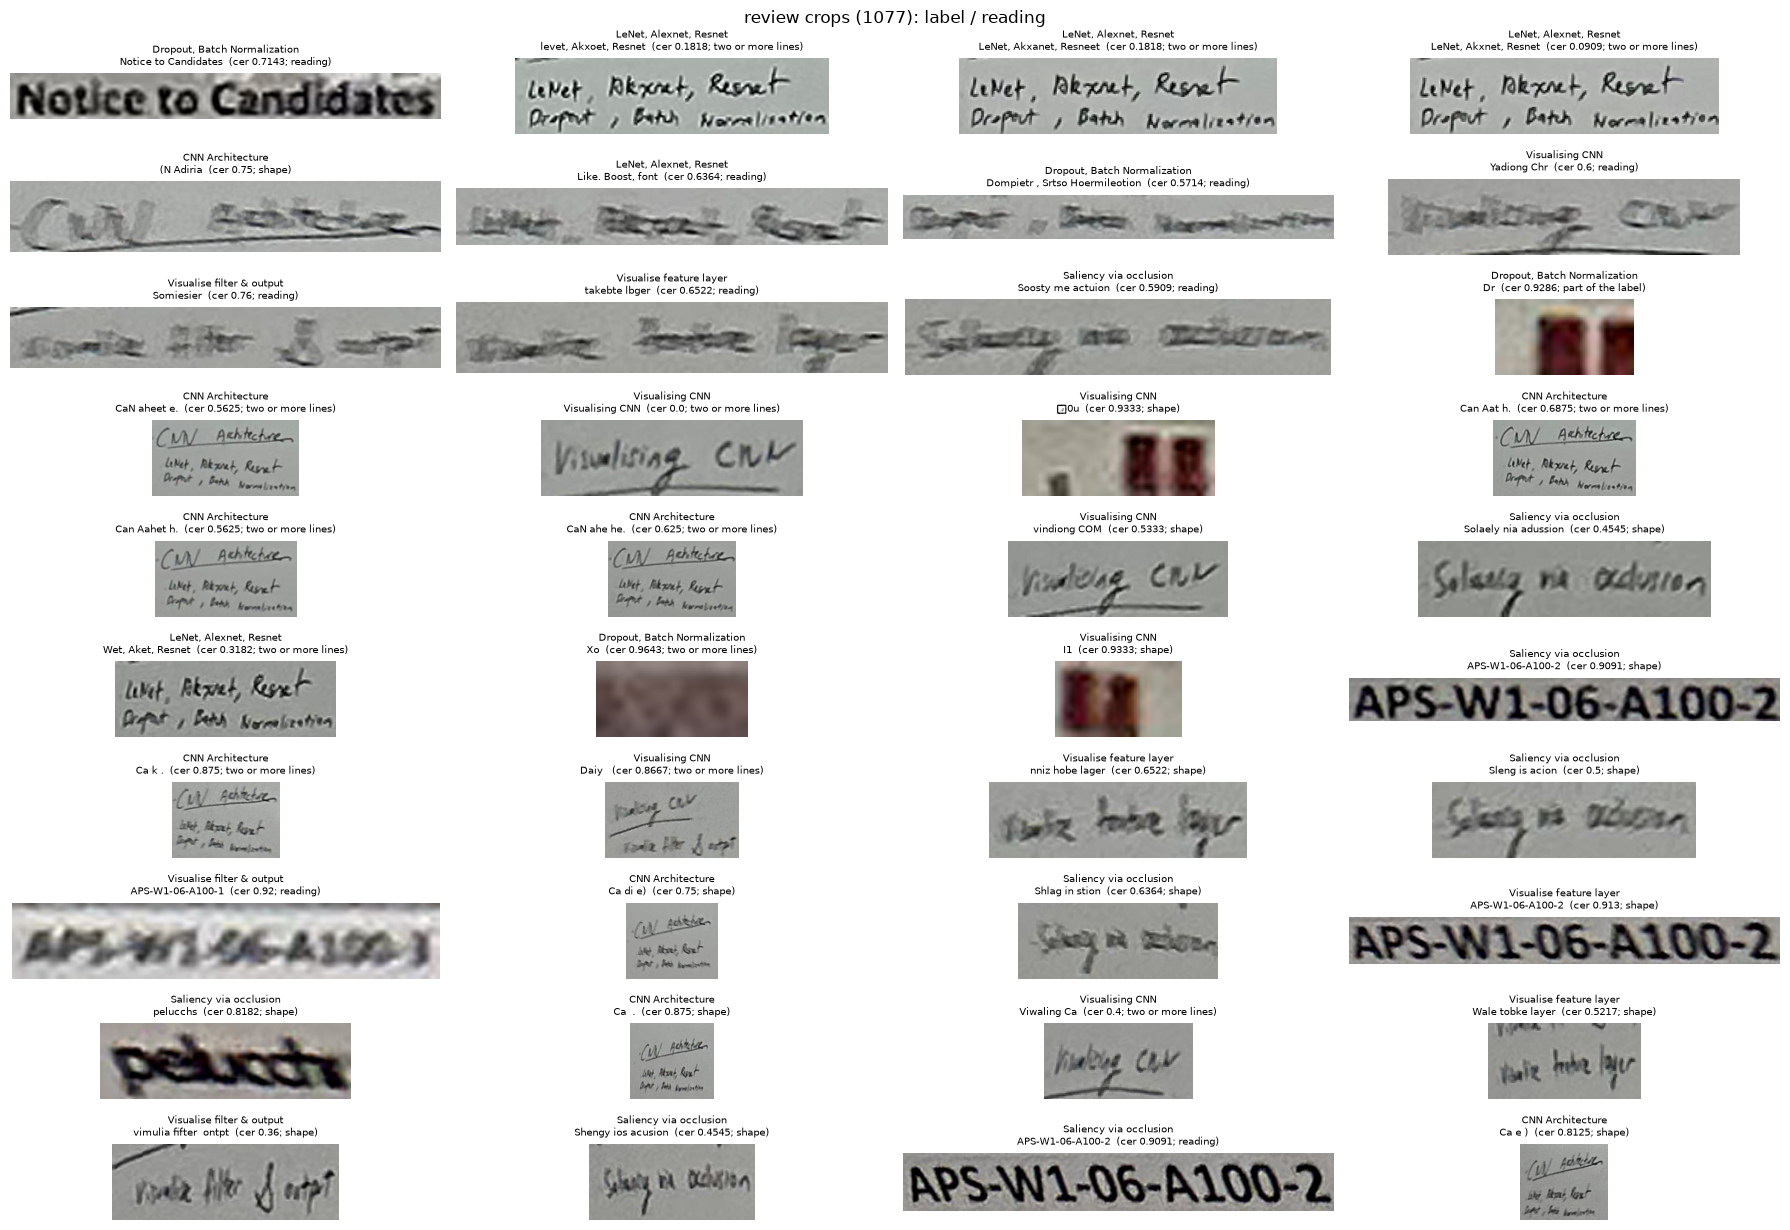

In [19]:
print("re-pairing (old status -> new):", dict(DS.rematch(rows, gt, out_dir=OUT)))
print("crops with two or more text rows (detector merged lines):", sum(int(r.get("text_rows", 1) or 1) > 1 for r in rows))
print("status changed by the dataset-wide shape check:", DS.recheck_shape(rows))
approved_file = OUT / "approved_review.txt"
approved = set(approved_file.read_text().split()) if approved_file.exists() else set()
for r in rows:
    r.setdefault("approved", False)
    if r["status"] == "review" and r["crop"] in approved:
        r["status"] = "accepted"; r["approved"] = True
print(dict(Counter(r["status"] for r in rows)), f"({sum(r['approved'] for r in rows)} approved by hand)")

def contact_sheet(rs, n=None, cols=4, title=""):
    rs = rs[:n or CFG.review_sheet_size]
    if not rs or not CFG.show_figures:
        print("nothing to show" if not rs else "figures off"); return
    nrow = (len(rs) + cols - 1) // cols
    fig, ax = plt.subplots(nrow, cols, figsize=(4.5 * cols, 1.25 * nrow), squeeze=False)
    for a_ in ax.ravel():
        a_.axis("off")
    for a_, r in zip(ax.ravel(), rs):
        im = cv2.imread(str(OUT / r["crop"]))
        if im is None:
            continue
        a_.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        why = r.get("ends") or ("shape" if r.get("shape_ok") in (False, "False") else "reading")
        a_.set_title(f"{r['label'][:34]}\n{r['reading'][:34]}  (cer {r['cer']}; {why})", fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()

review = sorted((r for r in rows if r["status"] == "review"), key=lambda r: (r["photo"], int(r["line_no"])))
contact_sheet(review, title=f"review crops ({len(review)}): label / reading")

## 10. Label files, manifest and checks

One folder, no split (the team splits after merging the datasets). When you split, **split by board, never by crop**: each line was photographed up to 49 times, so a random crop split puts the same sentence in the same handwriting into training and test. The manifest has `board`, `photo`, `repeat_shot_group` and `label` for that, and `suggested_split` with our own rule (train = animal, quiz, lecture, 17 Oct; val = television + `val_text_fraction` of the `val_text_board`'s texts; test = cnn). Make the shrunken small-text copies (`DS.shrink_copy`) after the split, for the training part only.

In [20]:
DS.suggest_split(rows, manifest, CFG.oct17_by_photo, CFG.val_text_board, CFG.val_text_fraction)
counts = DS.write_label_file_all(rows, OUT)
DS.write_manifest(rows, OUT / "manifest.csv")
print("label files:", counts)
c = Counter((r["suggested_split"], r["status"]) for r in rows)
print(f"\n{'suggested split':<16}" + "".join(f"{s:>12}" for s in ("accepted", "review", "unlabelled")))
for sp in ("train", "val", "test"):
    print(f"{sp:<16}" + "".join(f"{c[(sp, s)]:>12}" for s in ("accepted", "review", "unlabelled")))

checks = DS.check_all(rows, OUT)
print()
for name, ok, detail in checks:
    print(f"  {'PASS' if ok else 'FAIL'}  {name}: {detail}")
assert all(ok for _, ok, _ in checks), "a dataset check failed: do not use these files"
long = [r for r in rows if r["status"] == "accepted" and r["ctc_steps"] and r["ctc_steps"] > DS.CTC_SLOTS - DS.CTC_MARGIN]
print(f"accepted labels too long for {DS.CTC_SLOTS} CTC steps: {len(long)} (in labels.txt only)")

import importlib, platform
def version(mod):
    try:
        return importlib.import_module(mod).__version__
    except Exception:
        return None
run_log = dict(finished=time.strftime("%Y-%m-%d %H:%M:%S"), chain=CHOSEN, steps=asdict(STEPS), config=asdict(CFG),
               photos=len(photos), crops=len(rows), status=dict(Counter(r["status"] for r in rows)), files=counts,
               python=platform.python_version(), packages={m: version(m) for m in ("numpy", "cv2", "paddle", "paddleocr", "scipy")})
(OUT / "run_log.json").write_text(json.dumps(run_log, indent=1, default=str))
print("\nwritten:", OUT)

label files: {'labels.txt': 1076, 'labels_ctc38.txt': 1017, 'review.txt': 1077}

suggested split     accepted      review  unlabelled
train                    876         812        2134
val                      106         100          27
test                      94         165         169

  PASS  every crop file exists: 0 missing
  PASS  all crops in one folder: folders: ['crops/all']
  PASS  every labelled crop has a label: 0 empty labels
  PASS  no identical crop with two different labels: 0 clashes
  PASS  grouping columns present for a later split: board, photo, repeat_shot_group, label, suggested_split
accepted labels too long for 40 CTC steps: 59 (in labels.txt only)

written: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/data/board2notes_rec_v2


## 11. Baseline of the reader, and hand-over

The CER of the reader that built the dataset (the app's pretrained PP-OCRv6 unless `CFG.rec_model_dir` is set) on the accepted crops, by board and by photo condition: the number a fine-tuned reader has to beat on the boards it is tested on. The pairing still relies on that reader for most crops (CER <= `accept_cer`), so this baseline is optimistic; the hardest lines are in `review.txt`. The sheet shows accepted crops the old crop set (kept only if CER <= 0.25) would have thrown away.

reader: PP-OCRv6_medium_rec (pretrained)

board         accepted  mean CER  CER > 0.25   texts
animal               3     0.000           0       1
cnn                 94     0.154          15       7
lecture            462     0.073          29     136
oct17              390     0.041           5      73
quiz               101     0.092           6       6
television          26     0.004           0       2

by condition (accepted crops):
  17 Oct close target                           61 crops   CER 0.043   enlarged 0%
  17 Oct far input                             157 crops   CER 0.045   enlarged 68%
  17 Oct medium input                          112 crops   CER 0.017   enlarged 0%
  17 Oct side angle input                       60 crops   CER 0.074   enlarged 50%
  Clean / Control                              170 crops   CER 0.040   enlarged 21%
  Occlusion                                      4 crops   CER 0.072   enlarged 0%
  Perspective Distortion                       240 cro

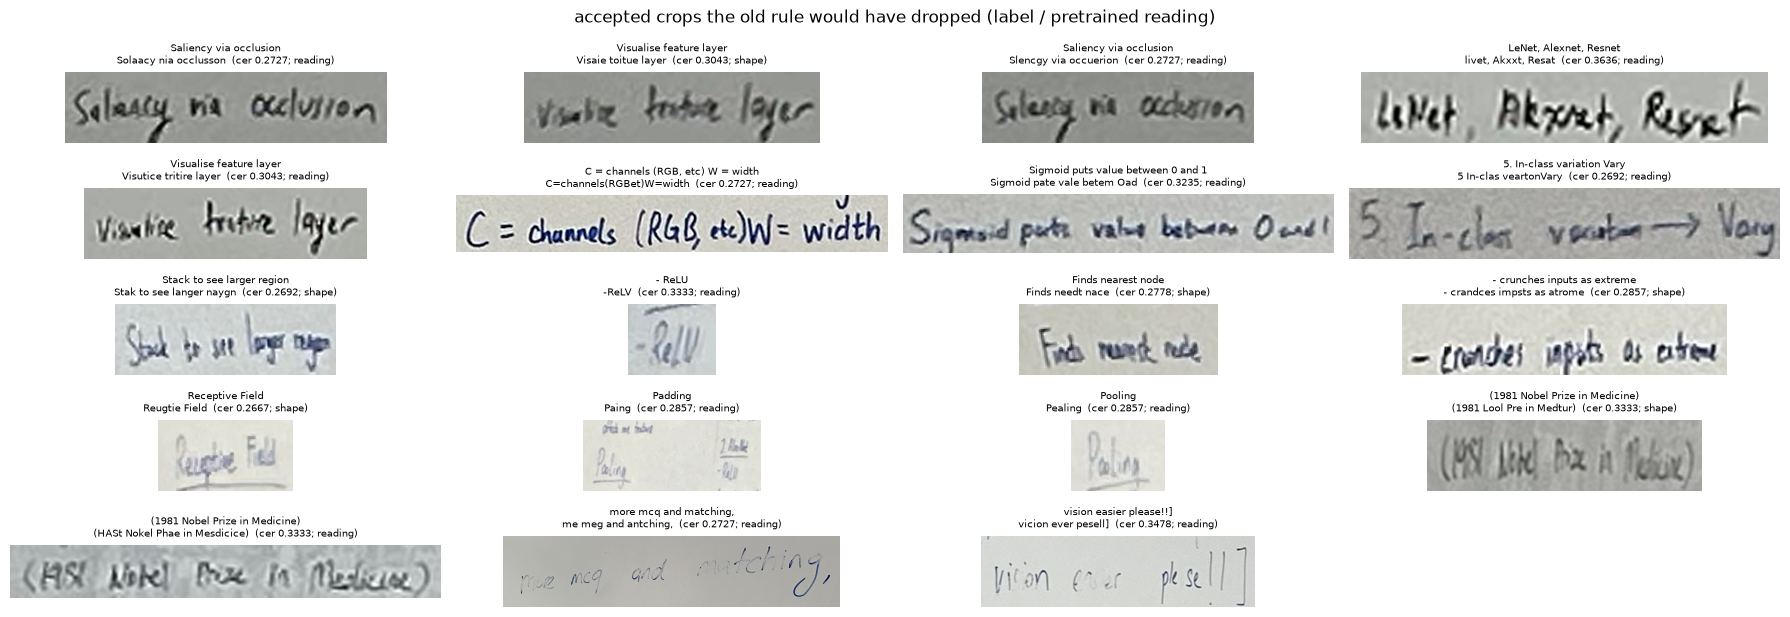


hand-over
  folder      /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment/whiteboard-ocr/data/board2notes_rec_v2
  crops       crops/all/            (4483 crops)
  train on    labels.txt            (1076 accepted)   or labels_ctc38.txt for a 40-step head
  check       review.txt            (1077 doubtful pairings)
  everything  manifest.csv, run_log.json
  next        merge with the other datasets -> split by board -> shrunken copies for training only -> train


In [21]:
def mean_cer(rs):
    v = [r["cer"] for r in rs if r["cer"] is not None]
    return (float(np.mean(v)), len(v)) if v else (float("nan"), 0)

print(f"reader: {CFG.rec_model} ({CFG.rec_model_dir or 'pretrained'})\n")
print(f"{'board':<12}{'accepted':>10}{'mean CER':>10}{'CER > 0.25':>12}{'texts':>8}")
for b in sorted({r["board"] for r in rows}):
    acc = [r for r in rows if r["board"] == b and r["status"] == "accepted"]
    m, n = mean_cer(acc)
    print(f"{b:<12}{n:>10}{m:>10.3f}{sum(r['cer'] is not None and r['cer'] > 0.25 for r in acc):>12}"
          f"{len({r['label'] for r in acc}):>8}")
print("\nby condition (accepted crops):")
by = defaultdict(list)
for r in rows:
    if r["status"] == "accepted":
        by[r["condition"]].append(r)
for c, rs in sorted(by.items()):
    m, n = mean_cer(rs)
    print(f"  {c:<42}{n:>6} crops   CER {m:.3f}   enlarged {sum(bool(r['enlarged']) for r in rs) / n:.0%}")
contact_sheet([r for r in rows if r["status"] == "accepted" and r["cer"] and r["cer"] > 0.25][::3],
              title="accepted crops the old rule would have dropped (label / pretrained reading)")

print(f'''
hand-over
  folder      {OUT}
  crops       crops/all/            ({len(rows)} crops)
  train on    labels.txt            ({counts.get("labels.txt", 0)} accepted)   or labels_ctc38.txt for a {DS.CTC_SLOTS}-step head
  check       review.txt            ({counts.get("review.txt", 0)} doubtful pairings)
  everything  manifest.csv, run_log.json
  next        merge with the other datasets -> split by board -> shrunken copies for training only -> train''')

## 10. Completed preprocessing audit — 30 October 2026

The 52-photo single-step comparison, bounded-lighting trial, 255 fixed-line enlargement comparison and line-grouping experiment are complete. See [the audit and limitations](../docs/PREPROCESSING_AUDIT_2026-10-30.md).

Text-direction grouping fixes a tilted-line merging failure and improved the older non-B3 and long-sentence groups, but slightly worsened B3. It is **optional**, with `Config(group_directional=True)`; the default remains **False**. Restart the kernel before changing settings. The option and embedded code enter the fingerprint. No default chain or training dataset was replaced.

[Single-step results](../outputs/remaining_preprocessing_v1/review.html) · [Bounded lighting and combination](../outputs/remaining_preprocessing_v2/review.html) · [Grouping results](../outputs/line_grouping_revision/review.html)
